### Social Media Use, Perceived Stress and Sleep in Students
#### A Leakage-Controlled and Explainable Supervised Learning Study

**Author:** Christy Treasa Joseph  
**Module:** EAM04DS Machine Learning  
**Institution:** Emirates Aviation University  

#### 0.1 Study Context

This project evaluates whether recorded social media behaviours and demographic characteristics can predict stress-score categories, sleep quality and sleep duration in a publicly available dataset representing students.

The analysis compares interpretable linear and ordinal models with tree-based ensembles. Its emphasis is on appropriate target formulation, leakage-controlled preprocessing, transparent model comparison, uncertainty estimation and critical interpretation.

This is a predictive study of associations within the available dataset. It does not establish that social media use causes stress or sleep degradation.

#### 0.2 Research Objectives

1. Evaluate the predictive performance of social media behaviour and demographic features for stress-score categories.
2. Evaluate the same predictors for sleep quality and sleep duration.
3. Compare interpretable linear and ordinal approaches with flexible tree-based ensembles.
4. Examine whether engineered exposure and interaction features improve development-set performance.
5. Explain model predictions and assess performance variation across demographic and academic-level subgroups.
6. Critically assess uncertainty, dataset provenance and the limits of generalisation.

#### 0.3 Research Questions and Evaluation Criteria
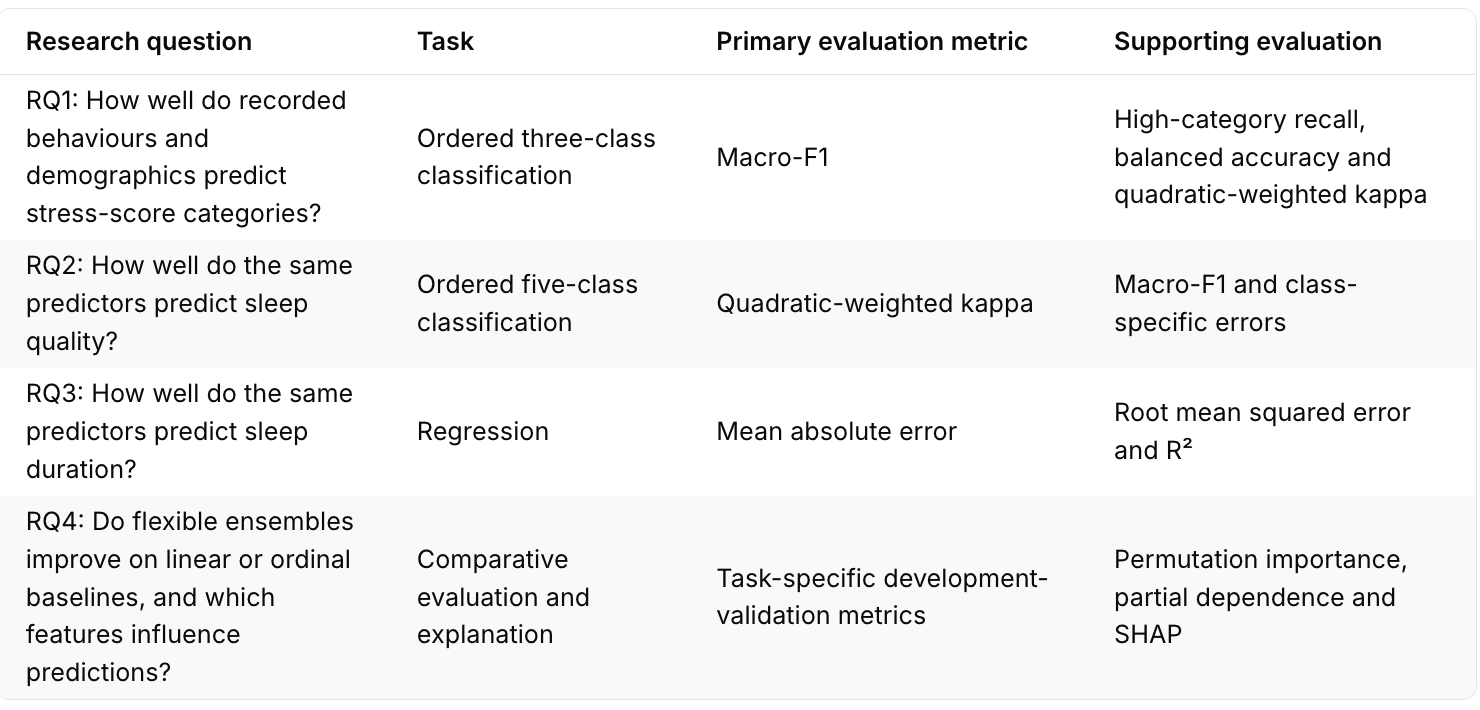

#### 0.4 Dataset Scope and Provenance

The project uses the publicly available Social Media Impact on Life dataset. The loaded file contains 4,500 records and 16 original variables.

The file provides recorded values but does not, by itself, establish participant recruitment, sampling procedures, consent arrangements, questionnaire administration or whether the records were observed, simulated or generated.

Dataset provenance must therefore be assessed using the source documentation. Unless independently documented, this notebook does not describe the records as a representative survey, confirm the use of a validated psychological instrument, or claim that the dataset is synthetic.

The stress categories are analytical score bands, not clinical diagnoses. The interpretation and source of the recorded stress score, together with the justification for its category boundaries, must be documented.

#### 0.5 Methodological Principles

- Preserve the raw data as an audit reference.
- Apply explicit, documented data-integrity rules.
- Exclude identifiers and potentially outcome-derived summary variables from the predictor set.
- Do not use one study outcome as a predictor of another in the primary behavioural prediction tasks.
- Restrict exploratory analyses and model-development decisions to development data after partitioning.
- Fit learned preprocessing within the relevant training folds.
- Perform hyperparameter tuning within inner validation loops when estimating tuned performance through nested cross-validation.
- Use task-appropriate metrics and report minority-class performance.
- Distinguish uncertainty in fixed-model test performance from variability caused by model training and selection.
- Report subgroup performance cautiously where sample sizes or class support are limited.
- Interpret feature explanations as descriptions of model behaviour, not causal effects.

#### 0.6 Evaluation Design

The evaluation follows a strict held-out protocol. All modelling decisions — including feature engineering, preprocessing, model selection and hyperparameter tuning — are made using the development partition only, via nested cross-validation (Section 4.2B). The held-out partition (20% of records) is evaluated once, after all model selections are frozen (Section 4.3A).

This design ensures that the held-out estimates reflect genuine out-of-sample performance and are not influenced by any decisions made during development.

In [1]:
# shap and statsmodels are the only non-default packages used in this notebook
!pip -q install shap statsmodels

import os, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("default")
warnings.filterwarnings("ignore", category=FutureWarning)   # keep ConvergenceWarning and others visible

SEED = 42
random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

CSV = "/content/Social_media_impact_on_life.csv"
if not os.path.exists(CSV):
    from google.colab import files
    files.upload()                      # select Social_media_impact_on_life.csv

df_raw = pd.read_csv(CSV)

# Schema check
EXPECTED = ['Student_ID','Age','Gender','Academic_Level','Primary_Platform','Daily_Usage_Hours',
            'Weekend_Extra_Hours','Device_Type','Sleep_Duration_Hours','Sleep_Quality_Score',
            'Late_Night_Usage','Social_Comparison_Frequency','Perceived_Stress_Score',
            'Mental_Health_Index','Academic_Performance_GPA','Overall_Impact']
missing_cols = set(EXPECTED) - set(df_raw.columns)
assert not missing_cols, f"Missing columns: {missing_cols}"

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 1.1 Dataset dimensions
Confirms the number of records and columns that every later count is checked against.

In [2]:
print("Shape:", df_raw.shape)

Shape: (4500, 16)


### 1.2 First records
A visual check of value formats such as categorical spellings and numeric scales before any cleaning.

In [3]:
display(df_raw.head())

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 1.3 Variable audit: types, cardinality, missingness
A per-column table of data type, number of unique values and missing count. This audit determines the scrubbing rules in Section 2: which columns need encoding, which are identifiers, and where missingness has to be handled.

In [4]:
display(pd.DataFrame({"dtype": df_raw.dtypes, "n_unique": df_raw.nunique(),
                      "n_missing": df_raw.isna().sum(),
                      "pct_missing": (df_raw.isna().mean()*100).round(2)}))

,dtype,n_unique,n_missing,pct_missing
Student_ID,object,4500,0,0.00
Age,int64,12,0,0.00
Gender,object,4,0,0.00
Academic_Level,object,3,0,0.00
Primary_Platform,object,7,0,0.00
Daily_Usage_Hours,float64,129,0,0.00
Weekend_Extra_Hours,float64,43,0,0.00
Device_Type,object,3,0,0.00
Sleep_Duration_Hours,float64,73,0,0.00
Sleep_Quality_Score,int64,5,0,0.00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 2 · Scrub — Data Integrity and Deterministic Preparation

**Purpose.** Prepare the recorded variables for analysis while preserving the original dataset and documenting the assumptions behind each transformation.

This section separates three types of operation:

- **Integrity checks:** identify duplicate records, inconsistent text formatting, missing values and values requiring review.
- **Deterministic transformations:** construct analytical targets and candidate features using fixed rules rather than statistics estimated from the dataset.
- **Learned preprocessing:** defer imputation, scaling and nominal-category encoding to modelling pipelines, where they are fitted using the relevant training folds.

Integrity checks may examine the file before partitioning, but exploratory distributions, associations and data-derived outlier thresholds are reserved for development data after the shared split.

Applying fixed transformations before partitioning does not itself estimate information across records. However, choices informed by previously inspected data remain part of the study’s development history and must be acknowledged.

A working copy, `df`, is used so that `df_raw` remains available as an audit reference.

In [5]:
df = df_raw.copy()

#### 2.1 Duplicate Identifiers and String Hygiene

The integrity check reports exact duplicate rows and repeated `Student_ID` values. The current implementation retains the first record for each identifier and removes leading and trailing whitespace from text fields.

Repeated identifiers require care: they may represent duplicate entries, conflicting records or repeated observations. Retaining the first record is an administrative rule, not evidence that it is the correct observation. If repeated identifiers are reported, execution should be paused and those records reviewed before proceeding.

Verify these counts each time the notebook is executed before proceeding.

In [6]:
# 2.1 Integrity checks
print("Duplicate rows:", df.duplicated().sum(), "| Duplicate IDs:", df.Student_ID.duplicated().sum())
df = df.drop_duplicates(subset="Student_ID")
for c in df.select_dtypes("object"):
    df[c] = df[c].str.strip()

Duplicate rows: 0 | Duplicate IDs: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


#### 2.2 Range and Consistency Checks

The following cell reports values outside the screening intervals already specified in the notebook:
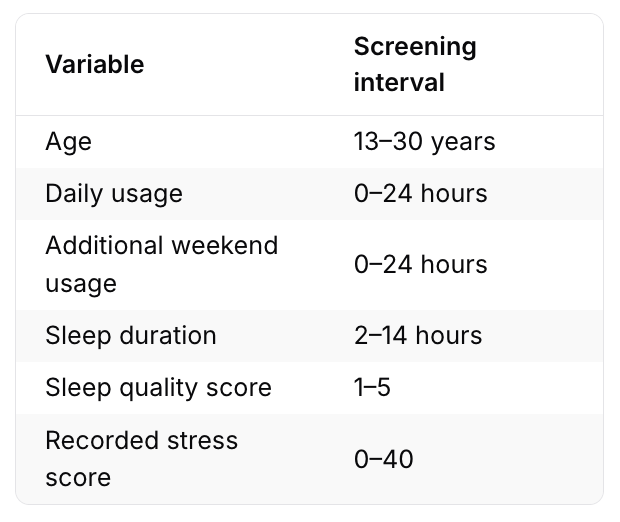

These intervals are analysis assumptions, not independently verified properties of the dataset. In particular, age and sleep-duration values outside these intervals should be reviewed rather than automatically treated as impossible.

The cell reports interval violations; it does not replace them with missing values or remove records.

A separate assertion checks whether daily usage plus additional weekend usage exceeds 24 hours. This check assumes that Weekend_Extra_Hours represents additional usage on a weekend day. That interpretation requires confirmation from the source documentation.

Missing values are audited separately. A value passing a range check is not, by itself, evidence that the measurement is valid.

In [7]:
# 2.2 Plausibility / range checks (rows violating domain limits are reported)
rules = {
    "Age": (13, 30), "Daily_Usage_Hours": (0, 24), "Weekend_Extra_Hours": (0, 24),
    "Sleep_Duration_Hours": (2, 14), "Sleep_Quality_Score": (1, 5),
    "Perceived_Stress_Score": (0, 40),            # PSS-10 range
}
viol = {c: int(((df[c] < lo) | (df[c] > hi)).sum()) for c, (lo, hi) in rules.items()}
print("Out-of-range counts:", viol)
assert (df.Daily_Usage_Hours + df.Weekend_Extra_Hours <= 24).all(), "Impossible total usage"

Out-of-range counts: {'Age': 0, 'Daily_Usage_Hours': 0, 'Weekend_Extra_Hours': 0, 'Sleep_Duration_Hours': 0, 'Sleep_Quality_Score': 0, 'Perceived_Stress_Score': 0}


#### 2.3 Missing-Value Audit

Missing-value counts are reported as an integrity check. These counts do not establish why values are missing or whether the missingness mechanism is random.

Missing predictors will be handled within modelling pipelines using preprocessing fitted only on the relevant training folds.

Missing targets will not be imputed. A record with an unavailable target will be excluded from that particular supervised-learning task, while remaining eligible for other tasks where its target is available.

Development-only missingness patterns and their implications will be examined after partitioning.

In [8]:
# 2.3 Missingness report
print("\nMissing values:\n", df.isna().sum()[df.isna().sum() > 0])


Missing values:
 Perceived_Stress_Score      46
Academic_Performance_GPA    85
dtype: int64


#### 2.4 Analytical Target Definitions

The study defines three prediction tasks:
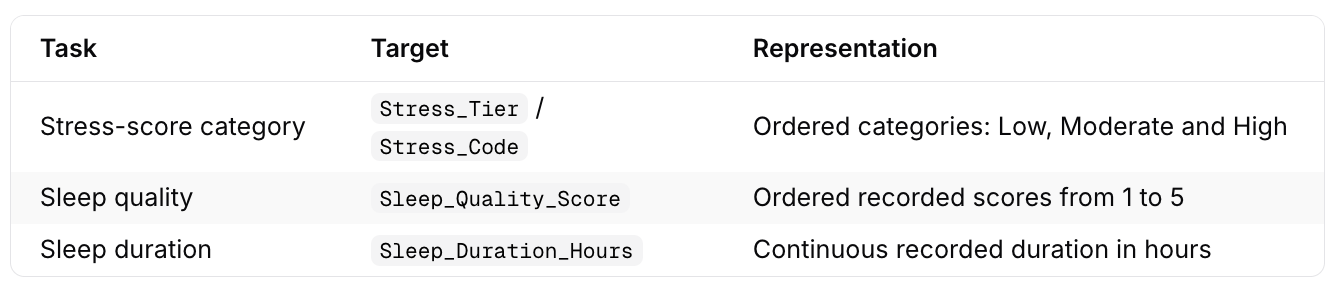
The stress-score boundaries are retained from the original notebook: scores up to 13, above 13 to 26, and above 26 to 40. These are analytical bands used in this study, not clinical diagnoses.

The labels Low, Moderate and High describe relative score bands within this operational definition. Their use does not confirm that the source variable was collected using PSS-10 or that these boundaries have been validated for this dataset.

Stress_Code represents the ordering as 0, 1 and 2. The recorded sleep-quality scores retain their numerical ordering; the meaning of the scale endpoints requires source documentation.

Constructing categories loses information from the original continuous stress score. Consequently, classification results must be interpreted as performance for this particular target definition.

In [9]:
# 2.4 Target definitions
#   PSS-10 cut-offs: 0-13 Low, 14-26 Moderate, 27-40 High
df["Stress_Tier"] = pd.cut(df.Perceived_Stress_Score, bins=[-0.1, 13, 26, 40],
                           labels=["Low", "Moderate", "High"])
df["Stress_Code"] = df.Stress_Tier.map({"Low": 0, "Moderate": 1, "High": 2})

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


#### 2.5 Predictor Exclusions and Outcome Separation

The modelling table excludes:

- `Student_ID`, because it is an identifier rather than a substantive behavioural predictor.
- `Mental_Health_Index`, `Academic_Performance_GPA` and `Overall_Impact`, to maintain the intended behavioural and demographic prediction scope and reduce reliance on potentially outcome-related information.

These exclusions are precautionary. Correlation with an outcome does not automatically constitute leakage, and the available file does not establish that these variables were calculated from the targets.

Across the three primary tasks, stress and sleep outcomes will also be excluded from predictor lists. For example, the stress model will not use sleep quality or sleep duration as predictors.

The modelling code will select predictors explicitly rather than treating every remaining column as an input.

In [10]:
# 2.5 Leakage control (excluded per proposal) + identifier
LEAKY = ["Mental_Health_Index", "Academic_Performance_GPA", "Overall_Impact", "Student_ID"]
df = df.drop(columns=LEAKY)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


#### 2.6 Fixed Ordinal and Binary Encoding

`Social_Comparison_Frequency` is mapped using a fixed ordering:

Never → Rarely → Sometimes → Frequently → Always

The corresponding codes are 0–4. For linear models, treating these codes as a numeric predictor introduces an equal-step assumption on the model’s linear predictor; the ordering alone does not prove that the response categories are equally spaced.

`Late_Night_Usage` is represented as a binary indicator.

These mappings do not estimate parameters from the dataset. Nominal variables will instead be encoded within the modelling pipeline, using categories learned from the relevant training data.

In [11]:
# 2.6 Encoding of ordinal/binary variables
comp_map = {"Never": 0, "Rarely": 1, "Sometimes": 2, "Frequently": 3, "Always": 4}
df["Comparison_Ord"] = df.Social_Comparison_Frequency.map(comp_map)
df["Late_Night_Usage"] = df.Late_Night_Usage.astype(int)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


#### 2.7 Candidate Feature Engineering

The notebook constructs five candidate features using fixed arithmetic rules:
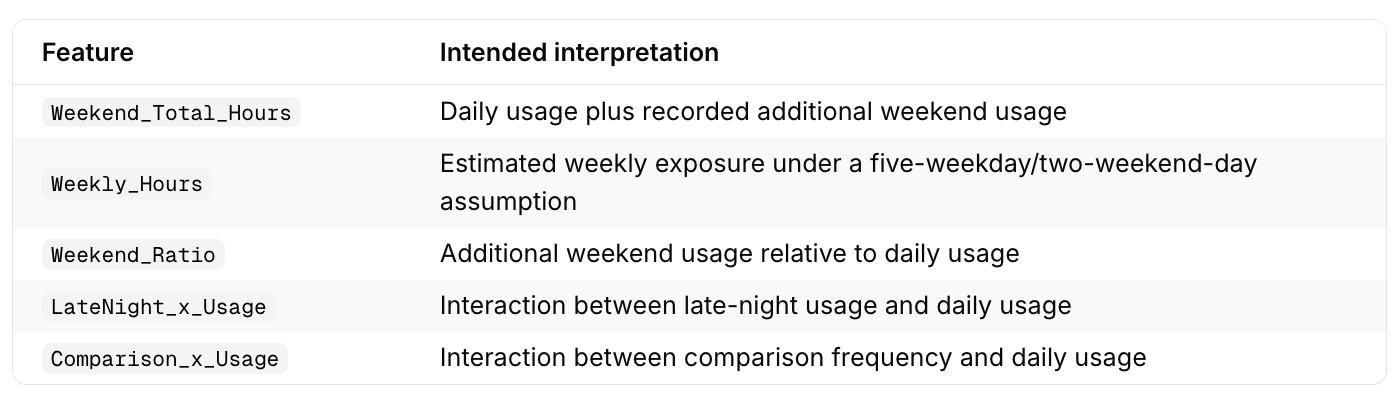
The exposure estimates depend on the interpretation of the original usage variables. They should not be described as directly measured weekly behaviour unless the source documentation supports that interpretation.

A zero daily-usage denominator produces a missing ratio rather than an infinite value. Any required imputation will occur within the modelling pipeline.

These features are deterministic combinations of existing predictors; they introduce alternative representations rather than new measurements. Some are algebraically redundant with the original variables, which can affect coefficient stability and interpretation.

Their inclusion will be evaluated through development-based feature comparisons. No final feature set is declared at this stage.

In [12]:
# 2.7 Feature engineering (stateless, so no leakage across CV folds)
df["Weekend_Total_Hours"] = df.Daily_Usage_Hours + df.Weekend_Extra_Hours
df["Weekly_Hours"] = 5*df.Daily_Usage_Hours + 2*df.Weekend_Total_Hours
df["Weekend_Ratio"] = df.Weekend_Extra_Hours / df.Daily_Usage_Hours.replace(0, np.nan)
df["LateNight_x_Usage"] = df.Late_Night_Usage * df.Daily_Usage_Hours
df["Comparison_x_Usage"] = df.Comparison_Ord * df.Daily_Usage_Hours

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


#### 2.8 Outlier Analysis Deferred Until After Partitioning

Data-derived outlier thresholds are not calculated on the full dataset in this section.

The interquartile-range audit will be performed on development data during exploration. An outlier flag identifies an unusual value relative to that distribution; it does not establish that the value is erroneous.

No observations are removed or capped here on the basis of statistical extremeness. Standardisation changes the scale of a predictor but does not make a model robust to outliers.

If a learned capping or robust-transformation procedure is subsequently evaluated, its parameters must be estimated within the relevant training folds.

In [13]:
# 2.8 Outlier summaries are deferred until after the shared split.
print("Outlier audit deferred to development-only exploration.")

Outlier audit deferred to development-only exploration.


#### 2.9 Explicit Predictor Groups

Categorical, numeric and binary predictor lists are declared centrally so that training, evaluation and interpretation use consistent inputs.

The lists include the candidate engineered features but exclude the study outcomes and previously excluded variables.

Declaring a feature as a candidate does not mean that it has been selected for the final model. Feature-set comparisons will be conducted using development data.

In [14]:
# 2.9 Feature groups (reused in all later sections)
CAT_FEATS = ["Gender", "Academic_Level", "Primary_Platform", "Device_Type"]
NUM_FEATS = ["Age", "Daily_Usage_Hours", "Weekend_Extra_Hours", "Comparison_Ord", "Weekend_Total_Hours",
             "Weekly_Hours", "Weekend_Ratio", "LateNight_x_Usage", "Comparison_x_Usage"]
BIN_FEATS = ["Late_Night_Usage"]
FEATURES = CAT_FEATS + NUM_FEATS + BIN_FEATS

#### 2.10 Preparation for the Shared Partition

The prepared table retains the original row indices for traceability.

The compatibility tables below are not training or evaluation partitions. `df_stress` contains records with a constructed stress target, while `df_sleep` retains the prepared records. Sleep-task eligibility will be checked separately for each sleep outcome after partitioning.

No outcome distributions or subgroup profiles are displayed here.

The next stage creates the shared development/test partition. Subsequent exploration and model development will use development records only. Earlier exposure to test results remains a limitation; rearranging these cells does not undo that history.

In [15]:
# 2.10 Compatibility tables only; these are not development partitions.
df_stress = df.dropna(subset=["Stress_Code"]).copy()
df_sleep = df.copy()

print("Preparation complete. Create the shared partition before exploration.")

Preparation complete. Create the shared partition before exploration.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 3 · Explore — Development-Data Analysis

**Purpose.** Examine outcome balance, predictor distributions, unusual observations and associations using development data.

Exploration provides context for model development; it does not establish causal relationships or confirm that patterns generalise beyond the available dataset.

#### 3.1 Shared Development/Test Partition

A single row-level partition assigns 80% of records to development and 20% to the held-out partition, using `SEED = 42`.

The split is stratified by the analytical stress-score category, with a separate stratum for records whose stress category is unavailable. This approximately preserves the stress-category proportions across the two partitions.

The same partition membership is used across all three prediction tasks. Each task subsequently excludes records with an unavailable target for that task. Sleep quality and sleep duration are not separately stratified.

Original row indices are retained for traceability. Assertions check that the development and held-out partitions do not overlap and together contain all prepared records.

The partition-count table is an administrative check of the stratification, not a comparison used to select models. Subsequent exploratory analysis uses `df_dev` or development-only derivatives, not `df_test`.

**Held-out protocol.** The held-out partition is not used for exploration, feature engineering, model selection or tuning; it is scored once, after all modelling choices are frozen (Section 4.3A).

The row-level split also assumes that records are sufficiently independent. It does not establish generalisation to new institutions, future cohorts or other populations.

In [16]:
# 3.1 Shared development/test split — run before outcome-related EDA

from sklearn.model_selection import train_test_split
from IPython.display import display

assert df.index.is_unique, "Row indices must uniquely identify records."

STRESS_ORDER = ["Low", "Moderate", "High"]
QUALITY_ORDER = [1, 2, 3, 4, 5]

split_strata = (
    df["Stress_Tier"]
    .astype("string")
    .fillna("Missing stress")
)

DEV_IDX, TEST_IDX = train_test_split(
    df.index.to_numpy(),
    test_size=0.20,
    random_state=SEED,
    stratify=split_strata
)

# Preserve original indices for traceability and shared task partitions.
df_dev = df.loc[DEV_IDX].copy()
df_test = df.loc[TEST_IDX].copy()

stress_dev = df_dev.dropna(subset=["Perceived_Stress_Score"]).copy()
sleep_dev = df_dev.copy()

assert set(DEV_IDX).isdisjoint(TEST_IDX)
assert len(df_dev) + len(df_test) == len(df)

# All subsequent exploratory analysis uses development data only.
eda = df_dev.copy()

print(f"Development records: {len(df_dev):,}")
print(f"Held-out records:    {len(df_test):,}")
print(f"Labelled development stress records: {len(stress_dev):,}")
print("\nDo not explore df_test or use it for tuning/model selection.")

split_summary = pd.crosstab(
    split_strata,
    pd.Series(
        np.where(df.index.isin(DEV_IDX), "Development", "Held-out"),
        index=df.index,
        name="Partition"
    )
)
display(split_summary)

Development records: 3,600
Held-out records:    900
Labelled development stress records: 3,563

Do not explore df_test or use it for tuning/model selection.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Partition,Development,Held-out
Stress_Tier,,
High,182,46
Low,1897,474
Missing stress,37,9
Moderate,1484,371


#### 3.1A Development-Only Outlier Audit

The following audit calculates interquartile-range (IQR) screening fences using development records only.

For each continuous variable, values below the first quartile minus 1.5 times the IQR, or above the third quartile plus 1.5 times the IQR, are flagged for review.

Missing values are excluded from the calculation, and flag percentages use the number of non-missing observations for that variable.

These are distribution-based flags, not proof of recording errors. For bounded or skewed variables, valid observations may fall outside the fences.

No records are removed, capped or imputed by this audit. Outcome flags are descriptive only and are not used to exclude difficult-to-predict observations.

If a learned outlier-handling transformation is later compared during modelling, its parameters must be fitted within each training fold rather than reused from this exploratory audit.

In [17]:
# 3.1A Development-only IQR audit — descriptive flags, no modification

audit_columns = [
    "Daily_Usage_Hours",
    "Weekend_Extra_Hours",
    "Sleep_Duration_Hours",
    "Perceived_Stress_Score",
]

audit_rows = []

for column in audit_columns:
    values = df_dev[column].dropna()
    n_observed = len(values)

    if n_observed == 0:
        audit_rows.append({
            "Variable": column,
            "Non_missing_n": 0,
            "Q1": np.nan,
            "Q3": np.nan,
            "IQR": np.nan,
            "Lower_fence": np.nan,
            "Upper_fence": np.nan,
            "Flagged_n": 0,
            "Flagged_percent": np.nan,
        })
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    flagged = (values < lower_fence) | (values > upper_fence)
    n_flagged = int(flagged.sum())

    audit_rows.append({
        "Variable": column,
        "Non_missing_n": n_observed,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_fence": lower_fence,
        "Upper_fence": upper_fence,
        "Flagged_n": n_flagged,
        "Flagged_percent": 100 * n_flagged / n_observed,
    })

development_outlier_audit = pd.DataFrame(audit_rows).set_index("Variable")

display(development_outlier_audit.round(3))
print("Descriptive audit only: no records or values were changed.")

,Non_missing_n,Q1,Q3,IQR,Lower_fence,Upper_fence,Flagged_n,Flagged_percent
Variable,,,,,,,,
Daily_Usage_Hours,3600,3.4,6.6,3.2,-1.40,11.40,134,3.722
Weekend_Extra_Hours,3600,1.3,2.3,1.0,-0.20,3.80,5,0.139
Sleep_Duration_Hours,3600,6.0,7.5,1.5,3.75,9.75,61,1.694
Perceived_Stress_Score,3563,9.0,18.0,9.0,-4.50,31.50,63,1.768


Descriptive audit only: no records or values were changed.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 3.2 Development-Set Outcome Distributions and Subgroup Support

This section summarises target availability and outcome balance using development records only. Counts are calculated separately for each target, so records with a missing stress score do not reduce the sleep-task sample.

Class proportions provide context for interpreting later model metrics. They do not determine model performance, and they are not a reason to remove or rebalance observations automatically.

Subgroup counts are included to show how much data are available for descriptive comparisons. Small groups can produce unstable estimates, so subgroup results should be interpreted cautiously.

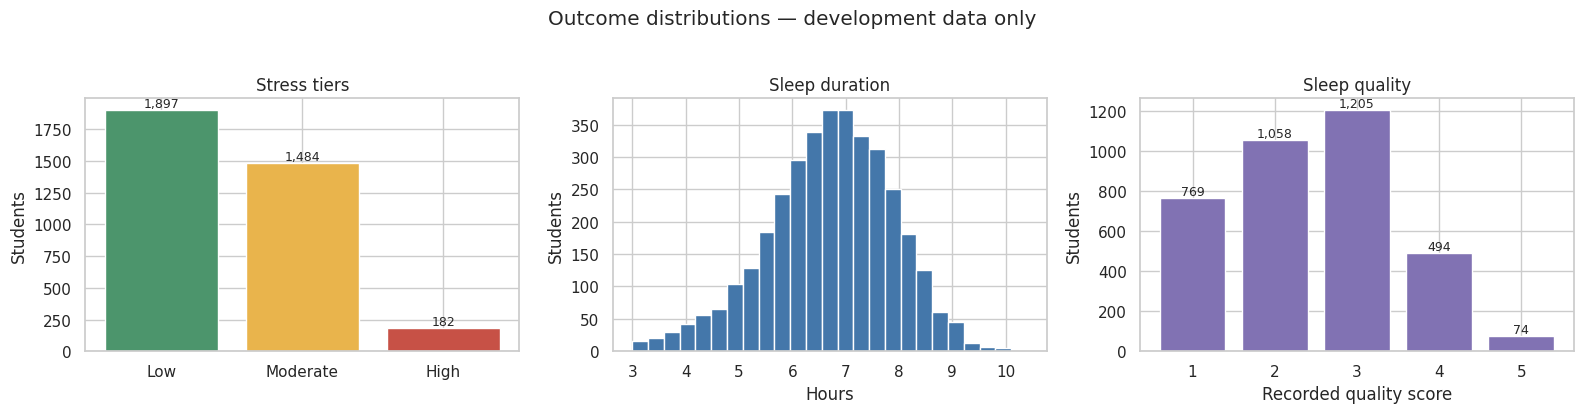

Stress-tier support:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,n,percent
Stress_Tier,,
Low,1897,53.24
Moderate,1484,41.65
High,182,5.11


Sleep duration summary:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Sleep duration (hours)
count,3600.000000
mean,6.697639
std,1.197507
min,3.000000
25%,6.000000
50%,6.800000
75%,7.500000
max,10.400000


... (5 outputs left out)

Stress_Tier,Low,Moderate,High,Labelled_stress_n,All_development_n,High_percent
Academic_Level,,,,,,
High School,641,499,64,1204,1215,5.32
Postgraduate,106,70,10,186,190,5.38
Undergraduate,1150,915,108,2173,2195,4.97


Sleep-quality support:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,n,percent
Sleep_Quality_Score,,
1,769,21.36
2,1058,29.39
3,1205,33.47
4,494,13.72
5,74,2.06


In [18]:
# 3.2 Development-set outcome distributions and subgroup support

stress_counts = (
    stress_dev["Stress_Tier"]
    .value_counts()
    .reindex(STRESS_ORDER, fill_value=0)
)
quality_counts = (
    sleep_dev["Sleep_Quality_Score"]
    .value_counts()
    .reindex(QUALITY_ORDER, fill_value=0)
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].bar(
    STRESS_ORDER, stress_counts,
    color=["#4C956C", "#E9B44C", "#C75146"]
)
axes[0].set(title="Stress tiers", ylabel="Students")

axes[1].hist(
    sleep_dev["Sleep_Duration_Hours"],
    bins=25, color="#4477AA", edgecolor="white"
)
axes[1].set(
    title="Sleep duration",
    xlabel="Hours", ylabel="Students"
)

axes[2].bar(
    [str(v) for v in QUALITY_ORDER],
    quality_counts, color="#8172B3"
)
axes[2].set(
    title="Sleep quality",
    xlabel="Recorded quality score", ylabel="Students"
)

for ax in [axes[0], axes[2]]:
    for bar in ax.patches:
        ax.annotate(
            f"{int(bar.get_height()):,}",
            (bar.get_x() + bar.get_width()/2, bar.get_height()),
            ha="center", va="bottom", fontsize=9
        )

fig.suptitle("Outcome distributions — development data only", y=1.03)
plt.tight_layout()
plt.show()

print("Stress-tier support:")
display(pd.DataFrame({
    "n": stress_counts,
    "percent": (100 * stress_counts / stress_counts.sum()).round(2)
}))

print("Sleep duration summary:")
display(
    sleep_dev["Sleep_Duration_Hours"]
    .describe()
    .to_frame("Sleep duration (hours)")
)

for group in ["Gender", "Academic_Level"]:
    support = pd.crosstab(
        stress_dev[group],
        stress_dev["Stress_Tier"],
        dropna=False
    ).reindex(columns=STRESS_ORDER, fill_value=0)

    support["Labelled_stress_n"] = support.sum(axis=1)
    support["All_development_n"] = eda.groupby(group).size()
    support["High_percent"] = (
        100 * support["High"] / support["Labelled_stress_n"]
    ).round(2)

    print(f"\nSubgroup support: {group}")
    display(support)

    print("Sleep-quality support:")
display(pd.DataFrame({
    "n": quality_counts,
    "percent": (100 * quality_counts / quality_counts.sum()).round(2)
}))

### 3.3 Numeric Predictor Distributions

Histograms and summary statistics describe the development-set distributions of the numeric predictors. They help identify skew, limited variation and unusual values that may affect model choice or interpretation.

These plots are descriptive. They do not establish that an observation is invalid, and no records are removed or transformed here.

,n,stress_n,stress_mean,stress_sd,sleep_mean,sleep_sd,quality_median,stress_ci95,sleep_ci95
Usage_Band,,,,,,,,,
"[0, 2)",109,106,5.670,4.258,7.971,0.876,4.0,0.811,0.164
"[2, 4)",1141,1131,8.955,4.654,7.470,0.850,3.0,0.271,0.049
"[4, 6)",1192,1181,12.632,4.805,6.813,0.861,3.0,0.274,0.049
"[6, 8)",621,613,16.351,4.958,6.208,0.860,2.0,0.393,0.068
"[8, 10)",290,287,20.836,5.108,5.569,0.861,1.0,0.591,0.099
"[10, 12)",141,141,25.028,4.906,4.816,0.818,1.0,0.810,0.135
"[12, 24)",106,104,29.606,5.455,4.231,0.817,1.0,1.048,0.156


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

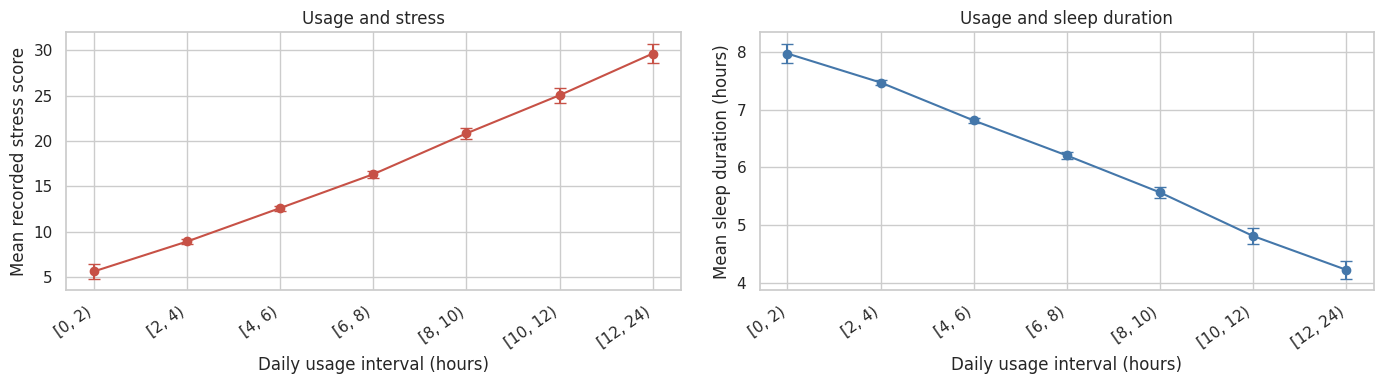


Late-night usage: unadjusted descriptive comparison


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,n,stress_n,daily_usage_mean,stress_mean,sleep_mean,quality_median
Late_Night_Usage,,,,,,
No late-night usage,1469,1455,4.294,11.113,7.092,3.0
Late-night usage,2131,2108,6.045,15.222,6.426,2.0


In [19]:
# 3.3 Usage patterns and outcome associations

eda["Usage_Band"] = pd.cut(
    eda["Daily_Usage_Hours"],
    bins=[0, 2, 4, 6, 8, 10, 12, 24],
    right=False,
    include_lowest=True
)

usage_summary = (
    eda.groupby("Usage_Band", observed=True)
    .agg(
        n=("Daily_Usage_Hours", "size"),
        stress_n=("Perceived_Stress_Score", "count"),
        stress_mean=("Perceived_Stress_Score", "mean"),
        stress_sd=("Perceived_Stress_Score", "std"),
        sleep_mean=("Sleep_Duration_Hours", "mean"),
        sleep_sd=("Sleep_Duration_Hours", "std"),
        quality_median=("Sleep_Quality_Score", "median")
    )
)

# Approximate pointwise 95% confidence intervals for bin means.
# These are descriptive, not simultaneous intervals or causal estimates.
usage_summary["stress_ci95"] = (
    1.96 * usage_summary["stress_sd"]
    / np.sqrt(usage_summary["stress_n"])
)
usage_summary["sleep_ci95"] = (
    1.96 * usage_summary["sleep_sd"]
    / np.sqrt(usage_summary["n"])
)

display(usage_summary.round(3))

x = np.arange(len(usage_summary))
labels = usage_summary.index.astype(str)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, mean_col, ci_col, title, ylabel, color in [
    (
        axes[0], "stress_mean", "stress_ci95",
        "Usage and stress", "Mean recorded stress score", "#C75146"
    ),
    (
        axes[1], "sleep_mean", "sleep_ci95",
        "Usage and sleep duration", "Mean sleep duration (hours)", "#4477AA"
    )
]:
    ax.errorbar(
        x, usage_summary[mean_col],
        yerr=usage_summary[ci_col],
        fmt="o-", capsize=4, color=color
    )
    ax.set(
        title=title,
        xlabel="Daily usage interval (hours)",
        ylabel=ylabel
    )
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=35, ha="right")

plt.tight_layout()
plt.show()

# Separate sample sizes for each outcome avoid treating missing stress as observed.
late_night_summary = (
    eda.groupby("Late_Night_Usage")
    .agg(
        n=("Daily_Usage_Hours", "size"),
        stress_n=("Perceived_Stress_Score", "count"),
        daily_usage_mean=("Daily_Usage_Hours", "mean"),
        stress_mean=("Perceived_Stress_Score", "mean"),
        sleep_mean=("Sleep_Duration_Hours", "mean"),
        quality_median=("Sleep_Quality_Score", "median")
    )
    .rename(index={0: "No late-night usage", 1: "Late-night usage"})
)

print("\nLate-night usage: unadjusted descriptive comparison")
display(late_night_summary.round(3))

### 3.4 Categorical Predictor Profiles

This section reports the development-set counts for categorical predictors. The tables show which categories are represented and whether some are uncommon.

Category counts are descriptive only. Any encoding used for modelling is handled within the model pipeline.

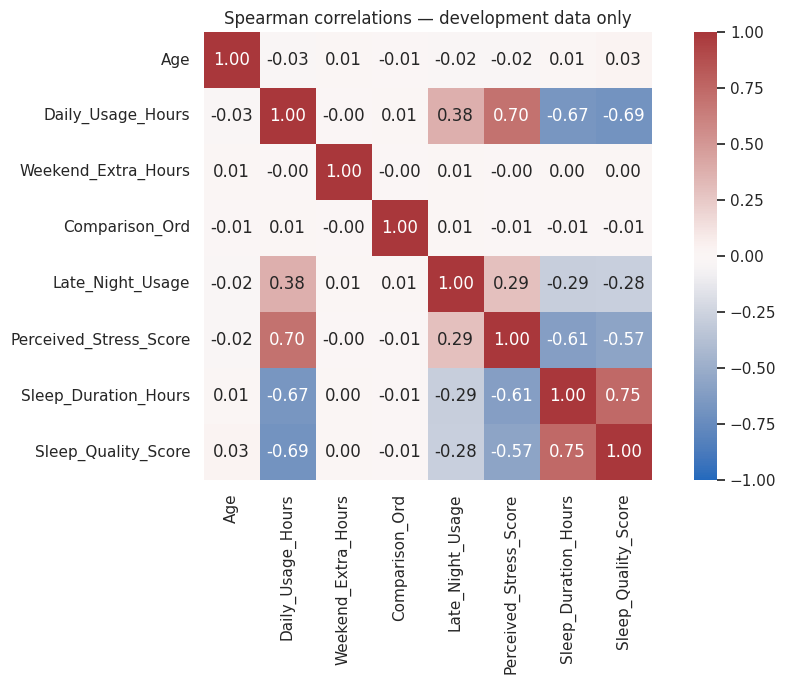

Original predictor–outcome rank correlations:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Perceived_Stress_Score,Sleep_Duration_Hours,Sleep_Quality_Score
Age,-0.017,0.015,0.033
Daily_Usage_Hours,0.702,-0.666,-0.689
Weekend_Extra_Hours,-0.000,0.003,0.001
Comparison_Ord,-0.006,-0.007,-0.006
Late_Night_Usage,0.295,-0.287,-0.280



Strongly correlated feature pairs (|rho| >= 0.85):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Feature_1,Feature_2,Spearman_r,Absolute_r
12,Daily_Usage_Hours,Weekly_Hours,0.995,0.995
30,Weekend_Total_Hours,Weekly_Hours,0.974,0.974
11,Daily_Usage_Hours,Weekend_Total_Hours,0.948,0.948
43,LateNight_x_Usage,Late_Night_Usage,0.882,0.882



Original feature count: 9
Expanded feature count: 14
Weekly/Weekend aggregate features assume Daily_Usage_Hours represents a weekday baseline; confirm this against source documentation.


In [20]:
# 3.4 Rank correlations and feature redundancy

original_numeric = [
    "Age",
    "Daily_Usage_Hours",
    "Weekend_Extra_Hours",
    "Comparison_Ord",
    "Late_Night_Usage"
]
outcomes = [
    "Perceived_Stress_Score",
    "Sleep_Duration_Hours",
    "Sleep_Quality_Score"
]

corr = eda[original_numeric + outcomes].corr(method="spearman")

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr,
    annot=True, fmt=".2f",
    cmap="vlag", center=0, vmin=-1, vmax=1,
    square=True
)
plt.title("Spearman correlations — development data only")
plt.tight_layout()
plt.show()

print("Original predictor–outcome rank correlations:")
display(corr.loc[original_numeric, outcomes].round(3))

# Audit numeric features used by the proposed expanded feature set.
feature_corr = eda[NUM_FEATS + BIN_FEATS].corr(method="spearman")

upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape, dtype=bool), k=1)
)

pairs = (
    upper_triangle.stack()
    .rename("Spearman_r")
    .reset_index()
    .rename(columns={"level_0": "Feature_1", "level_1": "Feature_2"})
)
pairs["Absolute_r"] = pairs["Spearman_r"].abs()

print("\nStrongly correlated feature pairs (|rho| >= 0.85):")
display(
    pairs.loc[pairs["Absolute_r"] >= 0.85]
    .sort_values("Absolute_r", ascending=False)
    .round(3)
)

# Two candidate feature sets for a later CV-based ablation.
BASE_FEATURES = CAT_FEATS + original_numeric
ENGINEERED_FEATURES = FEATURES.copy()

assert len(BASE_FEATURES) == len(set(BASE_FEATURES))
assert len(ENGINEERED_FEATURES) == len(set(ENGINEERED_FEATURES))

print("\nOriginal feature count:", len(BASE_FEATURES))
print("Expanded feature count:", len(ENGINEERED_FEATURES))
print(
    "Weekly/Weekend aggregate features assume Daily_Usage_Hours "
    "represents a weekday baseline; confirm this against source documentation."
)

### 3.5 Exploratory Associations

Plots and association summaries in this subsection use development data only. They are used to describe patterns that may inform modelling and interpretation.

Observed associations are not causal effects. Where correlations are calculated, the variables and analysis sample should be stated, and correlations involving the derived stress categories should be interpreted cautiously.

In [21]:
# 3.5 Platform profiles and stress-label missingness

platform_summary = (
    eda.groupby("Primary_Platform")
    .agg(
        n=("Daily_Usage_Hours", "size"),
        stress_n=("Perceived_Stress_Score", "count"),
        usage_mean=("Daily_Usage_Hours", "mean"),
        late_night_percent=("Late_Night_Usage", lambda s: 100 * s.mean()),
        stress_mean=("Perceived_Stress_Score", "mean"),
        sleep_mean=("Sleep_Duration_Hours", "mean"),
        quality_median=("Sleep_Quality_Score", "median")
    )
    .sort_values("n", ascending=False)
)

print("Platform profiles — unadjusted, not platform-specific causal effects:")
display(platform_summary.round(3))

missing_audit = eda.assign(
    Stress_Missing=eda["Perceived_Stress_Score"].isna()
)

for group in ["Gender", "Academic_Level", "Primary_Platform"]:
    table = (
        missing_audit.groupby(group)
        .agg(
            n=("Stress_Missing", "size"),
            missing_stress_n=("Stress_Missing", "sum"),
            missing_stress_percent=("Stress_Missing", lambda s: 100 * s.mean())
        )
        .sort_values("missing_stress_percent", ascending=False)
    )
    print(f"\nMissing stress labels by {group}:")
    display(table.round(2))

print("\nPredictor summaries by stress-label availability:")
display(
    missing_audit.groupby("Stress_Missing")[
        ["Age", "Daily_Usage_Hours", "Weekend_Extra_Hours", "Late_Night_Usage"]
    ].agg(["count", "mean", "std"]).round(3)
)

print(
    "\nThis audit can reveal observed missingness patterns, "
    "but cannot prove that labels are missing completely at random."
)

Platform profiles — unadjusted, not platform-specific causal effects:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,n,stress_n,usage_mean,late_night_percent,stress_mean,sleep_mean,quality_median
Primary_Platform,,,,,,,
Instagram,1146,1134,5.320,58.377,13.534,6.702,2.0
TikTok,975,963,5.352,59.692,13.536,6.671,2.0
YouTube,651,646,5.295,58.986,13.477,6.730,3.0
Snapchat,382,381,5.474,60.471,14.060,6.679,2.0
Reddit,190,188,5.205,57.368,13.452,6.649,2.0
X (Twitter),176,172,5.232,63.068,12.610,6.774,3.0
LinkedIn,80,79,5.341,56.250,14.101,6.740,2.0



Missing stress labels by Gender:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,n,missing_stress_n,missing_stress_percent
Gender,,,
Non-Binary,100,2,2.00
Female,1775,20,1.13
Male,1645,15,0.91
Prefer not to say,80,0,0.00


... (6 outputs left out)


Predictor summaries by stress-label availability:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Age                Daily_Usage_Hours                \
               count    mean    std             count   mean    std   
Stress_Missing                                                        
False           3563  18.647  1.959              3563  5.332  2.608   
True              37  19.189  2.246                37  5.186  2.744   

               Weekend_Extra_Hours               Late_Night_Usage         \
                             count   mean    std            count   mean   
Stress_Missing                                                             
False                         3563  1.794  0.696             3563  0.592   
True                            37  1.792  0.675               37  0.622   

                       
                  std  
Stress_Missing         
False           0.492  
True            0.492


This audit can reveal observed missingness patterns, but cannot prove that labels are missing completely at random.


### 3.6 Descriptive Group Comparisons

Group summaries compare recorded outcomes across development-set usage or platform groups. Report the group sizes alongside summary values because uneven or small groups can make apparent differences unreliable.

These comparisons are exploratory and do not imply that platform choice or usage caused differences in stress or sleep.

In [22]:
# 3.6 Descriptive group comparisons (development data only)

MIN_GROUP_N = 30  # groups below this are flagged, not interpreted

def group_profile(group_col):
    out = (
        eda.groupby(group_col, observed=True)
        .agg(
            n=("Daily_Usage_Hours", "size"),
            stress_n=("Perceived_Stress_Score", "count"),
            usage_mean=("Daily_Usage_Hours", "mean"),
            late_night_percent=("Late_Night_Usage", lambda s: 100 * s.mean()),
            stress_mean=("Perceived_Stress_Score", "mean"),
            sleep_mean=("Sleep_Duration_Hours", "mean"),
            quality_median=("Sleep_Quality_Score", "median"),
        )
        .sort_values("n", ascending=False)
    )
    out["Interpretation_flag"] = np.where(
        out["n"] < MIN_GROUP_N, "Small group: descriptive only", ""
    )
    return out.round(3)

for group in ["Primary_Platform", "Device_Type", "Social_Comparison_Frequency"]:
    print(f"\nDescriptive profile by {group} (unadjusted, not causal):")
    display(group_profile(group))

# Share of High-stress students by platform, with group sizes
high_by_platform = (
    stress_dev.groupby("Primary_Platform", observed=True)["Stress_Tier"]
    .agg(
        labelled_n="size",
        high_n=lambda s: (s == "High").sum(),
    )
)
high_by_platform["High_percent"] = (
    100 * high_by_platform["high_n"] / high_by_platform["labelled_n"]
).round(2)

print("\nHigh-stress share by platform:")
display(high_by_platform.sort_values("labelled_n", ascending=False))

print(
    "\nThese comparisons are exploratory and unadjusted. "
    "Groups below the minimum size are flagged and should not be interpreted."
)


Descriptive profile by Primary_Platform (unadjusted, not causal):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,n,stress_n,usage_mean,late_night_percent,stress_mean,sleep_mean,quality_median,Interpretation_flag
Primary_Platform,,,,,,,,
Instagram,1146,1134,5.320,58.377,13.534,6.702,2.0,
TikTok,975,963,5.352,59.692,13.536,6.671,2.0,
YouTube,651,646,5.295,58.986,13.477,6.730,3.0,
Snapchat,382,381,5.474,60.471,14.060,6.679,2.0,
Reddit,190,188,5.205,57.368,13.452,6.649,2.0,
X (Twitter),176,172,5.232,63.068,12.610,6.774,3.0,
LinkedIn,80,79,5.341,56.250,14.101,6.740,2.0,



Descriptive profile by Device_Type (unadjusted, not causal):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,n,stress_n,usage_mean,late_night_percent,stress_mean,sleep_mean,quality_median,Interpretation_flag
Device_Type,,,,,,,,
Smartphone,3023,2993,5.326,59.246,13.525,6.698,2.0,
Laptop/PC,475,470,5.364,59.368,13.681,6.703,2.0,
Tablet,102,100,5.314,56.863,13.470,6.664,3.0,


... (4 outputs left out)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,labelled_n,high_n,High_percent
Primary_Platform,,,
Instagram,1134,58,5.11
TikTok,963,53,5.50
YouTube,646,34,5.26
Snapchat,381,23,6.04
Reddit,188,9,4.79
X (Twitter),172,2,1.16
LinkedIn,79,3,3.80



These comparisons are exploratory and unadjusted. Groups below the minimum size are flagged and should not be interpreted.


# 4 · MODEL
### 4.1 Pipelines, model registry, baselines and repeated cross-validation
**Purpose.** Define every candidate model inside a leakage-safe `Pipeline` and get a first comparison across feature sets.

**Components.**
- **`make_pre`** — a `ColumnTransformer` with median/most-frequent imputation, standardisation for numeric inputs and one-hot encoding for nominals. It is refitted inside every training fold.
- **Custom `OrdinalLogit`** — a scikit-learn-compatible wrapper around `statsmodels` `OrderedModel` (proportional-odds logit; McCullagh, 1980). It respects the ordering of stress and sleep-quality labels.
- **Registries** — classifiers: Logistic (L2), Ordinal logit, Random Forest, HistGradientBoosting, plus naive baselines. Regressors: Elastic Net, Random Forest, HistGB, plus a mean baseline.
- **Metrics** — Macro-F1, per-class recall, balanced accuracy, QWK, Brier score and log loss for classification; MAE, RMSE and R² for regression.
- **Repeated stratified 5-fold × 3 CV** (15 folds) on **development data only**. Results are stored in `cv_results`.

**Why.** Repeating the CV reduces the variance of a single split. Including naive baselines makes "better than chance" an explicit, testable statement.

In [23]:
import time
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, ElasticNetCV
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import (f1_score, balanced_accuracy_score, cohen_kappa_score, log_loss,
                             recall_score, mean_absolute_error, mean_squared_error, r2_score)

ENGINEERED_ONLY = {"Weekend_Total_Hours","Weekly_Hours","Weekend_Ratio","LateNight_x_Usage","Comparison_x_Usage"}

def make_pre(features, scale=False, drop=None):
    cats = [f for f in features if f in CAT_FEATS]
    nums = [f for f in features if f not in CAT_FEATS]
    ns = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    tr = [("num", Pipeline(ns), nums)]
    if cats:
        tr.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                    ("oh", OneHotEncoder(handle_unknown="ignore", drop=drop, sparse_output=False))]), cats))
    return ColumnTransformer(tr)

class OrdinalLogit(BaseEstimator, ClassifierMixin):
    """Proportional-odds logistic regression (statsmodels) with a sklearn interface."""
    def __init__(self, maxiter=500):
        self.maxiter = maxiter
    def _df(self, X):
        X = np.asarray(X); return pd.DataFrame(X, columns=[f"x{i}" for i in range(X.shape[1])])
    def fit(self, X, y):
        from statsmodels.miscmodels.ordinal_model import OrderedModel
        self.classes_ = np.unique(y)
        yy = pd.Series(pd.Categorical(np.asarray(y), categories=self.classes_, ordered=True))
        self.res_ = OrderedModel(yy, self._df(X), distr="logit").fit(method="bfgs", disp=False, maxiter=self.maxiter)
        return self
    def predict_proba(self, X):
        return np.asarray(self.res_.model.predict(self.res_.params, exog=self._df(X)))
    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]

# ---- Metrics ----
def clf_metrics(y, pred, proba, labels):
    y, pred = np.asarray(y), np.asarray(pred)
    oh = (y[:, None] == np.array(labels)[None, :]).astype(float)
    out = {"macro_f1": f1_score(y, pred, average="macro", labels=labels, zero_division=0),
           "bal_acc": balanced_accuracy_score(y, pred),
           "qwk": cohen_kappa_score(y, pred, weights="quadratic", labels=labels),
           "ord_mae": np.mean(np.abs(y - pred)),
           "brier": np.mean(np.sum((proba - oh) ** 2, axis=1)),
           "logloss": log_loss(y, proba, labels=labels)}
    for l, r in zip(labels, recall_score(y, pred, average=None, labels=labels, zero_division=0)):
        out[f"recall_{l}"] = r
    return out

def reg_metrics(y, pred):
    return {"mae": mean_absolute_error(y, pred), "rmse": mean_squared_error(y, pred) ** .5, "r2": r2_score(y, pred)}

# ---- Model registries ----
def clf_registry(f):
    rf = dict(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
    reg = {
        "Dummy (prior)": lambda: Pipeline([("pre", make_pre(f)), ("m", DummyClassifier(strategy="prior"))]),
        "Logistic (L2)": lambda: Pipeline([("pre", make_pre(f, scale=True)),
                                           ("m", LogisticRegression(C=1.0, max_iter=3000, class_weight="balanced"))]),
        "Random Forest": lambda: Pipeline([("pre", make_pre(f)), ("m", RandomForestClassifier(**rf))]),
        "HistGB": lambda: Pipeline([("pre", make_pre(f)),
                                    ("m", HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300,
                                                                         early_stopping=False, class_weight="balanced",
                                                                         random_state=SEED))]),
    }
    if not set(f) & ENGINEERED_ONLY:      # ordinal logit only on non-collinear base features
        reg["Ordinal logit"] = lambda: Pipeline([("pre", make_pre(f, scale=True, drop="first")), ("m", OrdinalLogit())])
    return reg

def reg_registry(f):
    return {
        "Dummy (mean)": lambda: Pipeline([("pre", make_pre(f)), ("m", DummyRegressor())]),
        "Elastic Net": lambda: Pipeline([("pre", make_pre(f, scale=True)),
                                         ("m", ElasticNetCV(l1_ratio=[.1, .5, .9], cv=5, max_iter=10000))]),
        "Random Forest": lambda: Pipeline([("pre", make_pre(f)),
                                           ("m", RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=SEED))]),
        "HistGB": lambda: Pipeline([("pre", make_pre(f)),
                                    ("m", HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300,
                                                                        early_stopping=False, random_state=SEED))]),
    }

# ---- Tasks and fixed CV splits (identical folds for every model => paired comparisons) ----
FEATURE_SETS = {"Usage only": ["Daily_Usage_Hours"], "Base": BASE_FEATURES, "Engineered": ENGINEERED_FEATURES}
N_SPLITS, N_REPEATS = 5, 3

_s = stress_dev.reset_index(drop=True)
_l = sleep_dev.reset_index(drop=True)
TASKS = {
    "Stress tier":    dict(kind="clf", data=_s, y=_s["Stress_Code"].astype(int).to_numpy(), labels=[0, 1, 2]),
    "Sleep quality":  dict(kind="clf", data=_l, y=_l["Sleep_Quality_Score"].to_numpy(),     labels=[1, 2, 3, 4, 5]),
    "Sleep duration": dict(kind="reg", data=_l, y=_l["Sleep_Duration_Hours"].to_numpy()),
}
strat = {"Stress tier": TASKS["Stress tier"]["y"],
         "Sleep quality": TASKS["Sleep quality"]["y"],
         "Sleep duration": pd.qcut(_l["Sleep_Duration_Hours"], 5, labels=False).to_numpy()}
for k, t in TASKS.items():
    t["splits"] = list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
                       .split(np.zeros(len(strat[k])), strat[k]))

def run_cv(task_name, fset_name, model_name):
    t = TASKS[task_name]; f = FEATURE_SETS[fset_name]; X = t["data"][f]; y = t["y"]
    make = (clf_registry if t["kind"] == "clf" else reg_registry)(f)[model_name]
    rows = []
    for k, (tr, va) in enumerate(t["splits"]):
        m = make().fit(X.iloc[tr], y[tr])
        met = (clf_metrics(y[va], m.predict(X.iloc[va]), m.predict_proba(X.iloc[va]), t["labels"])
               if t["kind"] == "clf" else reg_metrics(y[va], m.predict(X.iloc[va])))
        rows.append({"task": task_name, "features": fset_name, "model": model_name, "fold": k, **met})
    return rows

# ---- Run everything ----
t0, rows = time.time(), []
for tn, t in TASKS.items():
    for fs, f in FEATURE_SETS.items():
        for mn in (clf_registry if t["kind"] == "clf" else reg_registry)(f):
            rows += run_cv(tn, fs, mn)
    print(f"{tn} done ({time.time()-t0:.0f}s)")
cv_results = pd.DataFrame(rows)
cv_results.to_csv("cv_results_baseline.csv", index=False)

# ---- Summaries: mean ± SD across the 15 folds ----
def summarise(task, cols):
    d = cv_results[cv_results.task == task].groupby(["features", "model"])[cols]
    m, s = d.mean(), d.std()
    return m.round(3).astype(str) + " ± " + s.round(3).astype(str)

print("\nSTRESS TIER");    display(summarise("Stress tier",    ["macro_f1", "qwk", "recall_2", "bal_acc", "brier"]))
print("\nSLEEP QUALITY");  display(summarise("Sleep quality",  ["qwk", "macro_f1", "ord_mae", "bal_acc", "brier"]))
print("\nSLEEP DURATION"); display(summarise("Sleep duration", ["mae", "rmse", "r2"]))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

Stress tier done (157s)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.

Sleep quality done (324s)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Sleep duration done (411s)

STRESS TIER


... (4 outputs left out)

qwk       macro_f1        ord_mae  \
features   model                                                        
Base       Dummy (prior)      0.0 ± 0.0      0.1 ± 0.0  0.899 ± 0.001   
           HistGB         0.595 ± 0.019   0.38 ± 0.014  0.731 ± 0.025   
           Logistic (L2)   0.608 ± 0.02  0.387 ± 0.012  0.756 ± 0.022   
           Ordinal logit  0.635 ± 0.014  0.379 ± 0.011  0.545 ± 0.015   
           Random Forest  0.627 ± 0.027  0.401 ± 0.021   0.66 ± 0.031   
Engineered Dummy (prior)      0.0 ± 0.0      0.1 ± 0.0  0.899 ± 0.001   
           HistGB         0.598 ± 0.021  0.384 ± 0.019  0.707 ± 0.031   
           Logistic (L2)  0.607 ± 0.021  0.384 ± 0.012  0.755 ± 0.021   
           Random Forest   0.63 ± 0.023  0.399 ± 0.023  0.646 ± 0.029   
Usage only Dummy (prior)      0.0 ± 0.0      0.1 ± 0.0  0.899 ± 0.001   
           HistGB          0.586 ± 0.02  0.381 ± 0.015  0.784 ± 0.036   
           Logistic (L2)  0.619 ± 0.022  0.377 ± 0.016   0.751 ± 0.03   
           Ordinal logit  0.634 ± 0.017  0.379 ± 0.013  0.544 ± 0.018   
           Random Forest  0.579 ± 0.019  0.378 ± 0.017  0.788 ± 0.036   

                                bal_acc          brier  
features   model                                        
Base       Dummy (prior)      0.2 ± 0.0    0.737 ± 0.0  
           HistGB         0.422 ± 0.022  0.664 ± 0.015  
           Logistic (L2)  0.466 ± 0.018  0.664 ± 0.011  
           Ordinal logit   0.377 ± 0.01  0.593 ± 0.011  
           Random Forest  0.427 ± 0.025  0.637 ± 0.009  
Engineered Dummy (prior)      0.2 ± 0.0    0.737 ± 0.0  
           HistGB         0.413 ± 0.024  0.657 ± 0.014  
           Logistic (L2)   0.459 ± 0.02  0.665 ± 0.011  
           Random Forest  0.411 ± 0.024  0.625 ± 0.012  
Usage only Dummy (prior)      0.2 ± 0.0    0.737 ± 0.0  
           HistGB         0.462 ± 0.027  0.669 ± 0.009  
           Logistic (L2)   0.46 ± 0.036   0.658 ± 0.01  
           Ordinal logit  0.376 ± 0.012  0.592 ± 0.011  
           Random Forest  0.451 ± 0.031   0.668 ± 0.01


SLEEP DURATION


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


mae           rmse             r2
features   model                                                     
Base       Dummy (mean)   0.949 ± 0.011  1.197 ± 0.016     -0.0 ± 0.0
           Elastic Net    0.676 ± 0.011  0.836 ± 0.014  0.513 ± 0.018
           HistGB          0.688 ± 0.01  0.851 ± 0.013  0.495 ± 0.019
           Random Forest  0.693 ± 0.015  0.857 ± 0.017  0.487 ± 0.021
Engineered Dummy (mean)   0.949 ± 0.011  1.197 ± 0.016     -0.0 ± 0.0
           Elastic Net    0.676 ± 0.011  0.836 ± 0.014  0.512 ± 0.018
           HistGB         0.691 ± 0.011  0.854 ± 0.015  0.491 ± 0.021
           Random Forest  0.696 ± 0.014  0.862 ± 0.017  0.481 ± 0.021
Usage only Dummy (mean)   0.949 ± 0.011  1.197 ± 0.016     -0.0 ± 0.0
           Elastic Net    0.676 ± 0.012  0.836 ± 0.015  0.512 ± 0.019
           HistGB         0.684 ± 0.011  0.846 ± 0.013  0.501 ± 0.018
           Random Forest  0.691 ± 0.011  0.855 ± 0.013   0.49 ± 0.018

### 4.2A Feature-set ablation (descriptive)
Summarises mean ± SD repeated-CV performance for each model and feature set ("Usage only", "Base", extended sets). It answers whether engineered features or extra predictors improve performance beyond daily usage.

**Methodological note.** This study does not run Wilcoxon signed-rank tests on repeated-CV fold scores, and it does not tune models with non-nested CV, for two reasons:
- Fold scores from repeated CV share training data and are **not independent**. Standard paired tests on them have an inflated Type I error rate (Nadeau & Bengio, 2003; Bouckaert & Frank, 2004).
- Tuning hyperparameters and estimating performance on the same folds is **optimistically biased** (Cawley & Talbot, 2010; Varma & Simon, 2006).

Tuned model comparison is therefore done with **nested CV** in 4.2B. This ablation is read descriptively, using mean differences relative to fold-to-fold SD.

In [24]:
# ============ SECTION 4.2A: FEATURE-SET ABLATION (DESCRIPTIVE) ============
# Mean repeated-CV metrics by model and feature set (development data only).
# No hypothesis tests or tuning are run here: the 15 repeated-CV folds share
# training records, so fold scores are not independent (Nadeau & Bengio, 2003;
# Bouckaert & Frank, 2004), and tuning outside an outer loop is optimistically
# biased (Cawley & Talbot, 2010). Tuned comparison is done in nested CV (4.2B).
import pandas as pd

ablation_stress = (
    cv_results[cv_results["task"] == "Stress tier"]
    .groupby(["model", "features"])[["macro_f1", "recall_2", "qwk", "brier"]]
    .agg(["mean", "std"])
    .round(4)
)
print("STRESS TIER — feature-set ablation (mean and SD across 15 folds)")
display(ablation_stress)

ablation_duration = (
    cv_results[cv_results["task"] == "Sleep duration"]
    .groupby(["model", "features"])[["mae", "rmse", "r2"]]
    .agg(["mean", "std"])
    .round(4)
)
print("SLEEP DURATION — feature-set ablation (mean and SD across 15 folds)")
display(ablation_duration)

if "Sleep quality" in set(cv_results["task"]):
    qcols = [c for c in ["qwk", "macro_f1", "ord_mae"] if c in cv_results.columns]
    ablation_quality = (
        cv_results[cv_results["task"] == "Sleep quality"]
        .groupby(["model", "features"])[qcols]
        .agg(["mean", "std"])
        .round(4)
    )
    print("SLEEP QUALITY — feature-set ablation (mean and SD across 15 folds)")
    display(ablation_quality)

print("Ablation is descriptive. Model selection uses the nested comparison in 4.2B.")


STRESS TIER — feature-set ablation (mean and SD across 15 folds)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


macro_f1         recall_2             qwk          \
                             mean     std     mean     std    mean     std   
model         features                                                       
Dummy (prior) Base         0.2316  0.0002   0.0000  0.0000  0.0000  0.0000   
              Engineered   0.2316  0.0002   0.0000  0.0000  0.0000  0.0000   
              Usage only   0.2316  0.0002   0.0000  0.0000  0.0000  0.0000   
HistGB        Base         0.6326  0.0203   0.7285  0.0705  0.5746  0.0275   
              Engineered   0.6486  0.0173   0.7158  0.0692  0.5813  0.0281   
              Usage only   0.6127  0.0166   0.8531  0.0663  0.5941  0.0267   
Logistic (L2) Base         0.6290  0.0151   0.8330  0.0584  0.5917  0.0230   
              Engineered   0.6269  0.0130   0.8439  0.0577  0.5906  0.0220   
              Usage only   0.6394  0.0179   0.8734  0.0565  0.6035  0.0231   
Ordinal logit Base         0.6567  0.0247   0.4356  0.0814  0.5761  0.0247   
              Usage only   0.6542  0.0239   0.4338  0.0795  0.5749  0.0248   
Random Forest Base         0.6404  0.0181   0.8073  0.0553  0.5872  0.0216   
              Engineered   0.6561  0.0161   0.7672  0.0723  0.5910  0.0242   
              Usage only   0.6255  0.0177   0.8020  0.0674  0.5943  0.0283   

                           brier          
                            mean     std  
model         features                    
Dummy (prior) Base        0.5404  0.0005  
              Engineered  0.5404  0.0005  
              Usage only  0.5404  0.0005  
HistGB        Base        0.4277  0.0169  
              Engineered  0.4178  0.0145  
              Usage only  0.4352  0.0175  
Logistic (L2) Base        0.4292  0.0147  
              Engineered  0.4316  0.0148  
              Usage only  0.4269  0.0157  
Ordinal logit Base        0.3835  0.0166  
              Usage only  0.3814  0.0163  
Random Forest Base        0.4256  0.0100  
              Engineered  0.4093  0.0135  
              Usage only  0.4315  0.0174

SLEEP DURATION — feature-set ablation (mean and SD across 15 folds)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


mae            rmse              r2        
                            mean     std    mean     std    mean     std
model         features                                                  
Dummy (mean)  Base        0.9490  0.0112  1.1973  0.0162 -0.0002  0.0003
              Engineered  0.9490  0.0112  1.1973  0.0162 -0.0002  0.0003
              Usage only  0.9490  0.0112  1.1973  0.0162 -0.0002  0.0003
Elastic Net   Base        0.6757  0.0112  0.8356  0.0144  0.5126  0.0183
              Engineered  0.6758  0.0111  0.8357  0.0142  0.5124  0.0179
              Usage only  0.6761  0.0116  0.8362  0.0148  0.5119  0.0192
HistGB        Base        0.6885  0.0103  0.8507  0.0133  0.4948  0.0187
              Engineered  0.6909  0.0112  0.8536  0.0149  0.4913  0.0205
              Usage only  0.6836  0.0105  0.8458  0.0126  0.5006  0.0180
Random Forest Base        0.6926  0.0147  0.8574  0.0169  0.4867  0.0213
              Engineered  0.6958  0.0144  0.8623  0.0165  0.4808  0.0213
              Usage only  0.6905  0.0112  0.8550  0.0125  0.4897  0.0179

SLEEP QUALITY — feature-set ablation (mean and SD across 15 folds)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


qwk         macro_f1         ord_mae        
                            mean     std     mean     std    mean     std
model         features                                                   
Dummy (prior) Base        0.0000  0.0000   0.1003  0.0000  0.8994  0.0007
              Engineered  0.0000  0.0000   0.1003  0.0000  0.8994  0.0007
              Usage only  0.0000  0.0000   0.1003  0.0000  0.8994  0.0007
HistGB        Base        0.5951  0.0187   0.3803  0.0138  0.7308  0.0249
              Engineered  0.5985  0.0210   0.3838  0.0189  0.7069  0.0314
              Usage only  0.5858  0.0197   0.3808  0.0150  0.7844  0.0358
Logistic (L2) Base        0.6076  0.0200   0.3871  0.0117  0.7561  0.0223
              Engineered  0.6069  0.0205   0.3840  0.0122  0.7554  0.0211
              Usage only  0.6192  0.0224   0.3774  0.0159  0.7511  0.0297
Ordinal logit Base        0.6350  0.0144   0.3791  0.0113  0.5449  0.0150
              Usage only  0.6345  0.0166   0.3785  0.0134  0.5437  0.0176
Random Forest Base        0.6266  0.0273   0.4010  0.0214  0.6602  0.0314
              Engineered  0.6301  0.0232   0.3994  0.0225  0.6456  0.0287
              Usage only  0.5793  0.0186   0.3784  0.0172  0.7877  0.0356

Ablation is descriptive. Model selection uses the nested comparison in 4.2B.


### 4.2B Nested development-only model comparison
**Purpose.** Estimate generalisation performance for all candidate models on development data only, using nested cross-validation. This is the primary model-comparison evidence.

**Method.** The outer loop is the 15-fold repeated stratified CV. An inner 3-fold `GridSearchCV` tunes hyperparameters using only the outer training fold.
- **Stress:** Logistic (Usage only), Logistic (Base), Ordinal logit (Base), tuned HistGB (Base).
- **Sleep quality:** Ordinal logit (Base), tuned Random Forest (Base).
- **Duration:** Elastic Net (Usage only) vs Elastic Net (Base). Preprocessing and `ElasticNet` hyperparameters (`alpha`, `l1_ratio`) are tuned together by an inner 5-fold search on each outer training fold, using MAE.

Selection rules are fixed in the code before the held-out evaluation in 4.3B runs: highest mean Macro-F1 (stress), highest mean QWK (sleep quality), lowest mean MAE (duration). The held-out partition plays no part in these selections (see 0.6). Results are reported as mean ± SD.

**Key observation.** The ordinal logit had the highest mean nested-CV score on both classification tasks, and the tuned tree ensembles did not exceed it. In 4.3A the margin to the runner-up is printed next to the winner's fold-to-fold SD. Differences smaller than that SD should not be read as clear superiority. The proposal's hypothesis that boosting beats linear baselines is therefore **not supported in these development results**. A plausible, untested explanation is that the signal is dominated by one mostly monotonic predictor.

In [25]:
# ============ SECTION 4.2B: DEVELOPMENT-ONLY NESTED MODEL COMPARISON ============
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, cohen_kappa_score
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# Candidate classifiers for stress
stress_candidates = {
    "Logistic — Usage only": {
        "features": FEATURE_SETS["Usage only"],
        "make_model": lambda f: clf_registry(f)["Logistic (L2)"],
        "param_grid": None,
        "tune_metric": None,
    },
    "Logistic — Base": {
        "features": FEATURE_SETS["Base"],
        "make_model": lambda f: clf_registry(f)["Logistic (L2)"],
        "param_grid": None,
        "tune_metric": None,
    },
    "Ordinal logit — Base": {
        "features": FEATURE_SETS["Base"],
        "make_model": lambda f: clf_registry(f)["Ordinal logit"],
        "param_grid": None,
        "tune_metric": None,
    },
    "HistGB — tuned Base": {
        "features": FEATURE_SETS["Base"],
        "make_model": lambda f: lambda: Pipeline([
            ("pre", make_pre(f)),
            ("m", HistGradientBoostingClassifier(
                class_weight="balanced",
                random_state=SEED
            ))
        ]),
        "param_grid": {
            "m__learning_rate": [0.03, 0.1],
            "m__max_leaf_nodes": [15, 31],
            "m__min_samples_leaf": [10],
            "m__l2_regularization": [0.0, 1.0],
        },
        "tune_metric": "f1_macro",
    },
}

# Candidate classifiers for sleep quality
sleep_quality_candidates = {
    "Ordinal logit — Base": {
        "features": FEATURE_SETS["Base"],
        "make_model": lambda f: clf_registry(f)["Ordinal logit"],
        "param_grid": None,
        "tune_metric": None,
    },
    "Random Forest — tuned Base": {
        "features": FEATURE_SETS["Base"],
        "make_model": lambda f: lambda: Pipeline([
            ("pre", make_pre(f)),
            ("m", RandomForestClassifier(
                random_state=SEED,
                n_jobs=-1
            ))
        ]),
        "param_grid": {
            "m__n_estimators": [150, 250],
            "m__max_depth": [6, None],
            "m__min_samples_leaf": [5],
        },
        "tune_metric": "qwk",
    },
}

def nested_classification_comparison(task_name, candidates, labels):
    task = TASKS[task_name]
    data = task["data"]
    y = task["y"]
    results = []

    for fold_id, (train_idx, valid_idx) in enumerate(task["splits"]):
        y_train, y_valid = y[train_idx], y[valid_idx]

        for candidate_name, spec in candidates.items():
            features = spec["features"]
            X_train = data.iloc[train_idx][features]
            X_valid = data.iloc[valid_idx][features]

            model_factory = spec["make_model"](features)
            model = model_factory()

            if spec["param_grid"] is not None:
                inner_cv = StratifiedKFold(
                    n_splits=3,
                    shuffle=True,
                    random_state=SEED + fold_id
                )

                if spec["tune_metric"] == "qwk":
                    scorer = make_scorer(
                        cohen_kappa_score,
                        weights="quadratic",
                        labels=labels
                    )
                else:
                    scorer = spec["tune_metric"]

                search = GridSearchCV(
                    estimator=model,
                    param_grid=spec["param_grid"],
                    scoring=scorer,
                    cv=inner_cv,
                    n_jobs=1,
                    refit=True,
                    error_score="raise"
                )
                search.fit(X_train, y_train)
                fitted_model = search.best_estimator_
                best_params = search.best_params_
            else:
                fitted_model = model.fit(X_train, y_train)
                best_params = None

            pred = fitted_model.predict(X_valid)
            proba = fitted_model.predict_proba(X_valid)
            metrics = clf_metrics(y_valid, pred, proba, labels)

            results.append({
                "task": task_name,
                "candidate": candidate_name,
                "fold": fold_id,
                "best_params": best_params,
                **metrics
            })

        print(f"{task_name}: completed outer fold {fold_id + 1}/{len(task['splits'])}")

    return pd.DataFrame(results)

# Stress uses encoded labels: 0 = Low, 1 = Moderate, 2 = High
stress_nested_results = nested_classification_comparison(
    "Stress tier",
    stress_candidates,
    labels=[0, 1, 2]
)

# Sleep quality uses the recorded ordinal scores 1–5
quality_nested_results = nested_classification_comparison(
    "Sleep quality",
    sleep_quality_candidates,
    labels=[1, 2, 3, 4, 5]
)

# Sleep duration: preprocessing + ElasticNet are tuned together inside each outer training fold,
# so imputation/scaling/encoding are refitted in every inner fold (no preprocessing leakage).
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import KFold

ENET_GRID = {"m__alpha": np.logspace(-3, 0, 10), "m__l1_ratio": [0.1, 0.5, 0.9]}

def make_enet_search(features, seed):
    pipe = Pipeline([("pre", make_pre(features, scale=True)),
                     ("m", ElasticNet(max_iter=20000))])
    return GridSearchCV(pipe, ENET_GRID, scoring="neg_mean_absolute_error",
                        cv=KFold(5, shuffle=True, random_state=seed),
                        n_jobs=1, refit=True, error_score="raise")

duration_candidates = {
    "Elastic Net — Usage only": list(FEATURE_SETS["Usage only"]),
    "Elastic Net — Base": list(FEATURE_SETS["Base"]),
}

duration_results = []
duration_task = TASKS["Sleep duration"]

for fold_id, (train_idx, valid_idx) in enumerate(duration_task["splits"]):
    y_train = duration_task["y"][train_idx]
    y_valid = duration_task["y"][valid_idx]

    for candidate_name, features in duration_candidates.items():
        search = make_enet_search(features, SEED + fold_id)
        search.fit(duration_task["data"].iloc[train_idx][features], y_train)
        pred = search.best_estimator_.predict(duration_task["data"].iloc[valid_idx][features])

        duration_results.append({
            "task": "Sleep duration",
            "candidate": candidate_name,
            "fold": fold_id,
            "best_params": search.best_params_,
            **reg_metrics(y_valid, pred)
        })

    print(f"Sleep duration: completed outer fold {fold_id + 1}/{len(duration_task['splits'])}")

duration_nested_results = pd.DataFrame(duration_results)

# Summarise fold-level results as mean ± SD.
# These are descriptive repeated-CV summaries; do not treat the folds as
# independent observations for significance testing.
def show_nested_summary(results, metrics):
    summary = results.groupby("candidate")[metrics].agg(["mean", "std"])
    formatted = pd.DataFrame(index=summary.index)

    for metric in metrics:
        formatted[metric] = (
            summary[(metric, "mean")].round(3).astype(str)
            + " ± "
            + summary[(metric, "std")].round(3).astype(str)
        )

    display(formatted)

print("\nSTRESS — nested repeated-CV results")
show_nested_summary(
    stress_nested_results,
    ["macro_f1", "recall_2", "qwk", "bal_acc", "brier"]
)

print("\nSLEEP QUALITY — nested repeated-CV results")
show_nested_summary(
    quality_nested_results,
    ["qwk", "macro_f1", "ord_mae", "brier"]
)

print("\nSLEEP DURATION — nested repeated-CV results")
show_nested_summary(
    duration_nested_results,
    ["mae", "rmse", "r2"]
)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.

Stress tier: completed outer fold 1/15


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Stress tier: completed outer fold 2/15


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Stress tier: completed outer fold 3/15


... (88 outputs left out)

,qwk,macro_f1,ord_mae,brier
candidate,,,,
Ordinal logit — Base,0.635 ± 0.014,0.379 ± 0.011,0.545 ± 0.015,0.593 ± 0.011
Random Forest — tuned Base,0.585 ± 0.021,0.336 ± 0.022,0.579 ± 0.021,0.616 ± 0.012



SLEEP DURATION — nested repeated-CV results


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,mae,rmse,r2
candidate,,,
Elastic Net — Base,0.676 ± 0.011,0.836 ± 0.014,0.512 ± 0.018
Elastic Net — Usage only,0.676 ± 0.011,0.836 ± 0.015,0.512 ± 0.019


### 4.2C Academic-cohort transfer sensitivity analysis
**Question.** Do the non-demographic-level predictors transfer when an entire academic cohort is unseen?

**Design.** Development data only. Each academic level is held out in turn; preprocessing and tuning use the remaining cohorts only. `Academic_Level` is excluded from the predictors in every fold, because an unseen category cannot have its own effect estimated. Columns that are constant in the training cohorts are dropped and listed. Each result is paired with a dummy baseline, and sample sizes, class support, failures and small-support caveats are shown explicitly.

**Interpretation.** This is an *internal transfer stress test*, not external validation, and it is not directly comparable with the random-split CV (different training population and feature set). It does not show that academic level causes performance differences.

In [26]:
# ==== SECTION 4.2C: ACADEMIC-COHORT TRANSFER SENSITIVITY ANALYSIS (development data only) ====
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import f1_score, cohen_kappa_score, mean_absolute_error, r2_score

COHORT_COL = "Academic_Level"
cohort_base = [f for f in FEATURE_SETS["Base"] if f != COHORT_COL]   # Academic_Level excluded in every fold

def support_str(y, labels):
    return ", ".join(f"{l}:{int((y == l).sum())}" for l in labels)

def recall_of(y, pred, label):
    mask = y == label
    return float((pred[mask] == label).mean()) if mask.any() else np.nan

rows = []
for task_name in ["Stress tier", "Sleep quality", "Sleep duration"]:
    task = TASKS[task_name]
    data, y_all, kind, labels = task["data"], np.asarray(task["y"]), task["kind"], task.get("labels")

    for cohort in sorted(data[COHORT_COL].dropna().unique()):
        te = (data[COHORT_COL] == cohort).to_numpy()
        tr = ~te
        y_tr, y_te = y_all[tr], y_all[te]
        row = {"Held-out cohort": cohort, "Task": task_name,
               "Training sample": int(tr.sum()), "Evaluation sample": int(te.sum()),
               "Class support": support_str(y_te, labels) if labels else "n/a (continuous)"}

        # consistent feature set; any column constant in the training cohorts is dropped and reported
        feats = [f for f in cohort_base if data.loc[tr, f].nunique(dropna=True) > 1]
        row["Features dropped (constant in training)"] = ", ".join(sorted(set(cohort_base) - set(feats))) or "none"

        try:
            if kind == "clf":
                if set(np.unique(y_tr)) != set(labels):
                    raise ValueError(f"training cohorts lack classes {sorted(set(labels) - set(np.unique(y_tr)))}")
                model = Pipeline([("pre", make_pre(feats, scale=True, drop="first")), ("m", OrdinalLogit())])
                dummy = Pipeline([("pre", make_pre(feats)), ("m", DummyClassifier(strategy="prior"))])
                model.fit(data.loc[tr, feats], y_tr)
                dummy.fit(data.loc[tr, feats], y_tr)
                if not model.named_steps["m"].res_.mle_retvals.get("converged", False):
                    raise RuntimeError("ordinal optimiser did not converge")
                p_m, p_d = model.predict(data.loc[te, feats]), dummy.predict(data.loc[te, feats])
                present = [l for l in labels if (y_te == l).any()]   # absent classes would bias Macro-F1 down

                if task_name == "Stress tier":
                    row.update({"Primary metric": "Macro-F1",
                                "Model": f1_score(y_te, p_m, average="macro", labels=present, zero_division=0),
                                "Dummy baseline": f1_score(y_te, p_d, average="macro", labels=present, zero_division=0),
                                "Secondary": f"QWK={cohen_kappa_score(y_te, p_m, weights='quadratic', labels=labels):.3f}; "
                                             f"High recall={recall_of(y_te, p_m, 2):.3f}"})
                else:
                    row.update({"Primary metric": "QWK",
                                "Model": cohen_kappa_score(y_te, p_m, weights="quadratic", labels=labels),
                                "Dummy baseline": cohen_kappa_score(y_te, p_d, weights="quadratic", labels=labels),
                                "Secondary": f"Macro-F1={f1_score(y_te, p_m, average='macro', labels=present, zero_division=0):.3f}"})
                min_support = min((y_te == l).sum() for l in present)
            else:
                search = make_enet_search(feats, SEED)
                search.fit(data.loc[tr, feats], y_tr)
                dummy = Pipeline([("pre", make_pre(feats)), ("m", DummyRegressor())]).fit(data.loc[tr, feats], y_tr)
                p_m, p_d = search.best_estimator_.predict(data.loc[te, feats]), dummy.predict(data.loc[te, feats])
                row.update({"Primary metric": "MAE (h, lower is better)",
                            "Model": mean_absolute_error(y_te, p_m),
                            "Dummy baseline": mean_absolute_error(y_te, p_d),
                            "Secondary": f"R2={r2_score(y_te, p_m):.3f}"})
                min_support = len(y_te)
            row["Status"] = "ok"
            cav = []
            if te.sum() < 100: cav.append("small evaluation cohort")
            if min_support < 10: cav.append("minority class support < 10; metric unstable")
            row["Caveat"] = "; ".join(cav) or "none flagged"
        except Exception as e:
            row.update({"Status": f"FAILED: {type(e).__name__}: {e}", "Caveat": "fold not estimable; reported, not omitted"})
        rows.append(row)

cohort_transfer_results = pd.DataFrame(rows)
cohort_transfer_results.to_csv("cohort_transfer_results.csv", index=False)
display(cohort_transfer_results.round(3))

print("Interpretation: this is an internal transfer stress test on development data, not external validation. "
      "Training populations and feature sets differ from the random-split CV (Academic_Level is excluded), "
      "so the numbers are not like-for-like with 4.2B. Differences between cohorts do not show that academic level "
      "causes performance differences.")

,Held-out cohort,Task,Training sample,Evaluation sample,Class support,Features dropped (constant in training),Primary metric,Model,Dummy baseline,Secondary,Status,Caveat
0,High School,Stress tier,2359,1204,"0:641, 1:499, 2:64",none,Macro-F1,0.693,0.232,QWK=0.593; High recall=0.578,ok,none flagged
1,Postgraduate,Stress tier,3377,186,"0:106, 1:70, 2:10",none,Macro-F1,0.621,0.242,QWK=0.543; High recall=0.400,ok,none flagged
2,Undergraduate,Stress tier,1390,2173,"0:1150, 1:915, 2:108",none,Macro-F1,0.627,0.231,QWK=0.564; High recall=0.343,ok,none flagged
3,High School,Sleep quality,2385,1215,"1:266, 2:383, 3:380, 4:163, 5:23",none,QWK,0.618,0.000,Macro-F1=0.381,ok,none flagged
4,Postgraduate,Sleep quality,3410,190,"1:37, 2:50, 3:66, 4:35, 5:2",none,QWK,0.647,0.000,Macro-F1=0.377,ok,minority class support < 10; metric unstable
5,Undergraduate,Sleep quality,1405,2195,"1:466, 2:625, 3:759, 4:296, 5:49",none,QWK,0.641,0.000,Macro-F1=0.399,ok,none flagged
6,High School,Sleep duration,2385,1215,n/a (continuous),none,"MAE (h, lower is better)",0.689,0.962,R2=0.501,ok,none flagged
7,Postgraduate,Sleep duration,3410,190,n/a (continuous),none,"MAE (h, lower is better)",0.627,0.937,R2=0.565,ok,none flagged
8,Undergraduate,Sleep duration,1405,2195,n/a (continuous),none,"MAE (h, lower is better)",0.672,0.944,R2=0.515,ok,none flagged


Interpretation: this is an internal transfer stress test on development data, not external validation. Training populations and feature sets differ from the random-split CV (Academic_Level is excluded), so the numbers are not like-for-like with 4.2B. Differences between cohorts do not show that academic level causes performance differences.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 4.2D Proportional-odds sensitivity analysis
The ordinal logit assumes one slope per predictor across all cumulative thresholds. This diagnostic fits separate binary logits for each threshold (`y > k`) on identically preprocessed development data and compares the coefficients with the pooled ordinal coefficients. Sparse thresholds and estimation failures are reported. It is a descriptive diagnostic, not a formal Brant test, and good predictive performance does not show that the assumption holds.

In [27]:
# ==== SECTION 4.2D: PROPORTIONAL-ODDS SENSITIVITY (development only; diagnostic, not a formal test) ====
import numpy as np
import pandas as pd
import statsmodels.api as sm

def po_diagnostic(task_name, min_events=30):
    task = TASKS[task_name]
    feats = list(FEATURE_SETS["Base"])
    X, y, labels = task["data"][feats], np.asarray(task["y"]), task["labels"]

    pre = make_pre(feats, scale=True, drop="first").fit(X)
    Z = pre.transform(X)
    names = np.array([n.split("__", 1)[1] for n in pre.get_feature_names_out()])
    keep = Z.std(axis=0) > 0
    Z, names = Z[:, keep], names[keep]

    pooled = OrdinalLogit().fit(Z, y)
    pooled_coef = np.asarray(pooled.res_.params)[:Z.shape[1]]     # same direction as P(y > k) coefficients

    out = []
    for k in labels[:-1]:
        yb = (y > k).astype(int)
        events, non_events = int(yb.sum()), int((1 - yb).sum())
        if min(events, non_events) < min_events:
            out.append({"task": task_name, "threshold": f"y > {k}", "predictor": "(all)", "status": f"skipped: sparse ({events}/{non_events})"})
            continue
        try:
            res = sm.Logit(yb, sm.add_constant(Z, has_constant="add")).fit(disp=0, maxiter=200)
            ci = np.asarray(res.conf_int())[1:]
            for j, nm in enumerate(names):
                out.append({"task": task_name, "threshold": f"y > {k}", "predictor": nm,
                            "coef": res.params[j + 1], "ci_low": ci[j, 0], "ci_high": ci[j, 1],
                            "pooled_ordinal_coef": pooled_coef[j], "status": "ok"})
        except Exception as e:
            out.append({"task": task_name, "threshold": f"y > {k}", "predictor": "(all)", "status": f"FAILED: {type(e).__name__}: {e}"})
    return pd.DataFrame(out)

po_results = pd.concat([po_diagnostic("Stress tier"), po_diagnostic("Sleep quality")], ignore_index=True)
display(po_results[po_results.status != "ok"])          # sparse thresholds and estimation failures

ok = po_results[po_results.status == "ok"]
po_summary = (ok.groupby(["task", "predictor"])
                .agg(pooled=("pooled_ordinal_coef", "first"), min_coef=("coef", "min"), max_coef=("coef", "max"),
                     n_thresholds=("coef", "size"),
                     sign_consistent=("coef", lambda s: bool((s > 0).all() or (s < 0).all())))
                .assign(spread=lambda d: d.max_coef - d.min_coef)
                .sort_values("spread", ascending=False))
display(po_summary.round(3))
po_results.to_csv("proportional_odds_sensitivity.csv", index=False)

# Less-restrictive comparison already computed in repeated CV (Base features)
cmp = (cv_results[(cv_results.features == "Base") & (cv_results.model.isin(["Logistic (L2)", "Ordinal logit"]))
                  & (cv_results.task.isin(["Stress tier", "Sleep quality"]))]
       .groupby(["task", "model"])[["qwk", "macro_f1"]].mean().round(3))
display(cmp)

print("Reading guide: large coefficient spread or sign changes across thresholds suggest the single-slope "
      "(proportional-odds) assumption may be too restrictive for those predictors. Good predictive performance "
      "does not show the assumption holds, and this is not a formal Brant test.")

/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,task,threshold,predictor,coef,ci_low,ci_high,pooled_ordinal_coef,status


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


pooled  min_coef  max_coef  \
task          predictor                                                  
Sleep quality Device_Type_Tablet             0.133   -20.925     0.734   
Stress tier   Primary_Platform_X (Twitter)  -0.249    -2.541    -0.056   
              Device_Type_Tablet            -0.147    -2.025     0.056   
Sleep quality Primary_Platform_LinkedIn      0.065    -0.287     1.541   
              Academic_Level_Postgraduate    0.098    -1.286     0.241   
              Daily_Usage_Hours             -2.111    -3.206    -1.973   
              Gender_Non-Binary              0.071    -0.896     0.280   
              Primary_Platform_Reddit       -0.200    -0.433     0.711   
Stress tier   Gender_Prefer not to say      -0.000    -0.188     0.918   
              Gender_Non-Binary              0.291     0.129     1.181   
Sleep quality Primary_Platform_X (Twitter)   0.183    -0.229     0.326   
              Gender_Prefer not to say      -0.309    -0.778    -0.236   
              Primary_Platform_Snapchat      0.150     0.108     0.550   
Stress tier   Device_Type_Smartphone        -0.126    -0.490    -0.061   
              Primary_Platform_LinkedIn      0.429     0.110     0.501   
              Daily_Usage_Hours              1.931     1.876     2.163   
Sleep quality Academic_Level_Undergraduate   0.104    -0.089     0.180   
              Age                            0.016    -0.105     0.140   
              Primary_Platform_YouTube       0.030    -0.076     0.143   
              Gender_Male                    0.032    -0.060     0.153   
              Late_Night_Usage              -0.062    -0.112     0.096   
              Primary_Platform_TikTok        0.003    -0.109     0.081   
Stress tier   Age                            0.028     0.020     0.199   
              Late_Night_Usage               0.082     0.075     0.233   
Sleep quality Weekend_Extra_Hours            0.007    -0.039     0.094   
              Device_Type_Smartphone        -0.024    -0.087     0.039   
Stress tier   Primary_Platform_YouTube      -0.067    -0.089     0.030   
Sleep quality Comparison_Ord                 0.010    -0.028     0.084   
Stress tier   Comparison_Ord                -0.034    -0.125    -0.023   
              Primary_Platform_Reddit        0.046     0.002     0.059   
              Weekend_Extra_Hours           -0.007    -0.017     0.037   
              Primary_Platform_TikTok       -0.019    -0.026     0.021   
              Primary_Platform_Snapchat      0.070     0.036     0.073   
              Gender_Male                    0.198     0.187     0.205   
              Academic_Level_Undergraduate   0.036     0.011     0.019   
              Academic_Level_Postgraduate   -0.009    -0.084    -0.084   

                                            n_thresholds  sign_consistent  \
task          predictor                                                     
Sleep quality Device_Type_Tablet                       4            False   
Stress tier   Primary_Platform_X (Twitter)             2             True   
              Device_Type_Tablet                       2            False   
Sleep quality Primary_Platform_LinkedIn                4            False   
              Academic_Level_Postgraduate              4            False   
              Daily_Usage_Hours                        4             True   
              Gender_Non-Binary                        4            False   
              Primary_Platform_Reddit                  4            False   
Stress tier   Gender_Prefer not to say                 2            False   
              Gender_Non-Binary                        2             True   
Sleep quality Primary_Platform_X (Twitter)             4            False   
              Gender_Prefer not to say                 4             True   
              Primary_Platform_Snapchat                4             True   
Stress tier   Device_Type_Smartphone                   2             True   

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


qwk  macro_f1
task          model                         
Sleep quality Logistic (L2)  0.608     0.387
              Ordinal logit  0.635     0.379
Stress tier   Logistic (L2)  0.592     0.629
              Ordinal logit  0.576     0.657

Reading guide: large coefficient spread or sign changes across thresholds suggest the single-slope (proportional-odds) assumption may be too restrictive for those predictors. Good predictive performance does not show the assumption holds, and this is not a formal Brant test.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 4.3A Freeze selections and refit on all development data
**Purpose.** Lock the model choices before the held-out evaluation in 4.3B.

The cell checks the integrity of the nested results, then selects each primary model by the pre-declared development metric (Macro-F1 for stress, QWK for sleep quality, MAE for duration). No winner is assumed in advance. Each final model is built from the selected candidate's own specification; tuned candidates are re-tuned on the full development partition only. The ordinal optimiser's convergence is checked.

Two **secondary, pre-specified** models are kept as parsimony comparisons, not as alternative winners: Logistic **usage-only** (high-stress recall) and Elastic Net **usage-only** (duration).

No held-out records are accessed in this cell.

In [28]:
# ==== SECTION 4.3A: FREEZE SELECTIONS AND REFIT (development data only) ====
import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, cohen_kappa_score

# 1. Integrity of the completed development-only comparison
checks = [
    (stress_nested_results, "Stress comparison", len(stress_candidates)),
    (quality_nested_results, "Sleep-quality comparison", len(sleep_quality_candidates)),
    (duration_nested_results, "Sleep-duration comparison", len(duration_candidates)),
]
for results, name, expected in checks:
    assert results["candidate"].nunique() == expected, name
    assert not results.duplicated(["candidate", "fold"]).any(), name
    assert results.groupby("candidate")["fold"].nunique().eq(15).all(), name
    metric_cols = [c for c in ["macro_f1", "recall_2", "qwk", "mae", "rmse", "r2"] if c in results.columns]
    assert np.isfinite(results[metric_cols].to_numpy(dtype=float)).all(), f"{name}: non-finite metrics"

# 2. Selection by the pre-declared primary metric. No named winner is assumed.
def pick(results, metric, higher_is_better=True):
    g = results.groupby("candidate")[metric]
    means = g.mean().sort_values(ascending=not higher_is_better)
    winner = means.index[0]
    margin = abs(means.iloc[0] - means.iloc[1])
    sd = g.std().loc[winner]
    return winner, means, margin, sd

stress_selected, stress_means, stress_margin, stress_sd = pick(stress_nested_results, "macro_f1")
quality_selected, quality_means, quality_margin, quality_sd = pick(quality_nested_results, "qwk")
duration_selected, duration_means, duration_margin, duration_sd = pick(duration_nested_results, "mae", False)

print("Selected by pre-declared development metrics:")
for label, w, m, sd in [("Stress (Macro-F1)", stress_selected, stress_margin, stress_sd),
                        ("Sleep quality (QWK)", quality_selected, quality_margin, quality_sd),
                        ("Duration (MAE)", duration_selected, duration_margin, duration_sd)]:
    print(f"  {label:<22} -> {w} | margin to runner-up {m:.4f} | winner fold-SD {sd:.4f}")
print("A margin smaller than the fold SD means the choice is not clearly separated.")

# 3. Build each final model from the candidate actually selected
def fit_classifier_on_dev(task_name, spec, labels):
    task = TASKS[task_name]
    feats = list(spec["features"])
    X, y = task["data"].loc[:, feats], np.asarray(task["y"])
    model = spec["make_model"](feats)()
    if spec["param_grid"] is None:
        return model.fit(X, y), None
    scorer = (make_scorer(cohen_kappa_score, weights="quadratic", labels=labels)
              if spec["tune_metric"] == "qwk" else spec["tune_metric"])
    search = GridSearchCV(model, spec["param_grid"], scoring=scorer,
                          cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                          n_jobs=1, refit=True, error_score="raise")
    search.fit(X, y)
    return search.best_estimator_, search.best_params_

def fit_duration_on_dev(features):
    task = TASKS["Sleep duration"]
    search = make_enet_search(list(features), SEED)
    search.fit(task["data"].loc[:, list(features)], np.asarray(task["y"]))
    return search.best_estimator_, search.best_params_

final_specs = {}

m, p = fit_classifier_on_dev("Stress tier", stress_candidates[stress_selected], [0, 1, 2])
final_specs["Stress primary"] = {
    "task": "Stress tier", "candidate": stress_selected,
    "features": list(stress_candidates[stress_selected]["features"]), "model": m, "best_params": p,
    "role": "Primary: highest mean development CV Macro-F1"}

sec = "Logistic — Usage only"          # pre-specified secondary comparison
m, p = fit_classifier_on_dev("Stress tier", stress_candidates[sec], [0, 1, 2])
final_specs["Stress recall comparison"] = {
    "task": "Stress tier", "candidate": sec,
    "features": list(stress_candidates[sec]["features"]), "model": m, "best_params": p,
    "role": "Secondary: pre-specified high-stress recall comparison"}

m, p = fit_classifier_on_dev("Sleep quality", sleep_quality_candidates[quality_selected], [1, 2, 3, 4, 5])
final_specs["Sleep quality primary"] = {
    "task": "Sleep quality", "candidate": quality_selected,
    "features": list(sleep_quality_candidates[quality_selected]["features"]), "model": m, "best_params": p,
    "role": "Primary: highest mean development CV QWK"}

for cand, feats in duration_candidates.items():
    m, p = fit_duration_on_dev(feats)
    is_primary = cand == duration_selected
    final_specs["Sleep duration primary" if is_primary else "Sleep duration secondary"] = {
        "task": "Sleep duration", "candidate": cand, "features": list(feats), "model": m, "best_params": p,
        "role": ("Primary: lowest unrounded mean development CV MAE" if is_primary
                 else "Secondary: pre-specified feature-parsimony comparison")}

# 4. Convergence check for any ordinal model
selection_records = []
for name, spec in final_specs.items():
    est = spec["model"].named_steps["m"]
    if isinstance(est, OrdinalLogit):
        if not est.res_.mle_retvals.get("converged", False):
            raise RuntimeError(f"{name}: ordinal optimisation did not converge. Do not proceed to held-out evaluation.")
    selection_records.append({
        "Model": name, "Candidate": spec["candidate"], "Role": spec["role"],
        "Predictor count": len(spec["features"]),
        "Development records": len(TASKS[spec["task"]]["data"]),
        "Selected hyperparameters": spec["best_params"]})

best_stress_model = final_specs["Stress primary"]["model"]
best_sleep_quality_model = final_specs["Sleep quality primary"]["model"]
best_sleep_dur_model = final_specs["Sleep duration primary"]["model"]

selection_summary = pd.DataFrame(selection_records)
display(selection_summary)
print("Selections recorded and development refits completed. No held-out records were accessed.")

Selected by pre-declared development metrics:
  Stress (Macro-F1)      -> Ordinal logit — Base | margin to runner-up 0.0173 | winner fold-SD 0.0247
  Sleep quality (QWK)    -> Ordinal logit — Base | margin to runner-up 0.0504 | winner fold-SD 0.0144
  Duration (MAE)         -> Elastic Net — Base | margin to runner-up 0.0004 | winner fold-SD 0.0111
A margin smaller than the fold SD means the choice is not clearly separated.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Model,Candidate,Role,Predictor count,Development records,Selected hyperparameters
0,Stress primary,Ordinal logit — Base,Primary: highest mean development CV Macro-F1,9,3563,None
1,Stress recall comparison,Logistic — Usage only,Secondary: pre-specified high-stress recall co...,1,3563,None
2,Sleep quality primary,Ordinal logit — Base,Primary: highest mean development CV QWK,9,3600,None
3,Sleep duration secondary,Elastic Net — Usage only,Secondary: pre-specified feature-parsimony com...,1,3600,"{'m__alpha': 0.01, 'm__l1_ratio': 0.5}"
4,Sleep duration primary,Elastic Net — Base,Primary: lowest unrounded mean development CV MAE,9,3600,"{'m__alpha': 0.021544346900318832, 'm__l1_rati..."


Selections recorded and development refits completed. No held-out records were accessed.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 4.3B Frozen held-out evaluation with bootstrap confidence intervals
**Purpose.** A single performance estimate on data that played no part in any modelling decision in this notebook. The held-out partition is evaluated once, using the frozen models selected in Section 4.3A.

Each frozen model predicts the held-out test set (stress n = 891; sleep n = 900). Uncertainty is quantified with **1,000 non-parametric bootstrap resamples** of the test records (Efron & Tibshirani, 1993), and 95% intervals are reported.

**Key held-out results.**
| Model | Metric | Estimate [95% CI] |
|---|---|---|
| Stress — Ordinal logit (Base) | Macro-F1 | 0.645 [0.590, 0.697]; QWK 0.548; balanced accuracy 0.608 |
| Stress — Logistic (Usage only) | High-stress recall | 0.826 [0.717, 0.935]; Macro-F1 0.616 |
| Sleep quality — Ordinal logit (Base) | QWK | 0.657 [0.624, 0.688]; ordinal MAE 0.501 |
| Duration — Elastic Net (Base) | MAE (h) | 0.642 [0.609, 0.673]; RMSE 0.810; R² 0.512 |

**How to read this.** The primary stress model has better *overall* class balance (Macro-F1), but it misses many High-stress cases (recall 0.413). The usage-only logistic model recovers most of them (0.826), at the cost of more false alarms. Which model is more appropriate depends on the cost of a missed case, which is a deployment decision. In sleep quality, score 5 is never predicted (recall 0.000). A bootstrap interval of [0, 0] there reflects the rarity of the class, **not** certainty. Overlapping or separate intervals for two models are **not** a paired significance test.

In [29]:
# ============ SECTION 4.3B: FROZEN HELD-OUT EVALUATION ============
import numpy as np
import pandas as pd

from sklearn.metrics import classification_report, confusion_matrix

N_BOOT = 1000

# 1. Validate the held-out data and frozen model specifications.
required_targets = [
    "Stress_Code",
    "Sleep_Quality_Score",
    "Sleep_Duration_Hours",
]

missing_targets = [
    column for column in required_targets
    if column not in df_test.columns
]
assert not missing_targets, (
    f"Missing held-out target columns: {missing_targets}. "
    "Stop here; do not recreate or change the split."
)
assert len(df_test) == 900, "Unexpected held-out record count."
assert df_test.index.is_unique, "Held-out row indices must be unique."
assert not df_test.index.isin(DEV_IDX).any(), (
    "Held-out indices overlap development indices. "
    "Stop and check the original split."
)

task_targets = {
    "Stress tier": "Stress_Code",
    "Sleep quality": "Sleep_Quality_Score",
    "Sleep duration": "Sleep_Duration_Hours",
}

class_labels = {
    "Stress tier": [0, 1, 2],
    "Sleep quality": [1, 2, 3, 4, 5],
}

class_names = {
    "Stress tier": ["Low", "Moderate", "High"],
    "Sleep quality": ["1", "2", "3", "4", "5"],
}

for name, spec in final_specs.items():
    missing_features = [
        feature for feature in spec["features"]
        if feature not in df_test.columns
    ]
    assert not missing_features, (
        f"{name}: missing predictors {missing_features}"
    )

# 2. Generate predictions once, retaining aligned rows for later diagnostics.
heldout_predictions = {}

for name, spec in final_specs.items():
    task_name = spec["task"]
    target = task_targets[task_name]

    eligible = df_test[target].notna()
    test_rows = df_test.loc[eligible].copy()

    X_test = test_rows.loc[:, spec["features"]]
    y_test = test_rows[target].to_numpy()

    assert np.isfinite(y_test.astype(float)).all()

    if task_name in class_labels:
        labels = np.asarray(class_labels[task_name])
        assert np.isin(y_test, labels).all(), (
            f"{name}: unexpected target labels."
        )
        y_test = y_test.astype(int)

    model = spec["model"]
    prediction = np.asarray(model.predict(X_test))

    record = {
        "task": task_name,
        "candidate": spec["candidate"],
        "role": spec["role"],
        "rows": test_rows,
        "y": y_test,
        "pred": prediction,
    }

    if task_name in class_labels:
        # Explicitly align probability columns to the evaluation label order.
        model_labels = np.asarray(model.named_steps["m"].classes_)
        assert set(model_labels) == set(labels)

        probabilities = np.asarray(model.predict_proba(X_test))
        order = [
            np.flatnonzero(model_labels == label)[0]
            for label in labels
        ]
        probabilities = probabilities[:, order]

        assert np.isfinite(probabilities).all()
        assert (probabilities >= 0).all()
        assert np.allclose(probabilities.sum(axis=1), 1.0)

        record["proba"] = probabilities
        record["labels"] = labels

    assert np.isfinite(prediction.astype(float)).all()
    heldout_predictions[name] = record

# 3. Calculate point estimates and bootstrap intervals.
def evaluate_prediction_record(record, indices):
    y = record["y"][indices]
    pred = record["pred"][indices]

    if "proba" in record:
        return clf_metrics(
            y,
            pred,
            record["proba"][indices],
            record["labels"],
        )

    return reg_metrics(y, pred)


heldout_metric_rows = []

for name, record in heldout_predictions.items():
    n = len(record["y"])
    full_indices = np.arange(n)
    point_metrics = evaluate_prediction_record(record, full_indices)

    # Reset the generator for each model so models with the same target
    # and row ordering use the same bootstrap samples.
    rng = np.random.default_rng(SEED)

    if "labels" in record:
        class_indices = [
            np.flatnonzero(record["y"] == label)
            for label in record["labels"]
        ]
        assert all(len(indices) > 0 for indices in class_indices)

    bootstrap_metrics = []

    for _ in range(N_BOOT):
        if "labels" in record:
            sampled_indices = np.concatenate([
                rng.choice(indices, size=len(indices), replace=True)
                for indices in class_indices
            ])
        else:
            sampled_indices = rng.choice(n, size=n, replace=True)

        bootstrap_metrics.append(
            evaluate_prediction_record(record, sampled_indices)
        )

    bootstrap_frame = pd.DataFrame(bootstrap_metrics)

    for metric, estimate in point_metrics.items():
        values = bootstrap_frame[metric].to_numpy(dtype=float)
        finite_values = values[np.isfinite(values)]

        if len(finite_values) < 0.95 * N_BOOT:
            raise RuntimeError(
                f"{name}, {metric}: too many undefined bootstrap values."
            )

        low, high = np.quantile(finite_values, [0.025, 0.975])

        heldout_metric_rows.append({
            "Model": name,
            "Task": record["task"],
            "Metric": metric,
            "Estimate": estimate,
            "CI_low": low,
            "CI_high": high,
            "Test_n": n,
        })

    print(f"Completed held-out evaluation: {name} (n={n})")

heldout_metrics = pd.DataFrame(heldout_metric_rows)

# 4. Display focused result tables.
metric_order = {
    "Stress tier": [
        "macro_f1", "recall_2", "bal_acc", "qwk", "brier", "logloss"
    ],
    "Sleep quality": [
        "qwk", "macro_f1", "ord_mae", "bal_acc", "brier", "logloss"
    ],
    "Sleep duration": ["mae", "rmse", "r2"],
}

for task_name, metrics in metric_order.items():
    table = heldout_metrics[
        (heldout_metrics["Task"] == task_name)
        & heldout_metrics["Metric"].isin(metrics)
    ].copy()

    table["Estimate [95% CI]"] = table.apply(
        lambda row: (
            f"{row['Estimate']:.3f} "
            f"[{row['CI_low']:.3f}, {row['CI_high']:.3f}]"
        ),
        axis=1,
    )

    formatted = table.pivot(
        index="Model",
        columns="Metric",
        values="Estimate [95% CI]",
    ).reindex(columns=metrics)

    print(f"\n{task_name.upper()} — HELD-OUT RESULTS")
    display(formatted)

# 5. Class-specific reports and count-based confusion matrices.
heldout_class_reports = {}
heldout_confusion_tables = {}

for name, record in heldout_predictions.items():
    if "labels" not in record:
        continue

    names = class_names[record["task"]]

    report = classification_report(
        record["y"],
        record["pred"],
        labels=record["labels"],
        target_names=names,
        output_dict=True,
        zero_division=0,
    )

    report_table = (
        pd.DataFrame(report)
        .T.loc[names, ["precision", "recall", "f1-score", "support"]]
    )

    matrix_table = pd.DataFrame(
        confusion_matrix(
            record["y"],
            record["pred"],
            labels=record["labels"],
        ),
        index=pd.Index(names, name="Actual"),
        columns=pd.Index(names, name="Predicted"),
    )

    heldout_class_reports[name] = report_table
    heldout_confusion_tables[name] = matrix_table

    print(f"\n{name} — class-specific performance")
    display(report_table.round(3))

    print("Confusion matrix — counts")
    display(matrix_table)

print(
    "\nHeld-out evaluation complete. "
    "No models were refitted or selected using these results."
)

Completed held-out evaluation: Stress primary (n=891)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Completed held-out evaluation: Stress recall comparison (n=891)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Completed held-out evaluation: Sleep quality primary (n=900)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

... (26 outputs left out)

Confusion matrix — counts


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Predicted,1,2,3,4,5
Actual,,,,,
1,111,40,14,0,0
2,31,116,105,1,0
3,6,68,238,26,0
4,0,8,95,24,0
5,0,0,11,6,0



Held-out evaluation complete. No models were refitted or selected using these results.


### 4.3C Calibration diagnostics
Reliability curves together with the Brier score and log loss check whether predicted probabilities match observed frequencies. Good *discrimination* does not guarantee usable *probabilities*. Calibration matters if the outputs were ever used for risk thresholds.
**Note on test-set use.** The diagnostics below (calibration, residuals, subgroup audit) use the held-out predictions *after* all models were frozen. They are descriptive and exploratory: no model, feature set or threshold was changed because of them. Subgroup differences are associations and do not identify the cause of any performance gap.

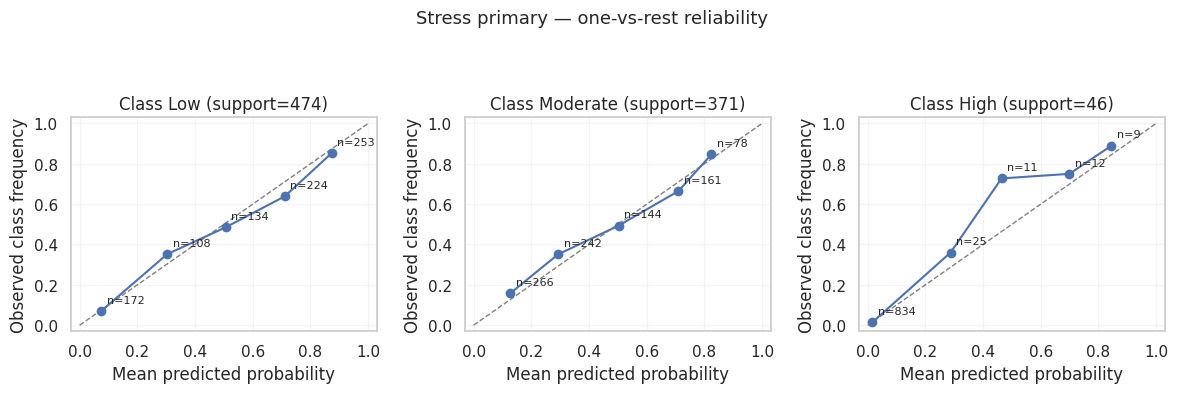

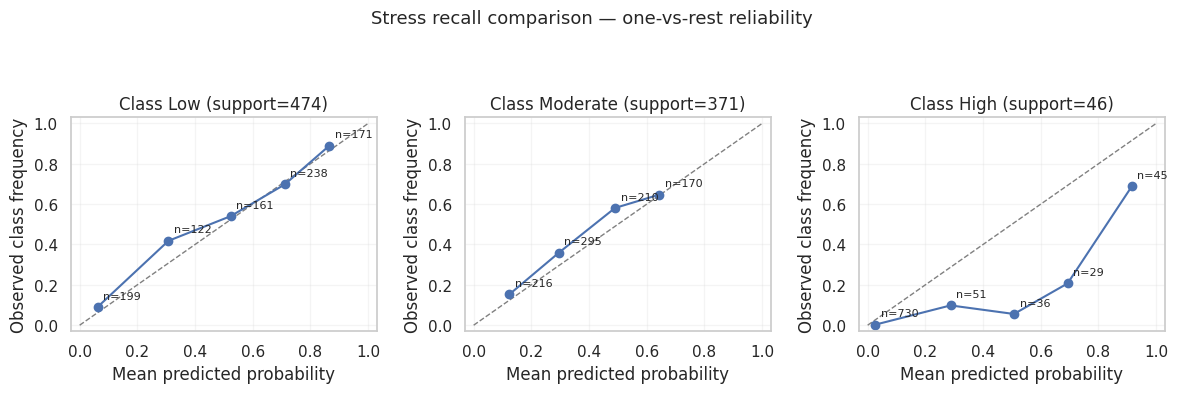

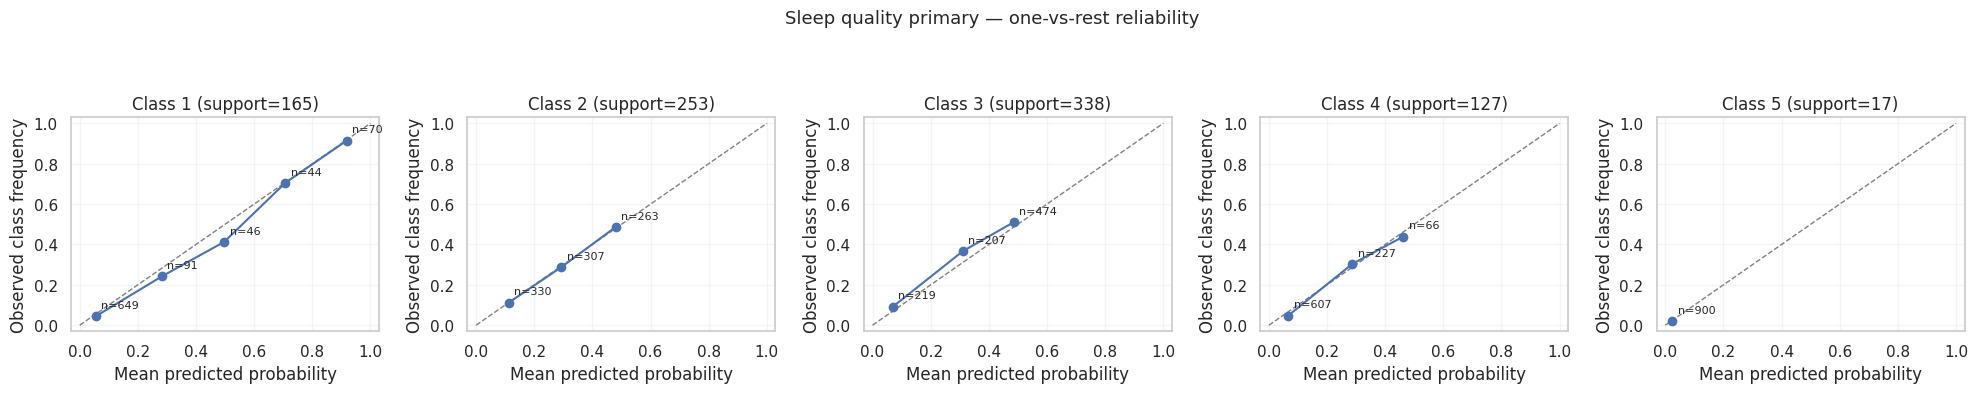

CLASS-WISE PROBABILITY SUMMARY


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Model,Class,Support,Observed_prevalence,Mean_predicted_probability,Mean_probability_minus_prevalence,Class_Brier
0,Stress primary,Low,474,0.5320,0.5541,0.0221,0.1708
1,Stress primary,Moderate,371,0.4164,0.3988,-0.0176,0.1925
2,Stress primary,High,46,0.0516,0.0471,-0.0046,0.0255
3,Stress recall comparison,Low,474,0.5320,0.5064,-0.0256,0.1710
4,Stress recall comparison,Moderate,371,0.4164,0.3661,-0.0503,0.2098
5,Stress recall comparison,High,46,0.0516,0.1275,0.0759,0.0470
6,Sleep quality primary,1,165,0.1833,0.2001,0.0168,0.0765
7,Sleep quality primary,2,253,0.2811,0.2812,0.0001,0.1774
8,Sleep quality primary,3,338,0.3756,0.3445,-0.0311,0.2033
9,Sleep quality primary,4,127,0.1411,0.1513,0.0102,0.1000


Diagnostics only: no models or probabilities were modified. Sparse-bin points are uncertain; agreement of mean probability with prevalence does not establish calibration across all bins. Class-wise Brier scores combine calibration and discrimination.


In [30]:
# ============ SECTION 4.3C: HELD-OUT CALIBRATION DIAGNOSTICS ============
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Validate stored predictions before producing diagnostics.
classification_records = {
    name: record
    for name, record in heldout_predictions.items()
    if "proba" in record
}

assert len(classification_records) == 3

for name, record in classification_records.items():
    assert record["proba"].shape == (
        len(record["y"]), len(record["labels"])
    ), name
    assert np.allclose(record["proba"].sum(axis=1), 1.0), name

N_CALIBRATION_BINS = 5
bin_edges = np.linspace(0.0, 1.0, N_CALIBRATION_BINS + 1)

calibration_bin_rows = []
calibration_class_rows = []

for name, record in classification_records.items():
    labels = record["labels"]
    display_names = class_names[record["task"]]

    fig, axes = plt.subplots(
        1, len(labels),
        figsize=(4 * len(labels), 4),
        squeeze=False
    )

    for column, (label, display_name) in enumerate(
        zip(labels, display_names)
    ):
        ax = axes[0, column]

        observed = (record["y"] == label).astype(int)
        probability = record["proba"][:, column]

        # Fixed bins: [0, .2), [.2, .4), ... [.8, 1].
        bin_id = np.minimum(
            np.searchsorted(bin_edges, probability, side="right") - 1,
            N_CALIBRATION_BINS - 1
        )
        bin_id = np.maximum(bin_id, 0)

        class_bins = []

        for b in range(N_CALIBRATION_BINS):
            mask = bin_id == b
            count = int(mask.sum())

            row = {
                "Model": name,
                "Class": display_name,
                "Bin_lower": bin_edges[b],
                "Bin_upper": bin_edges[b + 1],
                "Count": count,
                "Mean_probability": (
                    float(probability[mask].mean()) if count else np.nan
                ),
                "Observed_frequency": (
                    float(observed[mask].mean()) if count else np.nan
                ),
            }
            calibration_bin_rows.append(row)

            if count:
                class_bins.append(row)

        occupied = pd.DataFrame(class_bins)

        ax.plot(
            [0, 1], [0, 1],
            linestyle="--", color="grey", linewidth=1
        )
        ax.plot(
            occupied["Mean_probability"],
            occupied["Observed_frequency"],
            marker="o", linewidth=1.5
        )

        for _, row in occupied.iterrows():
            ax.annotate(
                f"n={int(row['Count'])}",
                (row["Mean_probability"], row["Observed_frequency"]),
                xytext=(4, 6),
                textcoords="offset points",
                fontsize=8
            )

        ax.set(
            title=f"Class {display_name} (support={observed.sum()})",
            xlabel="Mean predicted probability",
            ylabel="Observed class frequency",
            xlim=(-0.03, 1.03),
            ylim=(-0.03, 1.03)
        )
        ax.grid(alpha=0.2)

        calibration_class_rows.append({
            "Model": name,
            "Class": display_name,
            "Support": int(observed.sum()),
            "Observed_prevalence": float(observed.mean()),
            "Mean_predicted_probability": float(probability.mean()),
            "Mean_probability_minus_prevalence": float(
                probability.mean() - observed.mean()
            ),
            # One-vs-rest Brier score; not a pure calibration measure.
            "Class_Brier": float(
                np.mean((probability - observed) ** 2)
            ),
        })

    fig.suptitle(f"{name} — one-vs-rest reliability", fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.90])
    plt.show()

calibration_bins = pd.DataFrame(calibration_bin_rows)
calibration_summary = pd.DataFrame(calibration_class_rows)

print("CLASS-WISE PROBABILITY SUMMARY")
display(calibration_summary.round(4))

print(
    "Diagnostics only: no models or probabilities were modified. "
    "Sparse-bin points are uncertain; agreement of mean probability "
    "with prevalence does not establish calibration across all bins. "
    "Class-wise Brier scores combine calibration and discrimination."
)

### 4.3D Sleep-duration residual diagnostics
Residual-versus-fitted and residual distribution plots for the Elastic Net. Patterns such as curvature or heteroscedasticity would show where a linear specification under- or over-predicts, for example at extreme usage levels. Such patterns would argue for a non-linear term in future work.

These residual summaries use the held-out predictions made after the models were frozen. They are descriptive only, and no model was changed because of them.

DURATION ERROR SUMMARY


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Model,N,Mean_residual_hours,Median_residual_hours,MAE_hours,P90_absolute_error_hours,Within_0.5_hour_fraction,Within_1_hour_fraction
0,Sleep duration primary,900,-0.0379,-0.0483,0.6417,1.3254,0.4522,0.7889
1,Sleep duration secondary,900,-0.0379,-0.0526,0.6403,1.3301,0.4522,0.7889


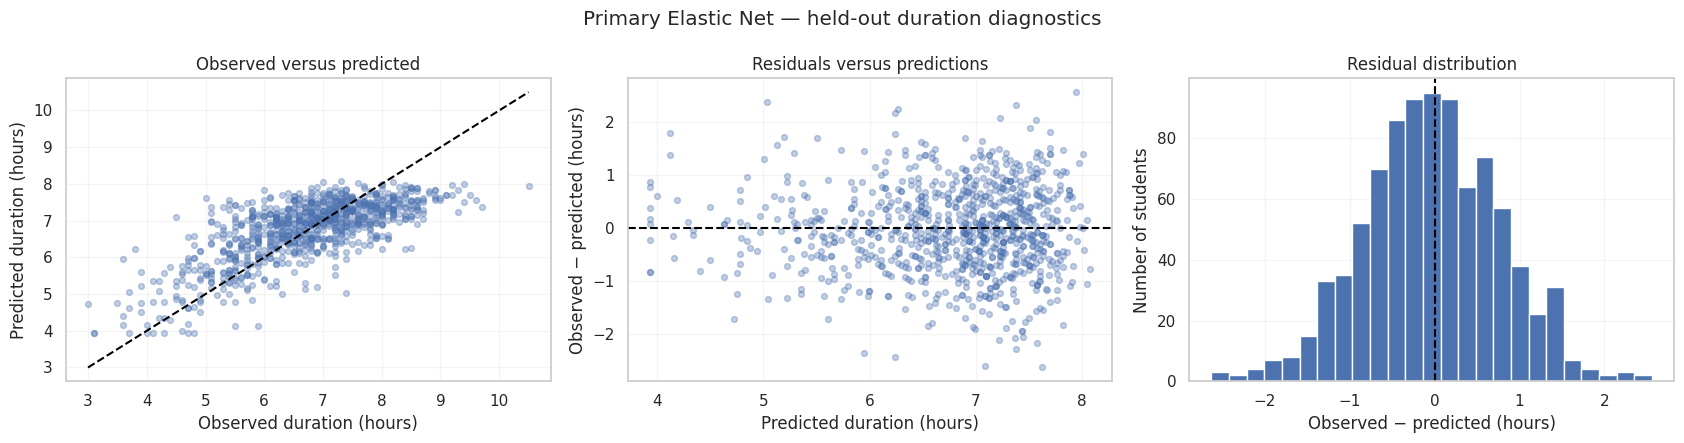

PRIMARY MODEL — ERRORS BY PREDICTED-DURATION QUINTILE


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,N,Mean_prediction_hours,Mean_observed_hours,Mean_residual_hours,MAE_hours,Residual_SD_hours
Prediction_bin,,,,,,
"(3.928, 6.172]",186,5.4335,5.3661,-0.0674,0.5958,0.7609
"(6.172, 6.741]",176,6.4950,6.5040,0.0090,0.6113,0.7828
"(6.741, 7.12]",185,6.9658,6.8773,-0.0885,0.6335,0.7903
"(7.12, 7.436]",175,7.2813,7.2651,-0.0162,0.6640,0.8396
"(7.436, 8.077]",178,7.6515,7.6292,-0.0223,0.7063,0.8754


Diagnostics complete. No models were modified. Near-zero overall bias can conceal errors within prediction ranges; these summaries are descriptive, not formal assumption tests.


In [31]:
# ============ SECTION 4.3D: SLEEP-DURATION RESIDUAL DIAGNOSTICS ============
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

duration_names = [
    "Sleep duration primary",
    "Sleep duration secondary",
]

# 1. Validate the existing predictions before diagnostics.
for name in duration_names:
    assert name in heldout_predictions, f"Missing predictions: {name}"
    record = heldout_predictions[name]

    assert record["task"] == "Sleep duration"
    assert len(record["y"]) == len(record["pred"]) == len(record["rows"])
    assert np.isfinite(record["y"]).all()
    assert np.isfinite(record["pred"]).all()

primary_record = heldout_predictions[duration_names[0]]
secondary_record = heldout_predictions[duration_names[1]]

assert primary_record["rows"].index.equals(
    secondary_record["rows"].index
), "Models must be evaluated on identical rows."

assert np.array_equal(
    primary_record["y"], secondary_record["y"]
), "Observed targets must match."

# 2. Store row-aligned residuals and summarise both frozen models.
duration_residuals = {}
diagnostic_rows = []

for name in duration_names:
    record = heldout_predictions[name]
    observed = np.asarray(record["y"], dtype=float)
    predicted = np.asarray(record["pred"], dtype=float)
    residual = observed - predicted
    absolute_error = np.abs(residual)

    residual_table = pd.DataFrame(
        {
            "Observed_hours": observed,
            "Predicted_hours": predicted,
            "Residual_hours": residual,
            "Absolute_error_hours": absolute_error,
        },
        index=record["rows"].index,
    )
    duration_residuals[name] = residual_table

    diagnostic_rows.append({
        "Model": name,
        "N": len(observed),
        "Mean_residual_hours": residual.mean(),
        "Median_residual_hours": np.median(residual),
        "MAE_hours": absolute_error.mean(),
        "P90_absolute_error_hours": np.quantile(absolute_error, 0.90),
        "Within_0.5_hour_fraction": np.mean(absolute_error <= 0.5),
        "Within_1_hour_fraction": np.mean(absolute_error <= 1.0),
    })

duration_diagnostic_summary = pd.DataFrame(diagnostic_rows)

print("DURATION ERROR SUMMARY")
display(duration_diagnostic_summary.round(4))

# These two tolerances are descriptive error summaries,
# not validated clinical thresholds or prediction-interval coverage.

# 3. Plot diagnostics for the preselected primary model.
primary = duration_residuals["Sleep duration primary"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

lower = min(
    primary["Observed_hours"].min(),
    primary["Predicted_hours"].min(),
)
upper = max(
    primary["Observed_hours"].max(),
    primary["Predicted_hours"].max(),
)

axes[0].scatter(
    primary["Observed_hours"],
    primary["Predicted_hours"],
    alpha=0.35,
    s=18,
)
axes[0].plot(
    [lower, upper], [lower, upper],
    linestyle="--", color="black",
)
axes[0].set(
    title="Observed versus predicted",
    xlabel="Observed duration (hours)",
    ylabel="Predicted duration (hours)",
)

axes[1].scatter(
    primary["Predicted_hours"],
    primary["Residual_hours"],
    alpha=0.35,
    s=18,
)
axes[1].axhline(0, linestyle="--", color="black")
axes[1].set(
    title="Residuals versus predictions",
    xlabel="Predicted duration (hours)",
    ylabel="Observed − predicted (hours)",
)

axes[2].hist(
    primary["Residual_hours"],
    bins=25,
    edgecolor="white",
)
axes[2].axvline(0, linestyle="--", color="black")
axes[2].set(
    title="Residual distribution",
    xlabel="Observed − predicted (hours)",
    ylabel="Number of students",
)

for ax in axes:
    ax.grid(alpha=0.2)

fig.suptitle("Primary Elastic Net — held-out duration diagnostics")
plt.tight_layout()
plt.show()

# 4. Summarise errors across predicted-duration quintiles.
# Group on predictions rather than observed outcomes.
primary_bins = primary.copy()
primary_bins["Prediction_bin"] = pd.qcut(
    primary_bins["Predicted_hours"],
    q=5,
    duplicates="drop",
)

duration_binned_diagnostics = (
    primary_bins.groupby("Prediction_bin", observed=True)
    .agg(
        N=("Residual_hours", "size"),
        Mean_prediction_hours=("Predicted_hours", "mean"),
        Mean_observed_hours=("Observed_hours", "mean"),
        Mean_residual_hours=("Residual_hours", "mean"),
        MAE_hours=("Absolute_error_hours", "mean"),
        Residual_SD_hours=("Residual_hours", "std"),
    )
)

print("PRIMARY MODEL — ERRORS BY PREDICTED-DURATION QUINTILE")
display(duration_binned_diagnostics.round(4))

print(
    "Diagnostics complete. No models were modified. "
    "Near-zero overall bias can conceal errors within prediction ranges; "
    "these summaries are descriptive, not formal assumption tests."
)

### 4.3E.1 Validate subgroup audit fields
Checks that the demographic fields used in the audit are present and correctly aligned with the stored held-out predictions before any group metrics are computed.

**Note on test-set use.** The diagnostics below (calibration, residuals, subgroup audit) use the held-out predictions *after* all models were frozen. They are descriptive and exploratory: no model, feature set or threshold was changed because of them. Subgroup differences are associations and do not identify the cause of any performance gap.

In [32]:
# ============ SECTION 4.3E.1: VALIDATE SUBGROUP AUDIT FIELDS ============
import pandas as pd
from IPython.display import display

assert "heldout_predictions" in globals()
assert "final_specs" in globals()

primary_audit_names = [
    "Stress primary",
    "Sleep quality primary",
    "Sleep duration primary",
]

for name in primary_audit_names:
    assert name in heldout_predictions, f"Missing predictions: {name}"
    record = heldout_predictions[name]
    assert len(record["rows"]) == len(record["y"]) == len(record["pred"])

# Use the stored primary stress rows to inspect available fields.
# These are the labelled test records already used for stress evaluation.
audit_rows = heldout_predictions["Stress primary"]["rows"]

print("AVAILABLE COLUMN NAMES")
display(pd.DataFrame({
    "Column": audit_rows.columns,
    "Dtype": [str(audit_rows[c].dtype) for c in audit_rows.columns],
    "Unique_nonmissing": [
        audit_rows[c].nunique(dropna=True) for c in audit_rows.columns
    ],
    "Missing": [
        int(audit_rows[c].isna().sum()) for c in audit_rows.columns
    ],
}))

# Inspect low-cardinality categorical fields without assuming their names.
categorical_fields = [
    c for c in audit_rows.columns
    if (
        pd.api.types.is_object_dtype(audit_rows[c])
        or isinstance(audit_rows[c].dtype, pd.CategoricalDtype)
        or pd.api.types.is_string_dtype(audit_rows[c])
    )
    and audit_rows[c].nunique(dropna=True) <= 15
]

print("\nLOW-CARDINALITY CATEGORICAL FIELDS — STRESS TEST RECORDS")
for column in categorical_fields:
    print(f"\n{column}")
    display(
        audit_rows[column]
        .value_counts(dropna=False)
        .rename_axis("Group")
        .to_frame("N")
    )

print(
    "\nSchema inspection only. No subgroup metrics were calculated "
    "and no models or predictions were modified."
)

AVAILABLE COLUMN NAMES


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Column,Dtype,Unique_nonmissing,Missing
0,Age,int64,12,0
1,Gender,object,4,0
2,Academic_Level,object,3,0
3,Primary_Platform,object,7,0
4,Daily_Usage_Hours,float64,113,0
5,Weekend_Extra_Hours,float64,40,0
6,Device_Type,object,3,0
7,Sleep_Duration_Hours,float64,66,0
8,Sleep_Quality_Score,int64,5,0
9,Late_Night_Usage,int64,2,0



LOW-CARDINALITY CATEGORICAL FIELDS — STRESS TEST RECORDS

Gender


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,N
Group,
Female,455
Male,401
Non-Binary,22
Prefer not to say,13


... (15 outputs left out)


Stress_Code


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,N
Group,
0,474
1,371
2,46



Schema inspection only. No subgroup metrics were calculated and no models or predictions were modified.


### 4.3E.2 Exploratory subgroup performance audit
Compares held-out performance across gender and academic level for the frozen primary models and the pre-specified stress recall comparison model.

**Reporting rules.**
- Groups with **n < 30** (Prefer not to say, n = 13; Non-Binary, n = 22) have all metrics suppressed.
- **High-stress recall** is reported only where a group has at least **5 actual High-stress cases**. Postgraduate (2 cases) is therefore not reported for this metric.
- No confidence intervals or significance tests are computed here.

**Key observations.**
- **Stress (primary model).** Macro-F1 is higher for Male (0.685) than Female (0.593), and High-stress recall is lower for Female (0.286, n = 21) than Male (0.522, n = 23). The recall-oriented model raises High-stress recall for both groups (Female 0.762, Male 0.870). Each High-stress estimate rests on only about 20 cases, so these gaps could easily be sampling noise.
- **Academic level.** Stress Macro-F1 for the primary model is similar across Undergraduate (0.643), High School (0.676) and Postgraduate (0.611, n = 56). The recall-oriented model varies more (0.650, 0.565 and 0.471).
- **Sleep quality and duration.** Across the reported groups, QWK ranges from 0.635 to 0.750, ordinal MAE from 0.429 to 0.522, and duration MAE from 0.527 to 0.655 h. Mean duration residuals are within about ±0.1 h.

**Interpretation.** This is an *exploratory* fairness check, not a formal fairness certification. Differences between groups can reflect sampling noise or different base rates, and need confirmation on independent data before any conclusion is drawn. Groups with very small samples cannot be assessed at all. This supports the ethics discussion in the report.

In [33]:
# ============ SECTION 4.3E.2: EXPLORATORY SUBGROUP AUDIT ============
import numpy as np
import pandas as pd

from sklearn.metrics import (
    balanced_accuracy_score,
    cohen_kappa_score,
    f1_score,
    mean_absolute_error,
    recall_score,
)

MIN_GROUP_N = 30
MIN_HIGH_STRESS_CASES = 5

# Frozen primary models plus the pre-specified stress recall comparison.
audit_models = [
    "Stress primary",
    "Stress recall comparison",
    "Sleep quality primary",
    "Sleep duration primary",
]

demographic_fields = ["Gender", "Academic_Level"]

# Confirm exact fields and row alignment before computing subgroup metrics.
for model_name in audit_models:
    assert model_name in heldout_predictions, f"Missing: {model_name}"
    record = heldout_predictions[model_name]
    assert len(record["rows"]) == len(record["y"]) == len(record["pred"])

    missing_fields = [
        field for field in demographic_fields
        if field not in record["rows"].columns
    ]
    assert not missing_fields, (
        f"{model_name}: demographic fields missing: {missing_fields}"
    )

group_count_rows = []
subgroup_metric_rows = []

for model_name in audit_models:
    record = heldout_predictions[model_name]
    task = record["task"]
    rows = record["rows"]
    y = np.asarray(record["y"])
    pred = np.asarray(record["pred"])

    if task == "Stress tier":
        labels = np.array([0, 1, 2])
        y = y.astype(int)
        pred = pred.astype(int)
        class_names = ["Low", "Moderate", "High"]

    elif task == "Sleep quality":
        labels = np.array([1, 2, 3, 4, 5])
        y = y.astype(int)
        pred = pred.astype(int)
        class_names = ["1", "2", "3", "4", "5"]

    else:
        labels = None
        y = y.astype(float)
        pred = pred.astype(float)

    for field in demographic_fields:
        group_values = rows[field].astype("string").fillna("Missing").to_numpy()

        for group in pd.unique(group_values):
            mask = group_values == group
            n = int(mask.sum())

            count_row = {
                "Model": model_name,
                "Task": task,
                "Grouping": field,
                "Group": str(group),
                "N": n,
                "Metrics_status": (
                    "Reported descriptively"
                    if n >= MIN_GROUP_N
                    else f"Suppressed: group N < {MIN_GROUP_N}"
                ),
            }

            if task == "Stress tier":
                for label, class_name in zip(labels, class_names):
                    count_row[f"Actual_{class_name}_n"] = int(
                        np.sum(y[mask] == label)
                    )
            elif task == "Sleep quality":
                for label, class_name in zip(labels, class_names):
                    count_row[f"Actual_score_{class_name}_n"] = int(
                        np.sum(y[mask] == label)
                    )

            group_count_rows.append(count_row)

            metric_row = {
                "Model": model_name,
                "Task": task,
                "Grouping": field,
                "Group": str(group),
                "N": n,
            }

            if n < MIN_GROUP_N:
                metric_row["Metrics_status"] = (
                    f"Suppressed: group N < {MIN_GROUP_N}"
                )
                subgroup_metric_rows.append(metric_row)
                continue

            metric_row["Metrics_status"] = "Descriptive only"

            if task == "Stress tier":
                yg, pg = y[mask], pred[mask]
                high_support = int(np.sum(yg == 2))

                metric_row["Macro_F1"] = f1_score(
                    yg, pg, labels=labels,
                    average="macro", zero_division=0
                )
                metric_row["Balanced_accuracy"] = balanced_accuracy_score(
                    yg, pg
                )
                metric_row["High_stress_recall"] = (
                    recall_score(yg, pg, labels=[2],
                                 average="macro", zero_division=0)
                    if high_support >= MIN_HIGH_STRESS_CASES
                    else np.nan
                )
                metric_row["High_stress_support"] = high_support
                if high_support < MIN_HIGH_STRESS_CASES:
                    metric_row["High_recall_note"] = (
                        f"Not reported: fewer than "
                        f"{MIN_HIGH_STRESS_CASES} actual High cases"
                    )

            elif task == "Sleep quality":
                yg, pg = y[mask], pred[mask]
                metric_row["QWK"] = cohen_kappa_score(
                    yg, pg, labels=labels, weights="quadratic"
                )
                metric_row["Macro_F1"] = f1_score(
                    yg, pg, labels=labels,
                    average="macro", zero_division=0
                )
                metric_row["Ordinal_MAE"] = mean_absolute_error(yg, pg)

            else:
                yg, pg = y[mask], pred[mask]
                residual = yg - pg
                metric_row["MAE_hours"] = mean_absolute_error(yg, pg)
                metric_row["Mean_residual_hours"] = float(residual.mean())

            subgroup_metric_rows.append(metric_row)

subgroup_counts = pd.DataFrame(group_count_rows)
subgroup_metrics = pd.DataFrame(subgroup_metric_rows)

print("GROUP SIZES AND ACTUAL TARGET SUPPORT")
display(subgroup_counts)

print("SUBGROUP PERFORMANCE — DESCRIPTIVE, NOT A SIGNIFICANCE TEST")
display(subgroup_metrics.round(3))

print(
    "No models were refitted or selected using subgroup results. "
    "Small-group metrics are suppressed; all displayed subgroup "
    "comparisons are exploratory and should be interpreted cautiously."
)

GROUP SIZES AND ACTUAL TARGET SUPPORT


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Model,Task,Grouping,Group,N,Metrics_status,Actual_Low_n,Actual_Moderate_n,Actual_High_n,Actual_score_1_n,Actual_score_2_n,Actual_score_3_n,Actual_score_4_n,Actual_score_5_n
0,Stress primary,Stress tier,Gender,Female,455,Reported descriptively,246.0,188.0,21.0,NaN,NaN,NaN,NaN,NaN
1,Stress primary,Stress tier,Gender,Male,401,Reported descriptively,209.0,169.0,23.0,NaN,NaN,NaN,NaN,NaN
2,Stress primary,Stress tier,Gender,Prefer not to say,13,Suppressed: group N < 30,9.0,4.0,0.0,NaN,NaN,NaN,NaN,NaN
3,Stress primary,Stress tier,Gender,Non-Binary,22,Suppressed: group N < 30,10.0,10.0,2.0,NaN,NaN,NaN,NaN,NaN
4,Stress primary,Stress tier,Academic_Level,Undergraduate,577,Reported descriptively,313.0,228.0,36.0,NaN,NaN,NaN,NaN,NaN
5,Stress primary,Stress tier,Academic_Level,High School,258,Reported descriptively,137.0,113.0,8.0,NaN,NaN,NaN,NaN,NaN
6,Stress primary,Stress tier,Academic_Level,Postgraduate,56,Reported descriptively,24.0,30.0,2.0,NaN,NaN,NaN,NaN,NaN
7,Stress recall comparison,Stress tier,Gender,Female,455,Reported descriptively,246.0,188.0,21.0,NaN,NaN,NaN,NaN,NaN
8,Stress recall comparison,Stress tier,Gender,Male,401,Reported descriptively,209.0,169.0,23.0,NaN,NaN,NaN,NaN,NaN
9,Stress recall comparison,Stress tier,Gender,Prefer not to say,13,Suppressed: group N < 30,9.0,4.0,0.0,NaN,NaN,NaN,NaN,NaN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


SUBGROUP PERFORMANCE — DESCRIPTIVE, NOT A SIGNIFICANCE TEST


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Model,Task,Grouping,Group,N,Metrics_status,Macro_F1,Balanced_accuracy,High_stress_recall,High_stress_support,High_recall_note,QWK,Ordinal_MAE,MAE_hours,Mean_residual_hours
0,Stress primary,Stress tier,Gender,Female,455,Descriptive only,0.593,0.565,0.286,21.0,NaN,NaN,NaN,NaN,NaN
1,Stress primary,Stress tier,Gender,Male,401,Descriptive only,0.685,0.643,0.522,23.0,NaN,NaN,NaN,NaN,NaN
2,Stress primary,Stress tier,Gender,Prefer not to say,13,Suppressed: group N < 30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Stress primary,Stress tier,Gender,Non-Binary,22,Suppressed: group N < 30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Stress primary,Stress tier,Academic_Level,Undergraduate,577,Descriptive only,0.643,0.607,0.389,36.0,NaN,NaN,NaN,NaN,NaN
5,Stress primary,Stress tier,Academic_Level,High School,258,Descriptive only,0.676,0.625,0.500,8.0,NaN,NaN,NaN,NaN,NaN
6,Stress primary,Stress tier,Academic_Level,Postgraduate,56,Descriptive only,0.611,0.619,NaN,2.0,Not reported: fewer than 5 actual High cases,NaN,NaN,NaN,NaN
7,Stress recall comparison,Stress tier,Gender,Female,455,Descriptive only,0.598,0.683,0.762,21.0,NaN,NaN,NaN,NaN,NaN
8,Stress recall comparison,Stress tier,Gender,Male,401,Descriptive only,0.634,0.718,0.870,23.0,NaN,NaN,NaN,NaN,NaN
9,Stress recall comparison,Stress tier,Gender,Prefer not to say,13,Suppressed: group N < 30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


No models were refitted or selected using subgroup results. Small-group metrics are suppressed; all displayed subgroup comparisons are exploratory and should be interpreted cautiously.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# 5 · INTERPRET
This section asks which predictors the three frozen primary models **rely on** and how their predictions change with those predictors. It uses three complementary tools: permutation importance (5.1), partial dependence (5.2) and SHAP (5.3). No model is refitted or modified here. All three tools explain the fitted models, not the underlying population, and none of them establishes cause and effect.

### 5.1 Permutation importance (held-out data)
Measures how much each primary model's held-out score worsens when one predictor is randomly shuffled (Breiman, 2001). It is model-agnostic and computed on held-out data, so it reflects reliance at the point of generalisation. Each predictor is shuffled 20 times.

**Key observation.** Shuffling `Daily_Usage_Hours` lowers stress Macro-F1 by 0.314 and sleep-quality QWK by 0.647, and raises duration MAE by 0.471 h. Every other predictor contributes close to zero, and the shuffle SD is as large as or larger than the importance for most of them. The models therefore **rely** heavily on usage. This is a statement about the models, not about cause and effect in the population.

**Reading the zeros.** The Elastic Net duration model gives exactly zero importance to most predictors because its L1 penalty set their coefficients to zero. That is a property of the fitted model. It is not a test that those predictors are unrelated to sleep duration. Near-zero predictors should not be ranked against each other.

Validation passed: all three models reproduce stored predictions.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Stress primary — Ordinal logit — Base
Decrease in Macro-F1 after shuffling


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Feature,Mean_importance,Shuffle_SD
0,Daily_Usage_Hours,0.31428,0.01114
1,Gender,0.00499,0.00561
2,Age,0.00104,0.00099
3,Late_Night_Usage,0.00081,0.00477
4,Academic_Level,0.00068,0.00073
5,Comparison_Ord,-0.00043,0.00178
6,Weekend_Extra_Hours,-0.00080,0.00063
7,Device_Type,-0.00237,0.00283
8,Primary_Platform,-0.00287,0.00268


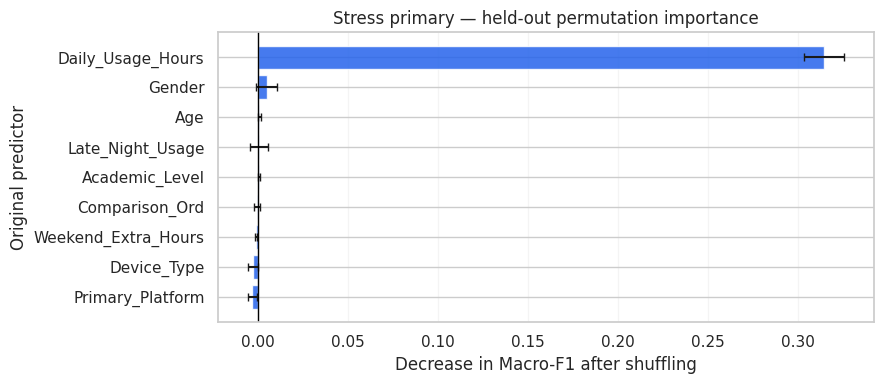


Sleep quality primary — Ordinal logit — Base
Decrease in QWK after shuffling


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Feature,Mean_importance,Shuffle_SD
0,Daily_Usage_Hours,0.64742,0.03569
1,Weekend_Extra_Hours,0.00175,0.00113
2,Late_Night_Usage,0.00174,0.00213
3,Primary_Platform,0.00167,0.00277
4,Device_Type,0.00140,0.00148
5,Academic_Level,0.00074,0.00218
6,Comparison_Ord,0.00042,0.00125
7,Gender,-0.00048,0.00218
8,Age,-0.00107,0.00131


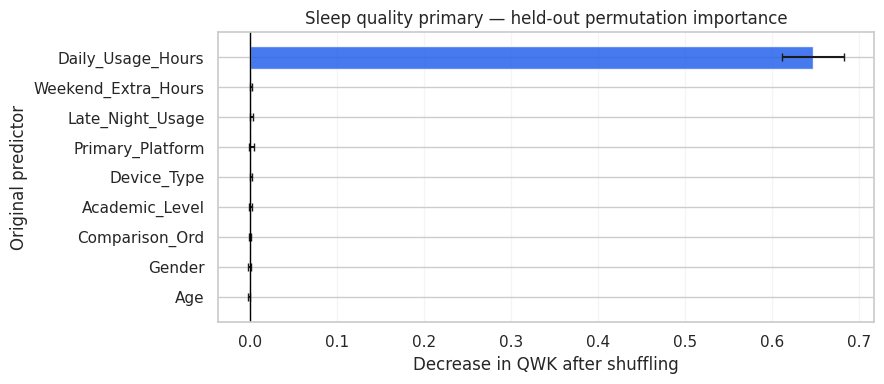


Sleep duration primary — Elastic Net — Base
Increase in MAE after shuffling (hours)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Feature,Mean_importance,Shuffle_SD
0,Daily_Usage_Hours,0.46999,0.02016
1,Gender,0.00000,0.00000
2,Academic_Level,0.00000,0.00000
3,Device_Type,0.00000,0.00000
4,Primary_Platform,0.00000,0.00000
5,Age,0.00000,0.00000
6,Weekend_Extra_Hours,0.00000,0.00000
7,Comparison_Ord,0.00000,0.00000
8,Late_Night_Usage,-0.00027,0.00097


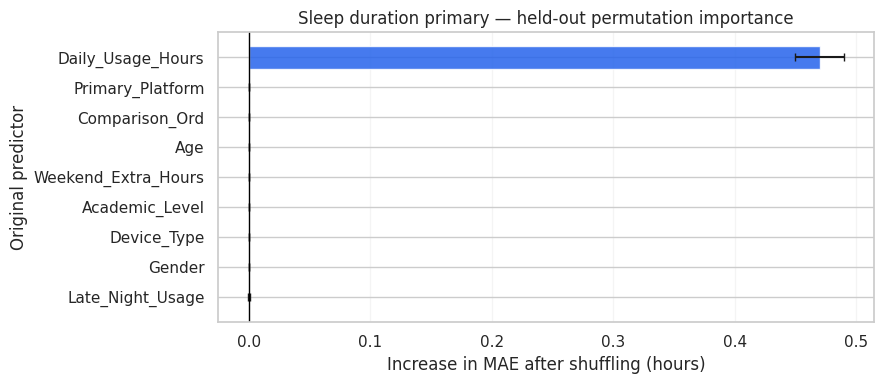


UNSHUFFLED HELD-OUT BASELINES


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Model,Task,Test_N,Baseline_metric,Baseline_value
0,Stress primary,Stress tier,891,Macro-F1,0.64516
1,Sleep quality primary,Sleep quality,900,QWK,0.65682
2,Sleep duration primary,Sleep duration,900,MAE_hours,0.64168



Interpretation notes:
- Positive importance: shuffling worsened performance.
- Near-zero importance: little measured reliance under this procedure.
- Negative importance: shuffling improved performance on this sample; this is not evidence of a protective effect.
- Error bars show SD across random shuffles, not confidence intervals.
- Correlated predictors can substitute for one another, masking reliance.
- Shuffling can create implausible predictor combinations.
- Importance magnitudes are not directly comparable across tasks.
- No models were refitted or modified.


In [34]:
# ============ SECTION 5.1: GLOBAL PERMUTATION IMPORTANCE ============
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    f1_score,
    cohen_kappa_score,
    mean_absolute_error,
)

PERMUTATION_REPEATS = 20

interpretation_models = [
    "Stress primary",
    "Sleep quality primary",
    "Sleep duration primary",
]

# 1. Validate frozen models, input fields, and prediction consistency.
for name in interpretation_models:
    assert name in final_specs, f"Missing model specification: {name}"
    assert name in heldout_predictions, f"Missing held-out predictions: {name}"

    spec = final_specs[name]
    record = heldout_predictions[name]

    assert spec["task"] == record["task"]
    assert record["rows"].index.is_unique
    assert len(record["rows"]) == len(record["y"])

    X_check = record["rows"].loc[:, spec["features"]]
    current_prediction = np.asarray(spec["model"].predict(X_check))

    np.testing.assert_allclose(
        current_prediction,
        np.asarray(record["pred"]),
        rtol=1e-8,
        atol=1e-8,
        err_msg=f"{name}: predictions changed since held-out evaluation.",
    )

print("Validation passed: all three models reproduce stored predictions.")

# 2. Explicit scoring functions support the existing custom ordinal model.
# All scores follow the convention: higher is better.
def stress_interpretation_score(estimator, X, y):
    prediction = estimator.predict(X)
    return f1_score(
        y,
        prediction,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0,
    )


def quality_interpretation_score(estimator, X, y):
    prediction = estimator.predict(X)
    return cohen_kappa_score(
        y,
        prediction,
        labels=[1, 2, 3, 4, 5],
        weights="quadratic",
    )


def duration_interpretation_score(estimator, X, y):
    prediction = estimator.predict(X)
    return -mean_absolute_error(y, prediction)


interpretation_scorers = {
    "Stress tier": stress_interpretation_score,
    "Sleep quality": quality_interpretation_score,
    "Sleep duration": duration_interpretation_score,
}

importance_axis_labels = {
    "Stress tier": "Decrease in Macro-F1 after shuffling",
    "Sleep quality": "Decrease in QWK after shuffling",
    "Sleep duration": "Increase in MAE after shuffling (hours)",
}

# 3. Compute original-column importance.
# Preprocessing stays inside the fitted pipeline.
# No fitting or tuning occurs.
permutation_results = {}
permutation_tables = {}
permutation_baseline_rows = []

for name in interpretation_models:
    spec = final_specs[name]
    record = heldout_predictions[name]
    task = spec["task"]

    X = record["rows"].loc[:, spec["features"]].copy()
    y = np.asarray(record["y"])
    scorer = interpretation_scorers[task]

    baseline_score = scorer(spec["model"], X, y)

    permutation_baseline_rows.append({
        "Model": name,
        "Task": task,
        "Test_N": len(y),
        "Baseline_metric": {
            "Stress tier": "Macro-F1",
            "Sleep quality": "QWK",
            "Sleep duration": "MAE_hours",
        }[task],
        "Baseline_value": (
            -baseline_score if task == "Sleep duration"
            else baseline_score
        ),
    })

    result = permutation_importance(
        estimator=spec["model"],
        X=X,
        y=y,
        scoring=scorer,
        n_repeats=PERMUTATION_REPEATS,
        random_state=SEED,
        n_jobs=1,
    )

    table = pd.DataFrame({
        "Feature": spec["features"],
        "Mean_importance": result.importances_mean,
        "Shuffle_SD": result.importances_std,
    }).sort_values(
        "Mean_importance",
        ascending=False,
        ignore_index=True,
    )

    permutation_results[name] = result
    permutation_tables[name] = table

    print(f"\n{name} — {spec['candidate']}")
    print(importance_axis_labels[task])
    display(table.round(5))

    # Show all predictors, with the largest mean importance at the top.
    plot_table = table.sort_values("Mean_importance", ascending=True)

    fig, ax = plt.subplots(
        figsize=(9, max(4, 0.4 * len(plot_table)))
    )
    ax.barh(
        plot_table["Feature"],
        plot_table["Mean_importance"],
        xerr=plot_table["Shuffle_SD"],
        color="#2563EB",
        alpha=0.85,
        capsize=3,
    )
    ax.axvline(0, color="black", linewidth=1)
    ax.set(
        title=f"{name} — held-out permutation importance",
        xlabel=importance_axis_labels[task],
        ylabel="Original predictor",
    )
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()

permutation_baselines = pd.DataFrame(permutation_baseline_rows)

print("\nUNSHUFFLED HELD-OUT BASELINES")
display(permutation_baselines.round(5))

print(
    "\nInterpretation notes:\n"
    "- Positive importance: shuffling worsened performance.\n"
    "- Near-zero importance: little measured reliance under this procedure.\n"
    "- Negative importance: shuffling improved performance on this sample; "
    "this is not evidence of a protective effect.\n"
    "- Error bars show SD across random shuffles, not confidence intervals.\n"
    "- Correlated predictors can substitute for one another, masking reliance.\n"
    "- Shuffling can create implausible predictor combinations.\n"
    "- Importance magnitudes are not directly comparable across tasks.\n"
    "- No models were refitted or modified."
)

### 5.2 Partial dependence on daily usage
Partial dependence plots (Friedman, 2001) show how the average prediction changes across 40 grid points of `Daily_Usage_Hours`, with the other features averaged out over 1,000 randomly sampled **development** rows. The grid spans the development 2.5th–97.5th percentiles (1.90–12.30 h), so extreme values are excluded.

**Key observation.** Across that range:
- Predicted probability of Low stress falls from about 0.92 to 0.01, and High stress rises from about 0.00 to 0.59.
- Expected sleep-quality score falls from about 3.54 to 1.03.
- Predicted sleep duration falls from about 7.78 h to 4.50 h.

**Caution.** Ordinal logit and Elastic Net are monotonic in each predictor by construction. The *direction* of these curves is therefore largely built into the model form. The informative part is the **size** of the change across the usage range. PDPs also assume predictors are roughly independent and can average over unrealistic combinations, so they are read together with the correlation results in 3.4. The curves describe model predictions, not causal effects.

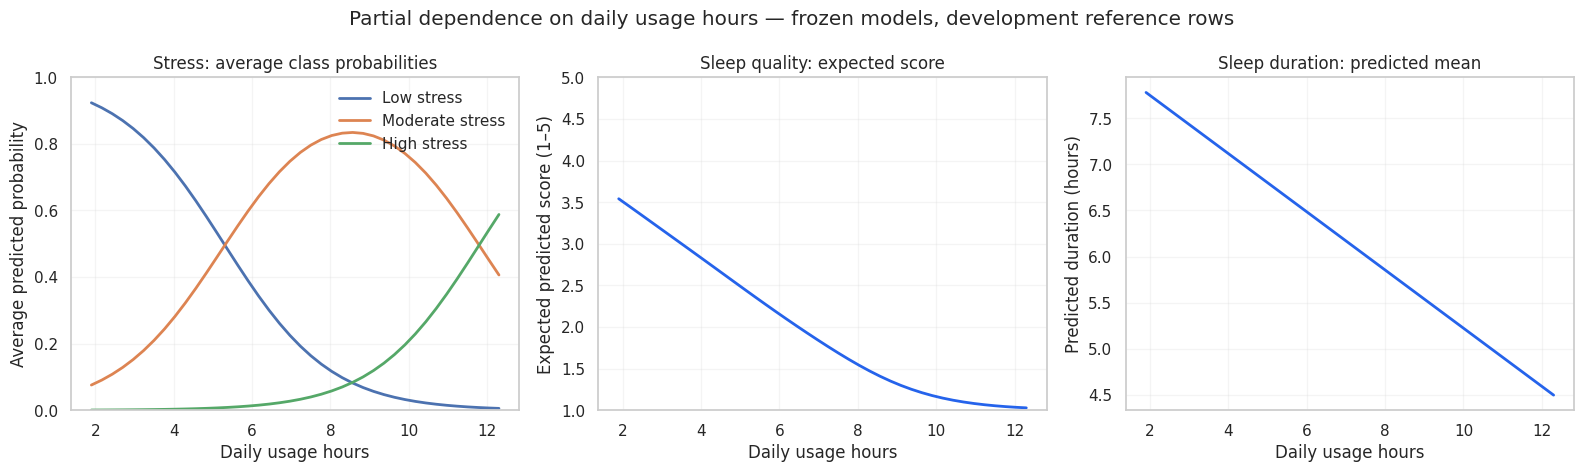

Curves computed over 1000 sampled development rows. The usage grid spans the development-set 2.5th–97.5th percentiles: 1.90 to 12.30 hours.
These curves describe average model predictions under feature replacement. They are not causal effects, and they may be less reliable where usage values are rare or combinations are unrealistic.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [35]:
# ============ SECTION 5.2: PARTIAL DEPENDENCE ON DAILY USAGE ============
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FEATURE = "Daily_Usage_Hours"
GRID_POINTS = 40

pdp_model_names = [
    "Stress primary",
    "Sleep quality primary",
    "Sleep duration primary",
]

# Validate model specifications, predictor availability, and fitted status.
for name in pdp_model_names:
    assert name in final_specs, f"Missing model: {name}"
    spec = final_specs[name]
    assert FEATURE in spec["features"], (
        f"{FEATURE} is not a predictor in {name}."
    )
    assert spec["task"] in TASKS

# Build a common grid from the development sample's central 95% range.
reference_data = TASKS["Stress tier"]["data"]
assert FEATURE in reference_data.columns

usage_values = pd.to_numeric(
    reference_data[FEATURE], errors="coerce"
).dropna()

assert len(usage_values) > 0
grid_low, grid_high = usage_values.quantile([0.025, 0.975])

assert np.isfinite(grid_low) and np.isfinite(grid_high)
assert grid_high > grid_low, "Daily usage has no usable variation."

usage_grid = np.linspace(grid_low, grid_high, GRID_POINTS)

# Use a reproducible subset of development rows for practical runtime.
rng = np.random.default_rng(SEED)
N_REFERENCE = min(1000, len(reference_data))
reference_indices = rng.choice(
    len(reference_data),
    size=N_REFERENCE,
    replace=False,
)
reference_rows = reference_data.iloc[reference_indices].copy()

# Obtain class labels in the same order as each fitted estimator's probabilities.
def fitted_class_labels(model):
    estimator = model.named_steps["m"]
    return np.asarray(estimator.classes_)

pdp_results = {}

for name in pdp_model_names:
    spec = final_specs[name]
    task_name = spec["task"]
    model = spec["model"]
    features = spec["features"]

    X_reference = reference_rows.loc[:, features].copy()
    assert FEATURE in X_reference.columns

    if task_name == "Stress tier":
        classes = np.array([0, 1, 2])
        model_classes = fitted_class_labels(model)
        assert set(model_classes) == set(classes)

        probability_curves = []

        for value in usage_grid:
            X_modified = X_reference.copy()
            X_modified[FEATURE] = value

            probability = np.asarray(
                model.predict_proba(X_modified)
            )
            order = [
                np.flatnonzero(model_classes == label)[0]
                for label in classes
            ]
            probability_curves.append(probability[:, order].mean(axis=0))

        curve = np.vstack(probability_curves)
        pdp_results[name] = {
            "task": task_name,
            "grid": usage_grid,
            "values": curve,
            "labels": ["Low stress", "Moderate stress", "High stress"],
        }

    elif task_name == "Sleep quality":
        classes = np.array([1, 2, 3, 4, 5])
        model_classes = fitted_class_labels(model)
        assert set(model_classes) == set(classes)

        expected_score = []

        for value in usage_grid:
            X_modified = X_reference.copy()
            X_modified[FEATURE] = value

            probability = np.asarray(
                model.predict_proba(X_modified)
            )
            order = [
                np.flatnonzero(model_classes == label)[0]
                for label in classes
            ]
            probability = probability[:, order]

            expected_score.append(
                np.mean(probability @ classes.astype(float))
            )

        pdp_results[name] = {
            "task": task_name,
            "grid": usage_grid,
            "values": np.asarray(expected_score),
        }

    else:
        predicted_duration = []

        for value in usage_grid:
            X_modified = X_reference.copy()
            X_modified[FEATURE] = value

            predicted_duration.append(
                np.asarray(model.predict(X_modified)).mean()
            )

        pdp_results[name] = {
            "task": task_name,
            "grid": usage_grid,
            "values": np.asarray(predicted_duration),
        }

# Plot three task-specific responses.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

stress = pdp_results["Stress primary"]
for column, label in enumerate(stress["labels"]):
    axes[0].plot(
        stress["grid"],
        stress["values"][:, column],
        label=label,
        linewidth=2,
    )
axes[0].set(
    title="Stress: average class probabilities",
    xlabel="Daily usage hours",
    ylabel="Average predicted probability",
    ylim=(0, 1),
)
axes[0].legend(frameon=False)

quality = pdp_results["Sleep quality primary"]
axes[1].plot(
    quality["grid"],
    quality["values"],
    color="#2563EB",
    linewidth=2,
)
axes[1].set(
    title="Sleep quality: expected score",
    xlabel="Daily usage hours",
    ylabel="Expected predicted score (1–5)",
    ylim=(1, 5),
)

duration = pdp_results["Sleep duration primary"]
axes[2].plot(
    duration["grid"],
    duration["values"],
    color="#2563EB",
    linewidth=2,
)
axes[2].set(
    title="Sleep duration: predicted mean",
    xlabel="Daily usage hours",
    ylabel="Predicted duration (hours)",
)

for ax in axes:
    ax.grid(alpha=0.2)

fig.suptitle(
    "Partial dependence on daily usage hours "
    "— frozen models, development reference rows"
)
plt.tight_layout()
plt.show()

print(
    f"Curves computed over {N_REFERENCE} sampled development rows. "
    f"The usage grid spans the development-set 2.5th–97.5th percentiles: "
    f"{grid_low:.2f} to {grid_high:.2f} hours."
)
print(
    "These curves describe average model predictions under feature "
    "replacement. They are not causal effects, and they may be less "
    "reliable where usage values are rare or combinations are unrealistic."
)

### 5.3A SHAP — sleep duration model
SHAP values (Lundberg & Lee, 2017) split each individual prediction into additive contributions from each feature, relative to a background baseline. A 100-row development sample is the background, and 100 randomly sampled held-out rows are explained. For the linear Elastic Net the attributions are exact.

**Key observation.** Mean |SHAP| for `Daily_Usage_Hours` is about 0.67 h. The next feature, `Late_Night_Usage`, is about 0.04 h, and every other transformed feature is exactly zero because of the L1 penalty. This agrees with the permutation results in 5.1. Because this model is linear, the SHAP ranking follows directly from the fitted coefficients, so it adds little beyond the coefficients themselves.

SHAP version: 0.54.1
Development background rows: 100
Held-out rows explained: 100
Additive reconstruction check passed.

GLOBAL SHAP IMPORTANCE — EXPLAINED HELD-OUT SAMPLE


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Transformed_feature,Mean_absolute_SHAP_hours
0,num__Daily_Usage_Hours,0.66619
1,num__Late_Night_Usage,0.03600
2,num__Age,0.00000
3,num__Weekend_Extra_Hours,0.00000
4,num__Comparison_Ord,0.00000
5,cat__Gender_Female,0.00000
6,cat__Gender_Male,0.00000
7,cat__Gender_Non-Binary,0.00000
8,cat__Gender_Prefer not to say,0.00000
9,cat__Academic_Level_High School,0.00000


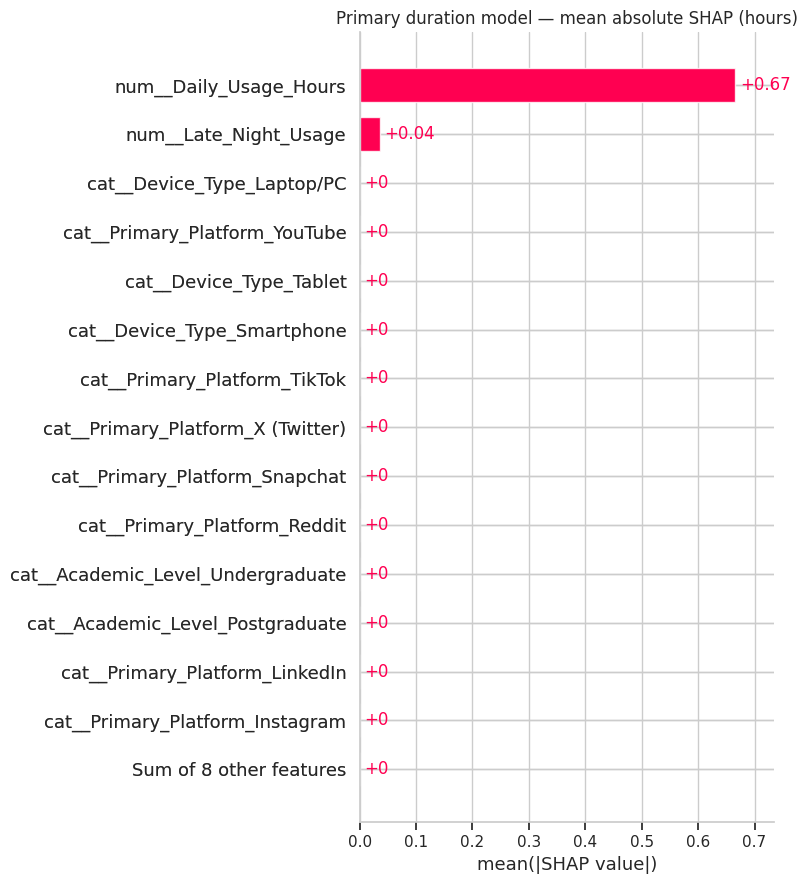

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


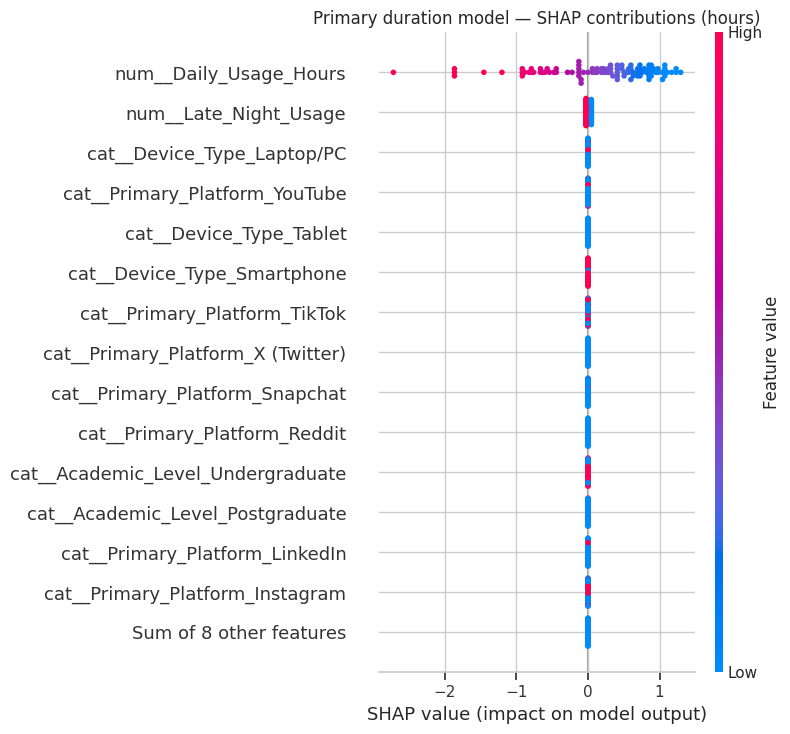


REPRESENTATIVE CASE — ORIGINAL INPUTS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Gender,Academic_Level,Primary_Platform,Device_Type,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Comparison_Ord,Late_Night_Usage
1304,Female,Undergraduate,TikTok,Laptop/PC,20,4.1,3.4,1,1


REPRESENTATIVE CASE — PREDICTION SUMMARY


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Row_index,Observed_hours,Predicted_hours,SHAP_baseline_hours
0,1304,7.1,7.0567,6.6735


/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2010: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.space          = oneOf(self._space_widths)("space")
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2012: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.style_literal  = oneOf(
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2020: PyparsingDeprecationWarning: 'leaveWhitespace' deprecated - use 'leave_whitespace'
  )("sym").leaveWhitespace()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2024: PyparsingDeprecationWarning: 'oneO

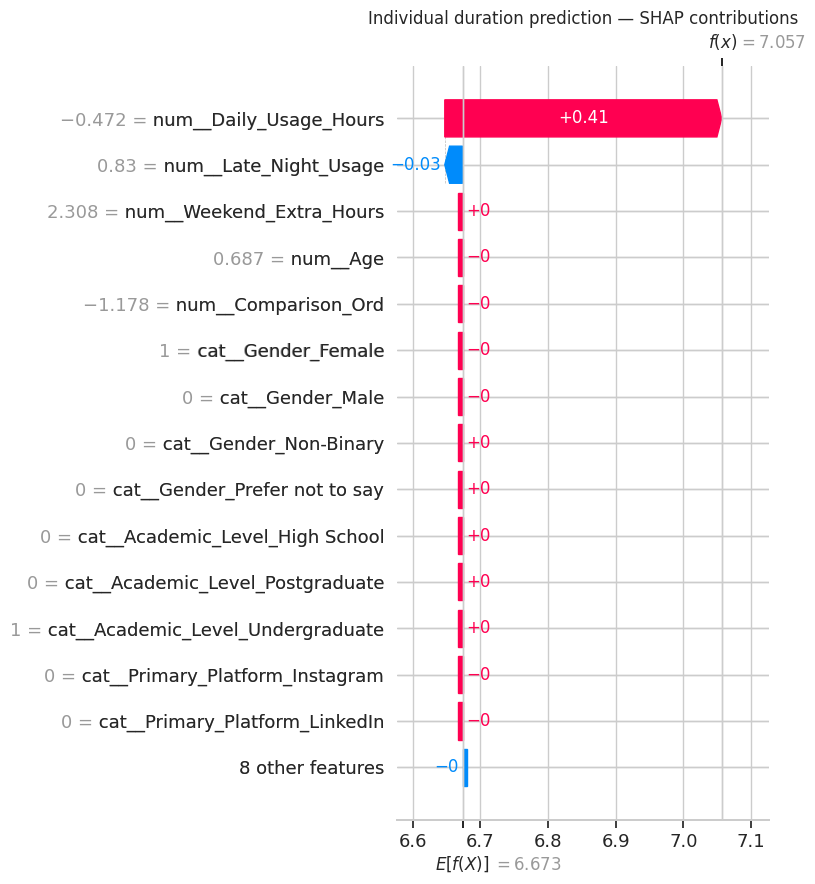


Interpretation:
- Positive SHAP values raise predicted sleep duration relative to the background baseline.
- Negative SHAP values lower predicted sleep duration.
- Contributions are measured in hours, not causal effects.
- Beeswarm colours represent transformed predictor values; numeric inputs may be scaled and categories one-hot encoded.
- Independent masking does not preserve predictor dependencies; attributions depend on this convention and the background sample.
- No models were fitted, tuned, or modified.


In [36]:
# ============ SECTION 5.3A: SHAP — PRIMARY SLEEP-DURATION MODEL ============
# Install SHAP only if it is not already available.
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("shap") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "shap"
    ])

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display

MODEL_NAME = "Sleep duration primary"
BACKGROUND_N = 100
EXPLAIN_N = 100

# 1. Validate the fitted pipeline and development/test inputs.
spec = final_specs[MODEL_NAME]
record = heldout_predictions[MODEL_NAME]

assert spec["task"] == "Sleep duration"
assert "pre" in spec["model"].named_steps
assert "m" in spec["model"].named_steps

pipeline = spec["model"]
preprocessor = pipeline.named_steps["pre"]
estimator = pipeline.named_steps["m"]

assert hasattr(estimator, "coef_")
assert hasattr(estimator, "intercept_")

development_data = TASKS[spec["task"]]["data"]
X_development = development_data.loc[:, spec["features"]]
X_heldout = record["rows"].loc[:, spec["features"]]

# Confirm the frozen pipeline still reproduces its stored predictions.
np.testing.assert_allclose(
    pipeline.predict(X_heldout),
    record["pred"],
    rtol=1e-8,
    atol=1e-8,
)

assert hasattr(preprocessor, "get_feature_names_out"), (
    "The fitted preprocessor does not expose feature names. "
    "Stop here rather than inventing transformed-column labels."
)

transformed_names = np.asarray(
    preprocessor.get_feature_names_out()
).astype(str)

# 2. Select reproducible background and explanation samples.
background_raw = X_development.sample(
    n=min(BACKGROUND_N, len(X_development)),
    random_state=SEED,
)

explanation_raw = X_heldout.sample(
    n=min(EXPLAIN_N, len(X_heldout)),
    random_state=SEED,
)

def dense_transformed(frame):
    transformed = preprocessor.transform(frame)
    if sparse.issparse(transformed):
        transformed = transformed.toarray()
    return np.asarray(transformed, dtype=float)

background_transformed = dense_transformed(background_raw)
explanation_transformed = dense_transformed(explanation_raw)

assert background_transformed.shape[1] == len(transformed_names)
assert explanation_transformed.shape[1] == len(transformed_names)
assert np.isfinite(background_transformed).all()
assert np.isfinite(explanation_transformed).all()

# Verify that preprocessing + estimator matches the full pipeline.
duration_shap_predictions = np.asarray(
    pipeline.predict(explanation_raw)
)

np.testing.assert_allclose(
    estimator.predict(explanation_transformed),
    duration_shap_predictions,
    rtol=1e-8,
    atol=1e-8,
)

# 3. Explain the fitted linear estimator.
# Independent masking uses an interventional attribution convention:
# it does not preserve correlations or one-hot constraints under masking.
duration_shap_masker = shap.maskers.Independent(
    background_transformed,
    max_samples=len(background_transformed),
)

duration_shap_explainer = shap.LinearExplainer(
    estimator,
    duration_shap_masker,
    feature_names=transformed_names.tolist(),
)

duration_shap_values = duration_shap_explainer(
    explanation_transformed
)

# 4. Check additive reconstruction in the model's output units: hours.
reconstructed = (
    np.asarray(duration_shap_values.base_values).reshape(-1)
    + np.asarray(duration_shap_values.values).sum(axis=1)
)

np.testing.assert_allclose(
    reconstructed,
    duration_shap_predictions,
    rtol=1e-6,
    atol=1e-6,
    err_msg="SHAP contributions do not reconstruct model predictions.",
)

print(f"SHAP version: {shap.__version__}")
print(f"Development background rows: {len(background_raw)}")
print(f"Held-out rows explained: {len(explanation_raw)}")
print("Additive reconstruction check passed.")

# 5. Global importance in transformed-feature space.
duration_shap_importance = pd.DataFrame({
    "Transformed_feature": transformed_names,
    "Mean_absolute_SHAP_hours": np.abs(
        duration_shap_values.values
    ).mean(axis=0),
}).sort_values(
    "Mean_absolute_SHAP_hours",
    ascending=False,
    ignore_index=True,
)

print("\nGLOBAL SHAP IMPORTANCE — EXPLAINED HELD-OUT SAMPLE")
display(duration_shap_importance.round(5))

shap.plots.bar(
    duration_shap_values,
    max_display=min(15, len(transformed_names)),
    show=False,
)
plt.title("Primary duration model — mean absolute SHAP (hours)")
plt.tight_layout()
plt.show()

shap.plots.beeswarm(
    duration_shap_values,
    max_display=min(15, len(transformed_names)),
    show=False,
)
plt.title("Primary duration model — SHAP contributions (hours)")
plt.tight_layout()
plt.show()

# 6. Explain one representative prediction.
# Choose the prediction nearest the sample median, not the largest error.
local_position = int(np.argmin(
    np.abs(
        duration_shap_predictions
        - np.median(duration_shap_predictions)
    )
))
local_index = explanation_raw.index[local_position]

duration_shap_local_input = record["rows"].loc[
    [local_index], spec["features"]
].copy()

duration_shap_local_summary = pd.DataFrame({
    "Row_index": [local_index],
    "Observed_hours": [
        record["y"][
            record["rows"].index.get_loc(local_index)
        ]
    ],
    "Predicted_hours": [
        duration_shap_predictions[local_position]
    ],
    "SHAP_baseline_hours": [
        np.asarray(
            duration_shap_values.base_values
        ).reshape(-1)[local_position]
    ],
})

print("\nREPRESENTATIVE CASE — ORIGINAL INPUTS")
display(duration_shap_local_input)

print("REPRESENTATIVE CASE — PREDICTION SUMMARY")
display(duration_shap_local_summary.round(4))

shap.plots.waterfall(
    duration_shap_values[local_position],
    max_display=min(15, len(transformed_names)),
    show=False,
)
plt.title("Individual duration prediction — SHAP contributions")
plt.tight_layout()
plt.show()

print(
    "\nInterpretation:\n"
    "- Positive SHAP values raise predicted sleep duration "
    "relative to the background baseline.\n"
    "- Negative SHAP values lower predicted sleep duration.\n"
    "- Contributions are measured in hours, not causal effects.\n"
    "- Beeswarm colours represent transformed predictor values; "
    "numeric inputs may be scaled and categories one-hot encoded.\n"
    "- Independent masking does not preserve predictor dependencies; "
    "attributions depend on this convention and the background sample.\n"
    "- No models were fitted, tuned, or modified."
)

### 5.3B SHAP — stress tier model
Model-agnostic SHAP for the ordinal logit, computed on class probabilities with a 50-row development background and 100 randomly sampled held-out rows.

**Key observation.** Usage dominates: mean |SHAP| is about 0.178, averaged across the three class probabilities (about 0.089 for P(High)). The largest other contribution is `Gender_Male`, at about 0.010. Differences among the remaining predictors are too small to rank.

**Limitation.** The explained sample contains only 3 observed High-stress cases, so the High-stress waterfall is a single illustrative example and should not be generalised. The attributions depend on the background sample and on the independent-masking convention used by SHAP.

SHAP version: 0.54.1
Background rows (development): 50
Held-out rows explained: 100
Additive reconstruction check passed.

GLOBAL SHAP IMPORTANCE — probability units


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Mean_abs_SHAP_Low,Mean_abs_SHAP_Moderate,Mean_abs_SHAP_High,Mean_across_classes
num__Daily_Usage_Hours,0.24659,0.19708,0.08924,0.17764
cat__Gender_Male,0.01512,0.01262,0.00279,0.01018
num__Late_Night_Usage,0.01363,0.01142,0.00242,0.00916
cat__Device_Type_Smartphone,0.00634,0.00544,0.00095,0.00424
num__Comparison_Ord,0.00525,0.00434,0.00099,0.00353
cat__Primary_Platform_LinkedIn,0.00445,0.00407,0.00039,0.00297
cat__Primary_Platform_YouTube,0.00343,0.00287,0.00060,0.00230
num__Age,0.00315,0.00264,0.00060,0.00213
cat__Academic_Level_Undergraduate,0.00257,0.00217,0.00043,0.00172
cat__Gender_Non-Binary,0.00202,0.00140,0.00071,0.00138


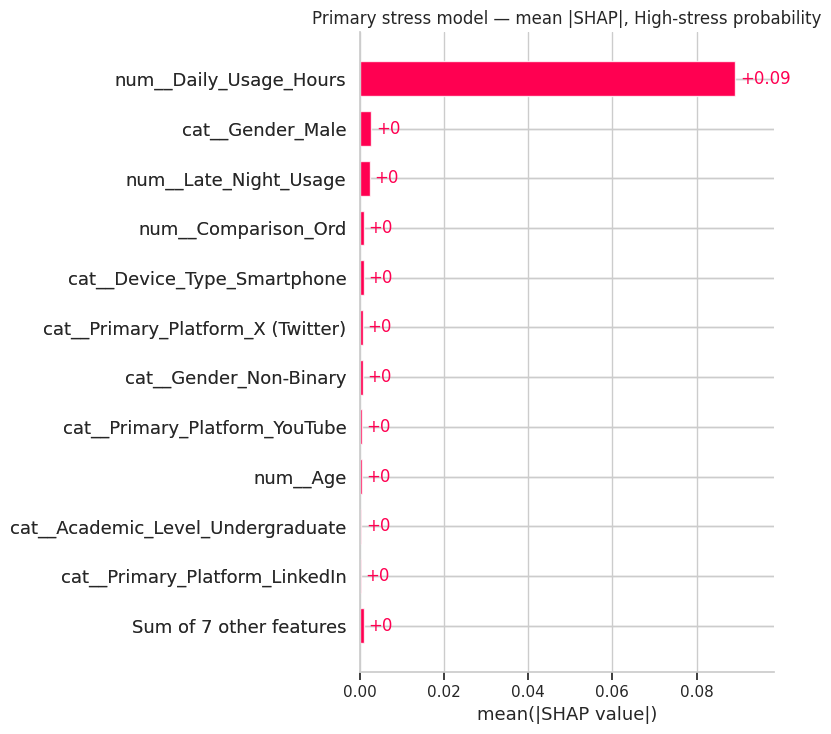

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


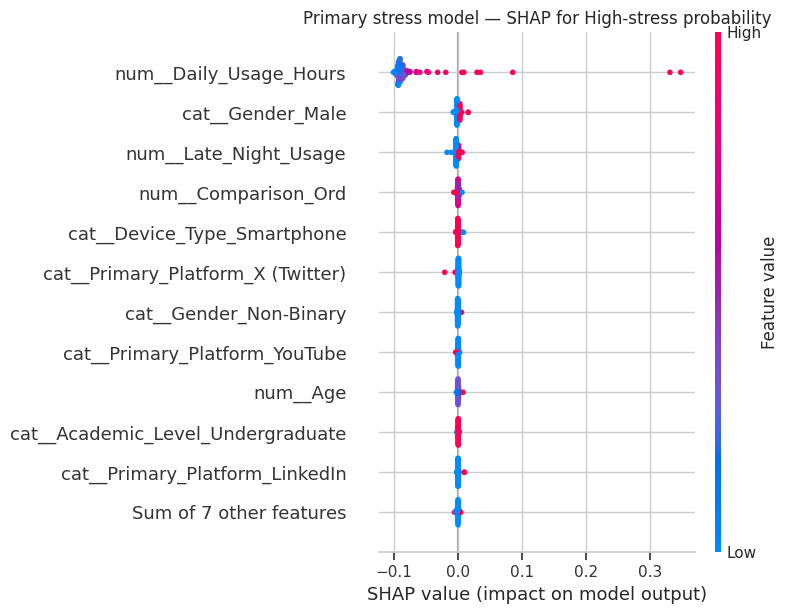


Observed High-stress cases in explained sample: 3
REPRESENTATIVE OBSERVED HIGH-STRESS CASE — ORIGINAL INPUTS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Gender,Academic_Level,Primary_Platform,Device_Type,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Comparison_Ord,Late_Night_Usage
1806,Male,Undergraduate,TikTok,Smartphone,22,11.5,1.5,4,0


Predicted probabilities (Low, Moderate, High): [0.0101 0.5513 0.4387]


/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetim

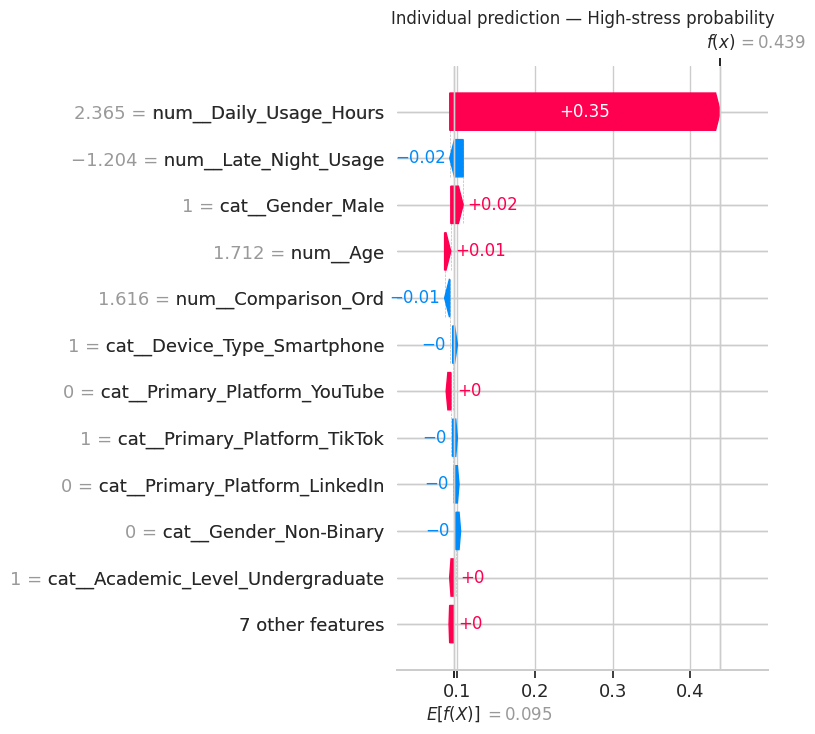


Interpretation notes:
- Values are changes in predicted class probability relative to the background-average prediction.
- Attributions explain the fitted model, not causal effects.
- Independent masking ignores dependencies between predictors and one-hot groups; results depend on the background sample.
- Only a small number of High-stress cases is in the explained sample.
- No models were fitted, tuned, or modified.


In [37]:
# ============ SECTION 5.3B: SHAP — PRIMARY STRESS MODEL (ORDINAL LOGIT) ============
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display

MODEL_NAME = "Stress primary"
BACKGROUND_N = 50
EXPLAIN_N = 100
LABELS = np.array([0, 1, 2])
CLASS_NAMES = ["Low", "Moderate", "High"]

# 1. Validate frozen pipeline and inputs.
spec = final_specs[MODEL_NAME]
record = heldout_predictions[MODEL_NAME]
assert spec["task"] == "Stress tier"

pipeline = spec["model"]
preprocessor = pipeline.named_steps["pre"]
estimator = pipeline.named_steps["m"]

X_dev = TASKS[spec["task"]]["data"].loc[:, spec["features"]]
X_test = record["rows"].loc[:, spec["features"]]

assert hasattr(preprocessor, "get_feature_names_out")
feature_names = np.asarray(preprocessor.get_feature_names_out()).astype(str)

model_classes = np.asarray(estimator.classes_)
assert set(model_classes) == set(LABELS)
class_order = [np.flatnonzero(model_classes == c)[0] for c in LABELS]

def to_dense(frame):
    z = preprocessor.transform(frame)
    if sparse.issparse(z):
        z = z.toarray()
    return np.asarray(z, dtype=float)

def proba_transformed(z):
    # Probabilities in fixed Low / Moderate / High order.
    return np.asarray(estimator.predict_proba(np.asarray(z, dtype=float)))[:, class_order]

# 2. Reproducible samples.
background_raw = X_dev.sample(n=min(BACKGROUND_N, len(X_dev)), random_state=SEED)
explain_raw = X_test.sample(n=min(EXPLAIN_N, len(X_test)), random_state=SEED)

background_z = to_dense(background_raw)
explain_z = to_dense(explain_raw)

# 3. Confirm the estimator-on-transformed-data path equals the full pipeline.
pipeline_proba = np.asarray(pipeline.predict_proba(explain_raw))[:, class_order]
np.testing.assert_allclose(
    proba_transformed(explain_z), pipeline_proba, rtol=1e-6, atol=1e-8,
    err_msg="Transformed-space probabilities differ from the pipeline. Stop here."
)

# 4. Explain all three class probabilities.
masker = shap.maskers.Independent(background_z, max_samples=len(background_z))
explainer = shap.Explainer(
    proba_transformed,
    masker,
    algorithm="permutation",
    feature_names=feature_names.tolist(),
    output_names=CLASS_NAMES,
    seed=SEED,
)
stress_shap = explainer(explain_z, max_evals=2 * len(feature_names) + 1)

# 5. Additivity check in probability units.
reconstructed = stress_shap.base_values + stress_shap.values.sum(axis=1)
np.testing.assert_allclose(
    reconstructed, pipeline_proba, rtol=1e-5, atol=1e-5,
    err_msg="SHAP contributions do not reconstruct predicted probabilities."
)

print(f"SHAP version: {shap.__version__}")
print(f"Background rows (development): {len(background_raw)}")
print(f"Held-out rows explained: {len(explain_raw)}")
print("Additive reconstruction check passed.")

# 6. Global importance by class.
importance = pd.DataFrame(
    np.abs(stress_shap.values).mean(axis=0),
    index=feature_names,
    columns=[f"Mean_abs_SHAP_{c}" for c in CLASS_NAMES],
)
importance["Mean_across_classes"] = importance.mean(axis=1)
stress_shap_importance = importance.sort_values("Mean_across_classes", ascending=False)

print("\nGLOBAL SHAP IMPORTANCE — probability units")
display(stress_shap_importance.round(5))

# 7. High-stress class: bar, beeswarm.
high_idx = 2
shap.plots.bar(stress_shap[:, :, high_idx], max_display=12, show=False)
plt.title("Primary stress model — mean |SHAP|, High-stress probability")
plt.tight_layout(); plt.show()

shap.plots.beeswarm(stress_shap[:, :, high_idx], max_display=12, show=False)
plt.title("Primary stress model — SHAP for High-stress probability")
plt.tight_layout(); plt.show()

# 8. One representative High-stress case: the observed High-stress record in the
# explained sample with predicted High probability nearest the sample's
# upper quartile (not selected for being a success or failure).
explain_positions = record["rows"].index.get_indexer(explain_raw.index)
observed_explained = np.asarray(record["y"])[explain_positions]
high_cases = np.flatnonzero(observed_explained == 2)

print(f"\nObserved High-stress cases in explained sample: {len(high_cases)}")

if len(high_cases) > 0:
    target = np.quantile(pipeline_proba[high_cases, 2], 0.75)
    local_pos = int(high_cases[np.argmin(np.abs(pipeline_proba[high_cases, 2] - target))])

    print("REPRESENTATIVE OBSERVED HIGH-STRESS CASE — ORIGINAL INPUTS")
    display(explain_raw.iloc[[local_pos]])
    print("Predicted probabilities (Low, Moderate, High):",
          np.round(pipeline_proba[local_pos], 4))

    shap.plots.waterfall(stress_shap[local_pos, :, high_idx], max_display=12, show=False)
    plt.title("Individual prediction — High-stress probability")
    plt.tight_layout(); plt.show()

print(
    "\nInterpretation notes:\n"
    "- Values are changes in predicted class probability relative to the "
    "background-average prediction.\n"
    "- Attributions explain the fitted model, not causal effects.\n"
    "- Independent masking ignores dependencies between predictors "
    "and one-hot groups; results depend on the background sample.\n"
    "- Only a small number of High-stress cases is in the explained sample.\n"
    "- No models were fitted, tuned, or modified."
)

### 5.3C SHAP — sleep-quality model
SHAP for the ordinal sleep-quality model (background n = 50, explained n = 100, to keep the run time practical in Colab).

**Key observation.** Daily usage dominates: its mean absolute SHAP contribution is approximately **0.130 probability units**, averaged across the five class probabilities, and **0.648 points on the expected sleep-quality score scale**. These summarise different model outputs and are not directly comparable. The expected-score summary treats scores 1–5 as equally spaced for interpretation only. The other features have much smaller contributions.

**Reading across methods.** Permutation importance, PDP and SHAP all point to daily usage as the dominant predictor. Because all three explain the *same* fitted model, this agreement shows the explanations are internally consistent. It is not independent evidence that usage drives sleep quality. Score 5 is rare, so its attributions are the least reliable.

Background rows (development): 50
Held-out rows explained: 100
Additive reconstruction check passed.

GLOBAL SHAP IMPORTANCE — probability units


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Mean_abs_SHAP_Score 1,Mean_abs_SHAP_Score 2,Mean_abs_SHAP_Score 3,Mean_abs_SHAP_Score 4,Mean_abs_SHAP_Score 5,Mean_across_scores
num__Daily_Usage_Hours,0.20829,0.14133,0.14962,0.12717,0.02209,0.12970
num__Late_Night_Usage,0.00491,0.00555,0.00365,0.00619,0.00139,0.00434
cat__Academic_Level_Undergraduate,0.00464,0.00454,0.00358,0.00479,0.00108,0.00373
cat__Primary_Platform_X (Twitter),0.00184,0.00138,0.00131,0.00170,0.00038,0.00132
cat__Primary_Platform_Snapchat,0.00165,0.00153,0.00103,0.00175,0.00042,0.00128
cat__Academic_Level_Postgraduate,0.00160,0.00159,0.00121,0.00152,0.00030,0.00124
cat__Gender_Male,0.00139,0.00137,0.00105,0.00147,0.00033,0.00112
cat__Primary_Platform_Reddit,0.00149,0.00145,0.00108,0.00131,0.00026,0.00112
num__Age,0.00136,0.00136,0.00105,0.00138,0.00029,0.00109
cat__Gender_Prefer not to say,0.00177,0.00084,0.00075,0.00101,0.00024,0.00092


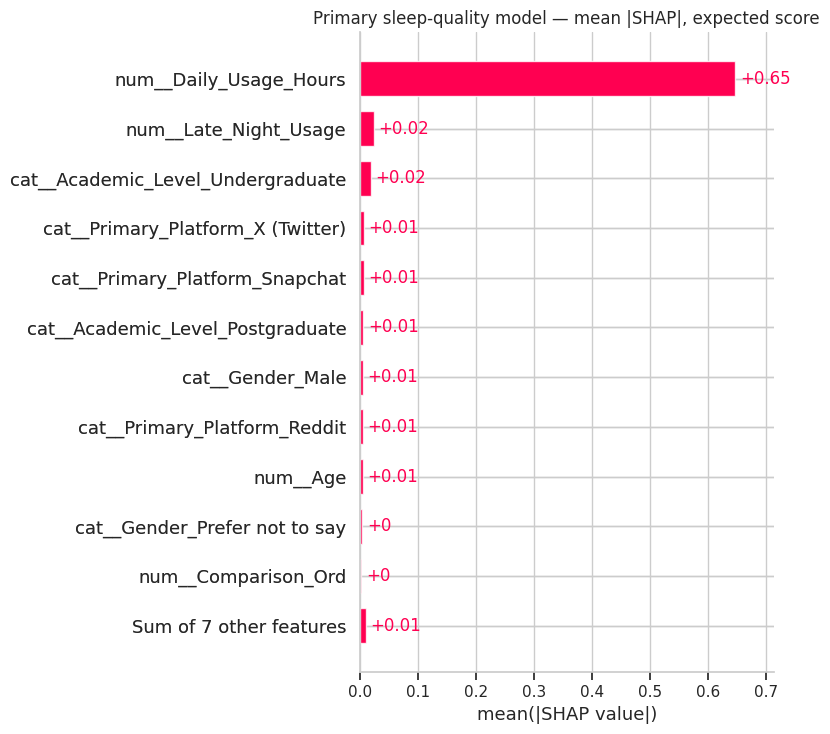

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


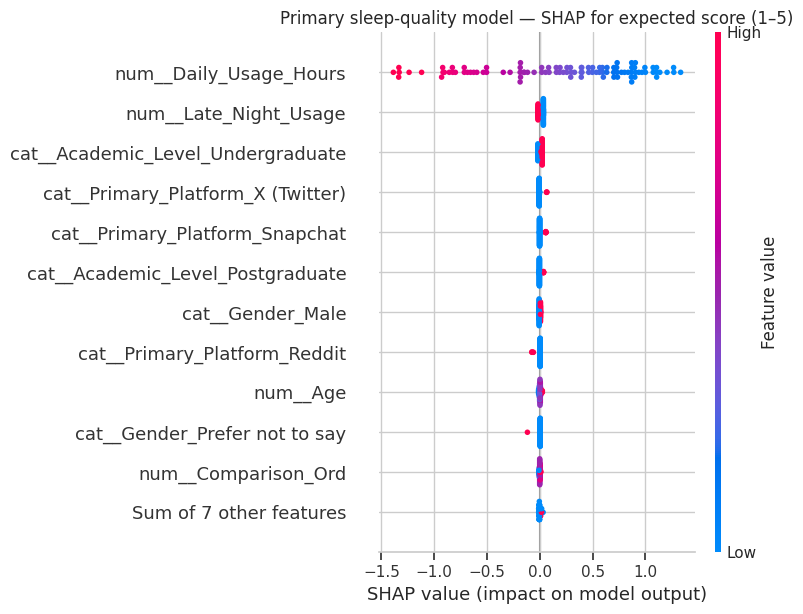


Observed score 1–2 cases in explained sample: 46
REPRESENTATIVE OBSERVED LOW-SCORE CASE — ORIGINAL INPUTS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Gender,Academic_Level,Primary_Platform,Device_Type,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Comparison_Ord,Late_Night_Usage
1174,Female,High School,TikTok,Smartphone,16,5.8,0.7,2,1


Observed score: 2
Predicted probabilities (scores 1–5): [0.1921 0.5149 0.2537 0.0358 0.0035]
Predicted expected score: 2.144


/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetim

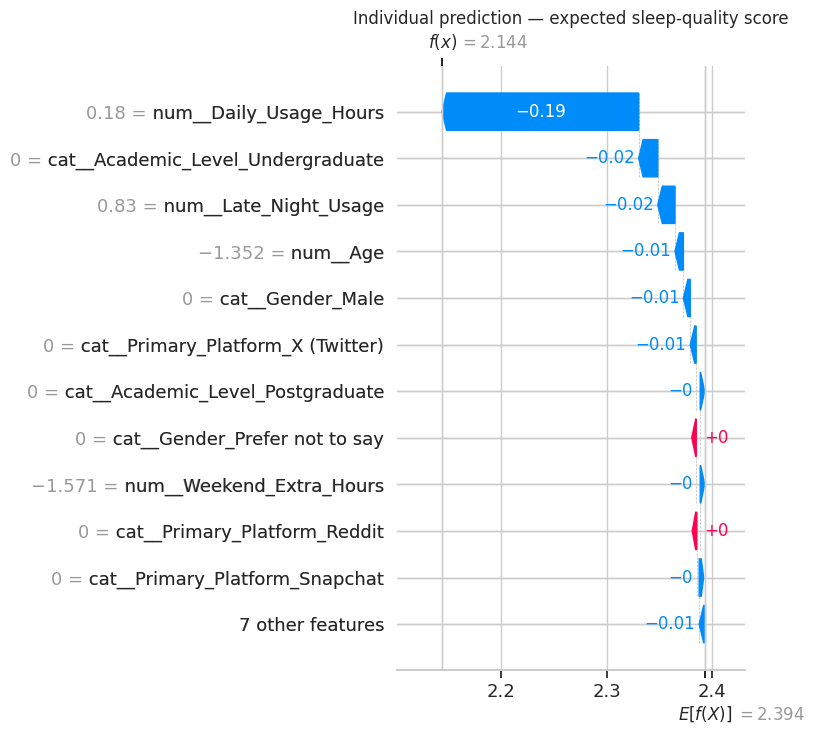


Interpretation notes:
- Positive values raise predicted sleep quality; negative values lower it.
- The expected-score plots summarise the five probabilities as one number and assume equal spacing between scores for that summary only.
- Attributions explain the fitted model, not causal effects.
- Independent masking ignores dependencies between predictors and one-hot groups; results depend on the background sample.
- Score 5 is rare, so its attributions are least reliable.
- No models were fitted, tuned, or modified.


In [38]:
# ============ SECTION 5.3C: SHAP — PRIMARY SLEEP-QUALITY MODEL ============
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display

MODEL_NAME = "Sleep quality primary"
BACKGROUND_N = 50
EXPLAIN_N = 100
LABELS = np.array([1, 2, 3, 4, 5])
CLASS_NAMES = [f"Score {c}" for c in LABELS]

# 1. Validate frozen pipeline and inputs.
spec = final_specs[MODEL_NAME]
record = heldout_predictions[MODEL_NAME]
assert spec["task"] == "Sleep quality"

pipeline = spec["model"]
preprocessor = pipeline.named_steps["pre"]
estimator = pipeline.named_steps["m"]

X_dev = TASKS[spec["task"]]["data"].loc[:, spec["features"]]
X_test = record["rows"].loc[:, spec["features"]]

assert hasattr(preprocessor, "get_feature_names_out")
feature_names = np.asarray(preprocessor.get_feature_names_out()).astype(str)

model_classes = np.asarray(estimator.classes_)
assert set(model_classes) == set(LABELS)
class_order = [np.flatnonzero(model_classes == c)[0] for c in LABELS]

def to_dense(frame):
    z = preprocessor.transform(frame)
    if sparse.issparse(z):
        z = z.toarray()
    return np.asarray(z, dtype=float)

def proba_transformed(z):
    # Probabilities in fixed score order 1..5.
    return np.asarray(estimator.predict_proba(np.asarray(z, dtype=float)))[:, class_order]

# 2. Reproducible samples.
background_raw = X_dev.sample(n=min(BACKGROUND_N, len(X_dev)), random_state=SEED)
explain_raw = X_test.sample(n=min(EXPLAIN_N, len(X_test)), random_state=SEED)

background_z = to_dense(background_raw)
explain_z = to_dense(explain_raw)

# 3. Confirm estimator-on-transformed-data equals the full pipeline.
pipeline_proba = np.asarray(pipeline.predict_proba(explain_raw))[:, class_order]
np.testing.assert_allclose(
    proba_transformed(explain_z), pipeline_proba, rtol=1e-6, atol=1e-8,
    err_msg="Transformed-space probabilities differ from the pipeline. Stop here."
)

# 4. Explain all five class probabilities.
masker = shap.maskers.Independent(background_z, max_samples=len(background_z))
explainer = shap.Explainer(
    proba_transformed,
    masker,
    algorithm="permutation",
    feature_names=feature_names.tolist(),
    output_names=CLASS_NAMES,
    seed=SEED,
)
quality_shap = explainer(explain_z, max_evals=2 * len(feature_names) + 1)

# 5. Additivity check in probability units.
reconstructed = quality_shap.base_values + quality_shap.values.sum(axis=1)
np.testing.assert_allclose(
    reconstructed, pipeline_proba, rtol=1e-5, atol=1e-5,
    err_msg="SHAP contributions do not reconstruct predicted probabilities."
)

print(f"Background rows (development): {len(background_raw)}")
print(f"Held-out rows explained: {len(explain_raw)}")
print("Additive reconstruction check passed.")

# 6. Global importance by score.
importance = pd.DataFrame(
    np.abs(quality_shap.values).mean(axis=0),
    index=feature_names,
    columns=[f"Mean_abs_SHAP_{c}" for c in CLASS_NAMES],
)
importance["Mean_across_scores"] = importance.mean(axis=1)
quality_shap_importance = importance.sort_values("Mean_across_scores", ascending=False)

print("\nGLOBAL SHAP IMPORTANCE — probability units")
display(quality_shap_importance.round(5))

# 7. Expected-score SHAP: one ordered summary of the five probabilities.
# Contribution to expected score = sum_k score_k * SHAP_k (linear, so exact).
expected_values = np.tensordot(quality_shap.values, LABELS.astype(float), axes=([2], [0]))
expected_base = quality_shap.base_values @ LABELS.astype(float)
expected_pred = pipeline_proba @ LABELS.astype(float)

np.testing.assert_allclose(
    expected_base + expected_values.sum(axis=1), expected_pred, rtol=1e-5, atol=1e-5
)

expected_shap = shap.Explanation(
    values=expected_values,
    base_values=expected_base,
    data=explain_z,
    feature_names=feature_names.tolist(),
)

shap.plots.bar(expected_shap, max_display=12, show=False)
plt.title("Primary sleep-quality model — mean |SHAP|, expected score")
plt.tight_layout(); plt.show()

shap.plots.beeswarm(expected_shap, max_display=12, show=False)
plt.title("Primary sleep-quality model — SHAP for expected score (1–5)")
plt.tight_layout(); plt.show()

# 8. One observed low-score case (score 1 or 2) from the explained sample,
# with predicted expected score nearest the median of such cases.
explain_positions = record["rows"].index.get_indexer(explain_raw.index)
observed_explained = np.asarray(record["y"])[explain_positions]
low_cases = np.flatnonzero(observed_explained <= 2)

print(f"\nObserved score 1–2 cases in explained sample: {len(low_cases)}")

if len(low_cases) > 0:
    target = np.median(expected_pred[low_cases])
    local_pos = int(low_cases[np.argmin(np.abs(expected_pred[low_cases] - target))])

    print("REPRESENTATIVE OBSERVED LOW-SCORE CASE — ORIGINAL INPUTS")
    display(explain_raw.iloc[[local_pos]])
    print("Observed score:", int(observed_explained[local_pos]))
    print("Predicted probabilities (scores 1–5):",
          np.round(pipeline_proba[local_pos], 4))
    print("Predicted expected score:", round(float(expected_pred[local_pos]), 3))

    shap.plots.waterfall(expected_shap[local_pos], max_display=12, show=False)
    plt.title("Individual prediction — expected sleep-quality score")
    plt.tight_layout(); plt.show()

print(
    "\nInterpretation notes:\n"
    "- Positive values raise predicted sleep quality; negative values lower it.\n"
    "- The expected-score plots summarise the five probabilities as one number "
    "and assume equal spacing between scores for that summary only.\n"
    "- Attributions explain the fitted model, not causal effects.\n"
    "- Independent masking ignores dependencies between predictors and "
    "one-hot groups; results depend on the background sample.\n"
    "- Score 5 is rare, so its attributions are least reliable.\n"
    "- No models were fitted, tuned, or modified."
)

### 5.4 Interactive what-if explorer
An `ipywidgets` panel that changes one respondent's inputs and shows how the three model predictions respond. It is meant for understanding model behaviour and for the viva demonstration, **not** for individual diagnosis or decision-making.

The widget needs a live Colab or Jupyter kernel and does not display in static viewers such as GitHub.

In [39]:
# ============ SECTION 5.4: INTERACTIVE WHAT-IF EXPLORER ============
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

MODELS = {
    "stress": "Stress primary",
    "quality": "Sleep quality primary",
    "duration": "Sleep duration primary",
}
STRESS_LABELS = np.array([0, 1, 2])
STRESS_NAMES = ["Low", "Moderate", "High"]
QUALITY_LABELS = np.array([1, 2, 3, 4, 5])

# 1. Validate frozen models and collect the union of predictors.
for name in MODELS.values():
    assert name in final_specs, f"Missing model: {name}"

all_features = []
for name in MODELS.values():
    for f in final_specs[name]["features"]:
        if f not in all_features:
            all_features.append(f)

dev = TASKS["Stress tier"]["data"]
missing = [f for f in all_features if f not in dev.columns]
assert not missing, f"Predictors missing from development data: {missing}"

# 2. Held-out MAE for the duration model (typical-error reference only).
dur_rec = heldout_predictions[MODELS["duration"]]
duration_mae = float(np.mean(np.abs(
    np.asarray(dur_rec["y"], float) - np.asarray(dur_rec["pred"], float)
)))

# 3. Build one widget per predictor from development-data ranges.
controls, ranges = {}, {}
for f in all_features:
    col = dev[f].dropna()
    if pd.api.types.is_numeric_dtype(col):
        if col.nunique() <= 6:
            options = sorted(col.unique().tolist())
            controls[f] = widgets.Dropdown(
                options=options, value=col.mode().iloc[0], description=f,
                style={"description_width": "170px"},
                layout=widgets.Layout(width="420px"))
        else:
            is_int = np.allclose(col, np.round(col))
            controls[f] = widgets.FloatSlider(
                min=float(col.min()), max=float(col.max()),
                value=float(col.median()), step=1.0 if is_int else 0.1,
                description=f, continuous_update=False,
                style={"description_width": "170px"},
                layout=widgets.Layout(width="420px"))
            ranges[f] = tuple(col.quantile([0.025, 0.975]))
    else:
        options = sorted(col.astype(str).unique().tolist())
        controls[f] = widgets.Dropdown(
            options=options, value=col.astype(str).mode().iloc[0],
            description=f, style={"description_width": "170px"},
            layout=widgets.Layout(width="420px"))

out = widgets.Output()

def ordered_proba(model, X, labels):
    est = model.named_steps["m"]
    classes = np.asarray(est.classes_)
    order = [np.flatnonzero(classes == c)[0] for c in labels]
    return np.asarray(model.predict_proba(X))[0, order]

def refresh(_=None):
    row = pd.DataFrame([{f: controls[f].value for f in all_features}])
    # Restore original dtypes so the frozen preprocessors behave as in training.
    for f in all_features:
        row[f] = row[f].astype(dev[f].dtype) if not pd.api.types.is_numeric_dtype(dev[f]) else row[f]

    inputs = {}
    for key, name in MODELS.items():
        inputs[key] = row.loc[:, final_specs[name]["features"]]

    p_stress = ordered_proba(final_specs[MODELS["stress"]]["model"],
                             inputs["stress"], STRESS_LABELS)
    p_quality = ordered_proba(final_specs[MODELS["quality"]]["model"],
                              inputs["quality"], QUALITY_LABELS)
    expected_quality = float(p_quality @ QUALITY_LABELS)
    duration_pred = float(np.asarray(
        final_specs[MODELS["duration"]]["model"].predict(inputs["duration"]))[0])

    with out:
        clear_output(wait=True)
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))

        axes[0].bar(STRESS_NAMES, p_stress,
                    color=["#16A34A", "#F59E0B", "#DC2626"])
        axes[0].set(title="Stress tier — predicted probability",
                    ylim=(0, 1), ylabel="Probability")

        axes[1].bar([str(c) for c in QUALITY_LABELS], p_quality,
                    color="#2563EB")
        axes[1].set(title=f"Sleep quality — expected score {expected_quality:.2f}",
                    xlabel="Score", ylim=(0, 1), ylabel="Probability")

        axes[2].barh(["Predicted"], [duration_pred], color="#2563EB",
                     xerr=[[duration_mae], [duration_mae]], capsize=6)
        axes[2].set(title=f"Sleep duration — {duration_pred:.2f} h",
                    xlim=(3, 10), xlabel="Hours (± held-out MAE)")

        for ax in axes:
            ax.grid(alpha=0.2)
        plt.tight_layout()
        plt.show()

        flagged = [
            f"{f} = {controls[f].value:.2f} (development central 95%: "
            f"{lo:.2f}–{hi:.2f})"
            for f, (lo, hi) in ranges.items()
            if not (lo <= controls[f].value <= hi)
        ]
        if flagged:
            print("WARNING — input outside the development central 95% range; "
                  "predictions are less reliable here:")
            for item in flagged:
                print("  -", item)

        print(f"\nDuration band is ± held-out MAE ({duration_mae:.2f} h): "
              "a typical-error reference, not a prediction interval.")
        print("Exploratory model output from survey data. Not causal, "
              "not diagnostic, and not health advice.")

for control in controls.values():
    control.observe(refresh, names="value")

display(widgets.VBox(list(controls.values())), out)
refresh()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Output()

### 5.5 Interpretation summary
Brings permutation importance, PDP ranges and SHAP rankings together in one table and saves it to `section5_interpretation_summary.csv`, which the report uses.

**Reading the table.** Daily usage is the top predictor for every outcome under every method. The "second" predictors are all near zero and should be read as noise-level. For duration, `Gender (0.0000)` is an arbitrary tie among predictors the Elastic Net set to zero, not a meaningful ranking. Importance values are not comparable across outcomes because the metrics and units differ.

In [40]:
# ============ SECTION 5.5: INTERPRETATION SUMMARY TABLE ============
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Validate that earlier interpretation objects exist.
required = [
    "permutation_tables", "duration_shap_importance",
    "stress_shap_importance", "quality_shap_importance", "pdp_results",
]
missing = [r for r in required if r not in globals()]
assert not missing, f"Run the earlier Section 5 cells first. Missing: {missing}"

def top_perm(name):
    t = permutation_tables[name].iloc[0]
    return t["Feature"], float(t["Mean_importance"])

def second_perm(name):
    t = permutation_tables[name].iloc[1]
    return t["Feature"], float(t["Mean_importance"])

rows = []

# Stress
f1, v1 = top_perm("Stress primary")
f2, v2 = second_perm("Stress primary")
s = stress_shap_importance
stress_pdp = pdp_results["Stress primary"]["values"]
rows.append({
    "Outcome": "Stress tier (Ordinal Logit)",
    "Permutation_top_predictor": f"{f1} ({v1:.4f} Macro-F1 drop)",
    "Permutation_second": f"{f2} ({v2:.4f})",
    "SHAP_top_encoded_predictor": s.index[0],
    "SHAP_top_value": f"{s['Mean_across_classes'].iloc[0]:.4f} (mean |SHAP|, probability)",
    "PDP_direction_over_usage": (
        f"Low {stress_pdp[0, 0]:.2f}→{stress_pdp[-1, 0]:.2f}; "
        f"High {stress_pdp[0, 2]:.2f}→{stress_pdp[-1, 2]:.2f}"
    ),
})

# Sleep quality
f1, v1 = top_perm("Sleep quality primary")
f2, v2 = second_perm("Sleep quality primary")
q = quality_shap_importance
q_pdp = pdp_results["Sleep quality primary"]["values"]
rows.append({
    "Outcome": "Sleep quality (Ordinal Logit)",
    "Permutation_top_predictor": f"{f1} ({v1:.4f} QWK drop)",
    "Permutation_second": f"{f2} ({v2:.4f})",
    "SHAP_top_encoded_predictor": q.index[0],
    "SHAP_top_value": f"{q['Mean_across_scores'].iloc[0]:.4f} (mean |SHAP|, probability)",
    "PDP_direction_over_usage": f"Expected score {q_pdp[0]:.2f}→{q_pdp[-1]:.2f}",
})

# Sleep duration
f1, v1 = top_perm("Sleep duration primary")
f2, v2 = second_perm("Sleep duration primary")
d = duration_shap_importance
d_pdp = pdp_results["Sleep duration primary"]["values"]
rows.append({
    "Outcome": "Sleep duration (Elastic Net)",
    "Permutation_top_predictor": f"{f1} ({v1:.4f} h MAE increase)",
    "Permutation_second": f"{f2} ({v2:.4f})",
    "SHAP_top_encoded_predictor": d["Transformed_feature"].iloc[0],
    "SHAP_top_value": f"{d['Mean_absolute_SHAP_hours'].iloc[0]:.4f} (mean |SHAP|, hours)",
    "PDP_direction_over_usage": f"Predicted hours {d_pdp[0]:.2f}→{d_pdp[-1]:.2f}",
})

interpretation_summary = pd.DataFrame(rows)
display(interpretation_summary)

interpretation_summary.to_csv("section5_interpretation_summary.csv", index=False)
print("Saved: section5_interpretation_summary.csv")

print(
    "\nReading notes:\n"
    "- Permutation importance, SHAP and PDP describe model reliance, not causal effects.\n"
    "- Importance values are not comparable across outcomes (different metrics and units).\n"
    "- Near-zero predictors should not be ranked against each other.\n"
    "- All interpretation used frozen models; no refitting or tuning occurred."
)

,Outcome,Permutation_top_predictor,Permutation_second,SHAP_top_encoded_predictor,SHAP_top_value,PDP_direction_over_usage
0,Stress tier (Ordinal Logit),Daily_Usage_Hours (0.3143 Macro-F1 drop),Gender (0.0050),num__Daily_Usage_Hours,"0.1776 (mean |SHAP|, probability)",Low 0.92→0.01; High 0.00→0.59
1,Sleep quality (Ordinal Logit),Daily_Usage_Hours (0.6474 QWK drop),Weekend_Extra_Hours (0.0017),num__Daily_Usage_Hours,"0.1297 (mean |SHAP|, probability)",Expected score 3.54→1.03
2,Sleep duration (Elastic Net),Daily_Usage_Hours (0.4700 h MAE increase),Gender (0.0000),num__Daily_Usage_Hours,"0.6662 (mean |SHAP|, hours)",Predicted hours 7.78→4.50


Saved: section5_interpretation_summary.csv

Reading notes:
- Permutation importance, SHAP and PDP describe model reliance, not causal effects.
- Importance values are not comparable across outcomes (different metrics and units).
- Near-zero predictors should not be ranked against each other.
- All interpretation used frozen models; no refitting or tuning occurred.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 5.6 Summary of interpretation findings
- **One dominant predictor.** All three primary models rely almost entirely on `Daily_Usage_Hours`. Weekend hours, late-night use, platform, device, comparison and demographics add little once usage is known.
- **Link to RQ4.** The tree-based models did not beat the interpretable baselines (see 4.2B), and the interpretation here explains why: little signal is left beyond one mostly monotonic predictor, so added model flexibility has little to exploit.
- **Strength of the usage effect.** Predicted stress, sleep quality and sleep duration all move across most of their ranges over the observed usage range. This relationship is unusually clean for self-reported behavioural data. It should be discussed in the report as a limitation, together with how the dataset was collected or generated.
- **What this does not show.** These are explanations of fitted models. They do not show that social media use causes stress or changes sleep. They also do not show that other predictors are unimportant in the population, because the models were trained on one dataset with limited feature coverage.
- **Held-out use.** The held-out partition is a single 20% split of the same dataset, scored once (see 0.6). It is an internal hold-out, not an external validation on independent data.

# 6 · CONSOLIDATION & REPRODUCIBILITY

This section consolidates stored results for report preparation and records information needed to support reproduction of the analysis. It does not fit models, tune hyperparameters or generate new held-out predictions.

The exported results retain the evaluation limitations documented in Section 0.6. In particular, the held-out results come from a single internal split of the same dataset, not an external validation.

### 6.1 Inventory of stored result objects

The following cell lists the pandas DataFrames currently available in the notebook session, including their dimensions and column names. It also lists potentially relevant non-DataFrame objects.

This is a diagnostic inventory, not a validation of numerical correctness or completeness. The explicit checks for required tables, columns and result consistency are performed in Section 6.2.

In [41]:
# ============ SECTION 6.1: INSPECT STORED RESULTS ============
import pandas as pd

dataframes = {
    name: value
    for name, value in globals().items()
    if isinstance(value, pd.DataFrame)
}

if not dataframes:
    print("No pandas DataFrames found in the current notebook session.")
else:
    print(f"Found {len(dataframes)} DataFrame(s):\n")

    for name, frame in sorted(dataframes.items()):
        print(f"{name}: {frame.shape[0]} rows × {frame.shape[1]} columns")
        print("  Columns:", list(frame.columns))
        print()

print("Potentially relevant non-DataFrame result objects:")
keywords = ("metric", "eval", "boot", "heldout", "holdout", "result", "ci")

for name, value in sorted(globals().items()):
    if any(word in name.lower() for word in keywords):
        if not isinstance(value, pd.DataFrame):
            print(f"  {name}: {type(value).__name__}")

Found 83 DataFrame(s):

X: 900 rows × 9 columns
  Columns: ['Gender', 'Academic_Level', 'Primary_Platform', 'Device_Type', 'Age', 'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Comparison_Ord', 'Late_Night_Usage']

X_check: 900 rows × 9 columns
  Columns: ['Gender', 'Academic_Level', 'Primary_Platform', 'Device_Type', 'Age', 'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Comparison_Ord', 'Late_Night_Usage']

X_dev: 3600 rows × 9 columns
  Columns: ['Gender', 'Academic_Level', 'Primary_Platform', 'Device_Type', 'Age', 'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Comparison_Ord', 'Late_Night_Usage']

X_development: 3600 rows × 9 columns
  Columns: ['Gender', 'Academic_Level', 'Primary_Platform', 'Device_Type', 'Age', 'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Comparison_Ord', 'Late_Night_Usage']

X_heldout: 900 rows × 9 columns
  Columns: ['Gender', 'Academic_Level', 'Primary_Platform', 'Device_Type', 'Age', 'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Comparison_Ord', 'Late_Night_Usage']


### 6.2 Final consolidation and export

The following cell checks the required result tables and columns, model-name consistency, duplicate model–task–metric combinations and the ordering of finite confidence bounds.

It then:

- Combines stored held-out metrics with model-selection metadata.
- Produces a rounded display table for report drafting while preserving the stored numerical values in the master results table.
- Exports model selection, split information, calibration diagnostics, duration diagnostics, subgroup results and the interpretation summary.
- Records the current Python version, package versions, seed, bootstrap replicate count and selected-model metadata in `section6_reproducibility_record.json`.

Confidence bounds are copied unchanged from Section 4.3B. Their interpretation must follow the bootstrap method and limitations documented there; exporting them does not account for the earlier inspection of held-out results.

The environment record describes the session at the time this cell is run. It does not establish which package versions generated earlier saved outputs. Reproduction also requires the dataset, split logic, custom estimators, preprocessing pipelines and configuration defined elsewhere in the notebook.

Nested cross-validation and additional diagnostic tables are exported separately in Section 6.3.

In [42]:
# ============ SECTION 6: FINAL CONSOLIDATION AND REPRODUCIBILITY ============
import json
import platform
from importlib import metadata

import numpy as np
import pandas as pd
from IPython.display import display

# 1. Validate the exact stored results and schemas.
required_tables = {
    "heldout_metrics": [
        "Model", "Task", "Metric", "Estimate",
        "CI_low", "CI_high", "Test_n",
    ],
    "selection_summary": [
        "Model", "Candidate", "Role",
        "Predictor count", "Development records",
    ],
    "interpretation_summary": [
        "Outcome", "Permutation_top_predictor", "Permutation_second",
        "SHAP_top_encoded_predictor", "SHAP_top_value",
        "PDP_direction_over_usage",
    ],
    "calibration_summary": [
        "Model", "Class", "Support", "Class_Brier",
    ],
    "duration_diagnostic_summary": [
        "Model", "N", "MAE_hours", "Mean_residual_hours",
    ],
    "subgroup_counts": [
        "Model", "Grouping", "Group", "N", "Metrics_status",
    ],
    "subgroup_metrics": [
        "Model", "Grouping", "Group", "N", "Metrics_status",
    ],
    "split_summary": ["Development", "Held-out"],
}

for object_name, required_columns in required_tables.items():
    assert object_name in globals(), f"Missing object: {object_name}"
    frame = globals()[object_name]
    assert isinstance(frame, pd.DataFrame), (
        f"{object_name} is not a pandas DataFrame."
    )
    missing_columns = set(required_columns) - set(frame.columns)
    assert not missing_columns, (
        f"{object_name}: missing columns {sorted(missing_columns)}"
    )

assert "SEED" in globals(), "The original SEED is not available."
assert "N_BOOT" in globals(), "The original N_BOOT is not available."

assert not heldout_metrics.empty
assert not selection_summary["Model"].duplicated().any(), (
    "Model names are not unique in selection_summary."
)
assert not heldout_metrics.duplicated(
    ["Model", "Task", "Metric"]
).any(), "Duplicate model/task/metric combinations found."

unmatched_models = (
    set(heldout_metrics["Model"]) - set(selection_summary["Model"])
)
assert not unmatched_models, (
    f"Held-out models missing from selection_summary: {unmatched_models}"
)

# Check ordering wherever both confidence bounds are finite.
bounds = heldout_metrics[["CI_low", "CI_high"]].apply(
    pd.to_numeric, errors="raise"
)
finite_bounds = np.isfinite(bounds).all(axis=1)
assert (
    bounds.loc[finite_bounds, "CI_low"]
    <= bounds.loc[finite_bounds, "CI_high"]
).all(), "At least one confidence interval has reversed bounds."

# 2. Consolidate held-out results with selection metadata.
# Keep all stored metrics and models, including secondary comparisons.
master_results = heldout_metrics.copy().merge(
    selection_summary[
        ["Model", "Candidate", "Role",
         "Predictor count", "Development records"]
    ],
    on="Model",
    how="left",
    validate="many_to_one",
)

master_results = master_results[
    [
        "Task", "Model", "Candidate", "Role",
        "Predictor count", "Development records",
        "Test_n", "Metric", "Estimate", "CI_low", "CI_high",
    ]
].sort_values(
    ["Task", "Model", "Metric"],
    kind="stable",
    ignore_index=True,
)

assert len(master_results) == len(heldout_metrics)

print("MASTER HELD-OUT RESULTS — ALL STORED METRICS")
display(master_results.round(4))

print(
    "Confidence bounds are copied unchanged from Section 4.3B. "
    "Use that section's documented confidence level and bootstrap method."
)

# 3. Compact display table for report drafting.
# Raw numeric values remain unchanged in master_results.
report_results_display = master_results.copy()

def format_estimate_and_bounds(row):
    estimate = row["Estimate"]
    low = row["CI_low"]
    high = row["CI_high"]

    if pd.isna(estimate):
        return "Not available"
    if pd.isna(low) or pd.isna(high):
        return f"{estimate:.3f} (CI unavailable)"
    return f"{estimate:.3f} [{low:.3f}, {high:.3f}]"

report_results_display["Estimate [CI bounds]"] = (
    report_results_display.apply(format_estimate_and_bounds, axis=1)
)

report_results_display = report_results_display[
    ["Task", "Model", "Role", "Test_n", "Metric", "Estimate [CI bounds]"]
]

print("\nCOMPACT REPORT TABLE")
display(report_results_display)

# 4. Record the current environment, without installing or changing packages.
package_names = [
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "statsmodels",
    "matplotlib",
    "shap",
    "ipywidgets",
]

package_versions = {}
for package_name in package_names:
    try:
        package_versions[package_name] = metadata.version(package_name)
    except metadata.PackageNotFoundError:
        package_versions[package_name] = "Not installed"

reproducibility_record = {
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "seed_current_value": int(SEED),
    "bootstrap_replicates_current_value": int(N_BOOT),
    "package_versions": package_versions,
    "selected_models": selection_summary.to_dict(orient="records"),
    "notes": [
        "Environment recorded at final consolidation.",
        "Current versions do not prove which versions ran earlier cells.",
        "SEED and N_BOOT are current notebook variable values.",
        "Confidence bounds were copied unchanged from heldout_metrics.",
        "This cell performs no model fitting, tuning, or new evaluation.",
        "Full reproducibility also requires the notebook, dataset, "
        "split definitions, custom estimators, and earlier configuration.",
    ],
}

print("\nCURRENT ENVIRONMENT")
display(pd.DataFrame(
    list(package_versions.items()),
    columns=["Package", "Version"],
))
print("Python:", reproducibility_record["python_version"])
print("Current seed:", reproducibility_record["seed_current_value"])
print(
    "Current bootstrap replicate count:",
    reproducibility_record["bootstrap_replicates_current_value"],
)

# 5. Export report-support tables to the current Colab working directory.
export_tables = {
    "section6_master_heldout_results.csv": master_results,
    "section6_report_results_display.csv": report_results_display,
    "section6_model_selection.csv": selection_summary,
    "section6_split_summary.csv": split_summary,
    "section6_calibration_summary.csv": calibration_summary,
    "section6_duration_diagnostics.csv": duration_diagnostic_summary,
    "section6_subgroup_counts.csv": subgroup_counts,
    "section6_subgroup_metrics.csv": subgroup_metrics,
    "section6_interpretation_summary.csv": interpretation_summary,
}

# Preserve row labels where they contain group/class/split information.
preserve_index = {"section6_split_summary.csv"}

for filename, frame in export_tables.items():
    frame.to_csv(filename, index=filename in preserve_index)

reproducibility_filename = "section6_reproducibility_record.json"
with open(reproducibility_filename, "w", encoding="utf-8") as handle:
    json.dump(
        reproducibility_record,
        handle,
        indent=2,
        ensure_ascii=False,
        default=str,
    )

print("\nSAVED REPORT-SUPPORT FILES")
for filename in export_tables:
    print(" -", filename)
print(" -", reproducibility_filename)

print(
    "\nConsolidation complete. No models, predictions, or original "
    "result tables were modified. Files are available in Colab's Files pane."
)

MASTER HELD-OUT RESULTS — ALL STORED METRICS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Task,Model,Candidate,Role,Predictor count,Development records,Test_n,Metric,Estimate,CI_low,CI_high
0,Sleep duration,Sleep duration primary,Elastic Net — Base,Primary: lowest unrounded mean development CV MAE,9,3600,900,mae,0.6417,0.6084,0.6732
1,Sleep duration,Sleep duration primary,Elastic Net — Base,Primary: lowest unrounded mean development CV MAE,9,3600,900,r2,0.5123,0.4614,0.5598
2,Sleep duration,Sleep duration primary,Elastic Net — Base,Primary: lowest unrounded mean development CV MAE,9,3600,900,rmse,0.8097,0.7696,0.8506
3,Sleep duration,Sleep duration secondary,Elastic Net — Usage only,Secondary: pre-specified feature-parsimony com...,1,3600,900,mae,0.6403,0.6065,0.6716
4,Sleep duration,Sleep duration secondary,Elastic Net — Usage only,Secondary: pre-specified feature-parsimony com...,1,3600,900,r2,0.5124,0.4611,0.5608
5,Sleep duration,Sleep duration secondary,Elastic Net — Usage only,Secondary: pre-specified feature-parsimony com...,1,3600,900,rmse,0.8095,0.7694,0.8504
6,Sleep quality,Sleep quality primary,Ordinal logit — Base,Primary: highest mean development CV QWK,9,3600,900,bal_acc,0.4049,0.3801,0.4283
7,Sleep quality,Sleep quality primary,Ordinal logit — Base,Primary: highest mean development CV QWK,9,3600,900,brier,0.5750,0.5546,0.5952
8,Sleep quality,Sleep quality primary,Ordinal logit — Base,Primary: highest mean development CV QWK,9,3600,900,logloss,1.0380,0.9983,1.0769
9,Sleep quality,Sleep quality primary,Ordinal logit — Base,Primary: highest mean development CV QWK,9,3600,900,macro_f1,0.4085,0.3808,0.4343


Confidence bounds are copied unchanged from Section 4.3B. Use that section's documented confidence level and bootstrap method.

COMPACT REPORT TABLE


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Task,Model,Role,Test_n,Metric,Estimate [CI bounds]
0,Sleep duration,Sleep duration primary,Primary: lowest unrounded mean development CV MAE,900,mae,"0.642 [0.608, 0.673]"
1,Sleep duration,Sleep duration primary,Primary: lowest unrounded mean development CV MAE,900,r2,"0.512 [0.461, 0.560]"
2,Sleep duration,Sleep duration primary,Primary: lowest unrounded mean development CV MAE,900,rmse,"0.810 [0.770, 0.851]"
3,Sleep duration,Sleep duration secondary,Secondary: pre-specified feature-parsimony com...,900,mae,"0.640 [0.606, 0.672]"
4,Sleep duration,Sleep duration secondary,Secondary: pre-specified feature-parsimony com...,900,r2,"0.512 [0.461, 0.561]"
5,Sleep duration,Sleep duration secondary,Secondary: pre-specified feature-parsimony com...,900,rmse,"0.810 [0.769, 0.850]"
6,Sleep quality,Sleep quality primary,Primary: highest mean development CV QWK,900,bal_acc,"0.405 [0.380, 0.428]"
7,Sleep quality,Sleep quality primary,Primary: highest mean development CV QWK,900,brier,"0.575 [0.555, 0.595]"
8,Sleep quality,Sleep quality primary,Primary: highest mean development CV QWK,900,logloss,"1.038 [0.998, 1.077]"
9,Sleep quality,Sleep quality primary,Primary: highest mean development CV QWK,900,macro_f1,"0.409 [0.381, 0.434]"



CURRENT ENVIRONMENT


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Package,Version
0,numpy,2.4.6
1,pandas,2.2.3
2,scipy,1.16.3
3,scikit-learn,1.6.1
4,statsmodels,0.15.0
5,matplotlib,3.10.0
6,shap,0.54.1
7,ipywidgets,7.7.1


Python: 3.13.16
Current seed: 42
Current bootstrap replicate count: 1000

SAVED REPORT-SUPPORT FILES
 - section6_master_heldout_results.csv
 - section6_report_results_display.csv
 - section6_model_selection.csv
 - section6_split_summary.csv
 - section6_calibration_summary.csv
 - section6_duration_diagnostics.csv
 - section6_subgroup_counts.csv
 - section6_subgroup_metrics.csv
 - section6_interpretation_summary.csv
 - section6_reproducibility_record.json

Consolidation complete. No models, predictions, or original result tables were modified. Files are available in Colab's Files pane.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 6.3 Dataset fingerprint and supplementary exports

The following cell records the input CSV filename, its SHA-256 checksum, the raw dataset dimensions, the overall development/held-out partition sizes and the current software environment in `section6b_environment_and_data_fingerprint.json`.

The checksum supports checking whether a later run uses an identical input file. It does not establish the dataset's origin, authenticity or representativeness. The overall partition sizes are distinct from task-specific labelled sample sizes, which may be smaller because of missing outcomes.

The cell also attempts to export the stored nested cross-validation results, model-selection table, cohort-transfer results and proportional-odds diagnostic summary. Missing supplementary DataFrames are reported as `NOT exported`; this message must be checked rather than treating execution alone as evidence of a complete export.

Some exports overlap with Section 6.2. For reporting held-out performance, use `section6_master_heldout_results.csv` as the consolidated table linking metrics to model-selection metadata.

In [43]:
# ==== SECTION 6.3: ENVIRONMENT, DATA FINGERPRINT AND TABLE EXPORTS ====
import sys, platform, hashlib, json
import importlib.metadata as md
import pandas as pd

pkgs = ["numpy", "pandas", "scipy", "scikit-learn", "statsmodels", "shap", "matplotlib", "seaborn", "ipywidgets"]
versions = {}
for p in pkgs:
    try: versions[p] = md.version(p)
    except md.PackageNotFoundError: versions[p] = "not installed"

def sha256_of(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

record = {"python": sys.version.split()[0], "platform": platform.platform(), "seed": SEED,
          "packages": versions, "input_file": CSV, "input_sha256": sha256_of(CSV),
          "raw_shape": list(df_raw.shape), "n_dev": int(len(df_dev)), "n_test": int(len(df_test))}
with open("section6b_environment_and_data_fingerprint.json", "w") as f:
    json.dump(record, f, indent=2)
print(json.dumps(record, indent=2))

exports = {"stress_nested_results": "stress_nested_results.csv",
           "quality_nested_results": "quality_nested_results.csv",
           "duration_nested_results": "duration_nested_results.csv",
           "selection_summary": "selection_summary.csv",
           "cohort_transfer_results": "cohort_transfer_results.csv",
           "po_summary": "proportional_odds_summary.csv"}
for var, fname in exports.items():
    obj = globals().get(var)
    if isinstance(obj, pd.DataFrame):
        obj.to_csv(fname, index=False); print("exported", fname)
    else:
        print("NOT exported (not found):", var)
if "heldout_metric_rows" in globals():
    pd.DataFrame(heldout_metric_rows).to_csv("heldout_metrics.csv", index=False); print("exported heldout_metrics.csv")

{
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "seed": 42,
  "packages": {
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "scipy": "1.16.3",
    "scikit-learn": "1.6.1",
    "statsmodels": "0.15.0",
    "shap": "0.54.1",
    "matplotlib": "3.10.0",
    "seaborn": "0.13.2",
    "ipywidgets": "7.7.1"
  },
  "input_file": "/content/Social_media_impact_on_life.csv",
  "input_sha256": "893bcfc9165dc2d92caf2511bc10a0753b67df22c2a370a43b513f2417468a3f",
  "raw_shape": [
    4500,
    16
  ],
  "n_dev": 3600,
  "n_test": 900
}
exported stress_nested_results.csv
exported quality_nested_results.csv
exported duration_nested_results.csv
exported selection_summary.csv
exported cohort_transfer_results.csv
exported proportional_odds_summary.csv
exported heldout_metrics.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
